# Phase 1 — Seralan et al. (2026): Brusselator and segment-wise measures

**Vinoth Seralan, S. Leo Kingston, Suresh Kumarasamy, Ajit Mahata,
Karthikeyan Rajagopal, and Tomasz Kapitaniak (2026).**
*Complexity measures: Characterization of transition to extreme events in
dynamical systems*, Chaos **36**, 083153.
DOI: [10.1063/5.0304782](https://doi.org/10.1063/5.0304782).

Primary source: the supplied [original PDF](../paper/12%20Complexity%20measures--%20Characterization%20of%20transition%20to%20extreme%20events%20in%20dynamical%20systems.pdf),
Section II, Eq. (5), Section III.A and Fig. 1 (journal pages 2–4).
The existing [research discussion](../sumarize_paper/Seralan_2026_discussion.md)
was read as supporting context, not as a source of undocumented settings.

**Objective:** verify non-overlapping segmentation, local maxima, recurrence
matrices, mean recurrence time (MRT), normalized entropy (ENT), and their
between-segment sample variances. Then establish a numerical Brusselator baseline
and a preliminary comparison with **Fig. 1(a–c)**.

Workflow: integrate the exact forced equations, remove a transient, split equal
physical-time segments, extract maxima independently inside each segment, compute
MRT/ENT, then aggregate means and sample variances. This is **Phase 1 only**:
no extreme-event-range sweep, Figs. 2/3/8, other models, new measures, or
sliding-window analysis. Scientific interpretation and executed plots remain
inside this notebook. No separate summary or simulation-cache files are created.

## 1. Setup and numerical provenance

| Category | Convention |
|---|---|
| Reported | Eq. (5); μ = 0.2, α = 1.114, ω = 0.69; Fig. 1 has 0.051 < I < 0.0518 |
| Reported | Equal-duration non-overlapping segments; per-segment local maxima; scalar Euclidean distance; recurrence threshold 0.3σ |
| Reported | White-vertical-line distribution for MRT; equal-width amplitude bins for ENT; normalization by log₂m; variance denominator k−1 |
| Assumed here | Initial state (μ, α/μ), the unforced equilibrium; t = 0 forcing phase; independent starts at each I |
| Assumed here | DOP853, rtol = 10⁻⁹, atol = 10⁻¹¹, max_step = 1; output spacing Δt = 0.05 |
| Assumed here | Discard 10,000 time units; T = 2,000; k = 10; retain 20,000 time units |
| Assumed here | m = 50 bins, population σ of each segment's peak sequence; blue curves are unweighted means of segment metrics |
| Unspecified in paper | Initial conditions, solver, tolerances, Δt, transient/record length, numerical T/k/m, σ scope/ddof, diagonal and edge-line policies, blue-curve aggregation |

The figure calls its observable x, while Eq. (5) uses u₁ and u₂. We interpret
**x = u₁**, the first state, and check its amplitude range against Fig. 1.
This naming correspondence is an implementation interpretation, not an explicit
variable identification in the caption. The missing histogram m is not inferred
from the height of the published entropy curve or borrowed as an author setting.

In [1]:
import platform
from time import perf_counter

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import scipy
from IPython.display import Markdown, display
from matplotlib.colors import LogNorm
from scipy.integrate import solve_ivp
from scipy.signal import find_peaks

plt.rcParams.update({"figure.dpi": 120, "font.size": 10})
print(f"Python {platform.python_version()}; NumPy {np.__version__}")
print(f"SciPy {scipy.__version__}; Matplotlib {matplotlib.__version__}")

Python 3.12.10; NumPy 2.5.3
SciPy 1.18.1; Matplotlib 3.11.2


In [2]:
MODEL = {"mu": 0.2, "alpha": 1.114, "omega": 0.69}
NUMERICS = {
    "initial_state": (MODEL["mu"], MODEL["alpha"] / MODEL["mu"]),
    "method": "DOP853",
    "rtol": 1e-9,
    "atol": 1e-11,
    "max_step": 1.0,
    "sample_dt": 0.05,
    "transient": 10_000.0,
    "segment_duration": 2_000.0,
    "segments": 10,
}
N_BINS = 50
RECURRENCE_FACTOR = 0.3
MAX_MATRIX_PEAKS = 2_000
SELECTED = {
    "low": 0.05105,
    "middle": 0.05122,
    "upper-middle": 0.0515,
    "upper": 0.0517,
}
CONTROL_VALUES = np.unique(
    np.r_[np.linspace(0.05101, 0.05179, 17), list(SELECTED.values())]
)
print(NUMERICS)
print(
    "Retained samples:",
    round(
        NUMERICS["segment_duration"]
        * NUMERICS["segments"]
        / NUMERICS["sample_dt"]
    ),
)
print("Deterministic simulations; no random seed is required.")


def show_table(headers, rows):
    lines = ["| " + " | ".join(headers) + " |"]
    lines.append("|" + "|".join("---" for _ in headers) + "|")
    lines.extend("| " + " | ".join(map(str, row)) + " |" for row in rows)
    display(Markdown("\n".join(lines)))

{'initial_state': (0.2, 5.57), 'method': 'DOP853', 'rtol': 1e-09, 'atol': 1e-11, 'max_step': 1.0, 'sample_dt': 0.05, 'transient': 10000.0, 'segment_duration': 2000.0, 'segments': 10}
Retained samples: 400000
Deterministic simulations; no random seed is required.


## 2. Non-overlapping segmentation and local maxima

A retained sample grid has **k × T/Δt** samples on [t₀, t₀+kT), excluding the
right endpoint. Segment j owns its own half-open interval [t₀+jT, t₀+(j+1)T).
A sample at an exact boundary belongs only to the following segment. The code
rejects incomplete final segments instead of silently dropping data.

Local maxima are extracted independently from each segment. Its first/last
samples cannot be bracketed using two neighbors *inside* that segment and are
therefore excluded; no neighbor is borrowed from a different segment. This may
lose peaks near boundaries and is reported as an edge convention. Flat-topped
interior peaks use SciPy's midpoint convention; no height/prominence filter is used.

In [3]:
def nonoverlap_segments(time, values, duration):
    """Split a uniform half-open sample grid without dropping observations."""
    time, values = (
        np.asarray(time, dtype=float),
        np.asarray(values, dtype=float),
    )
    if (
        time.ndim != 1
        or values.shape != time.shape
        or time.size < 3
        or not np.all(np.isfinite(time))
        or not np.all(np.isfinite(values))
    ):
        raise ValueError("Provide matching finite one-dimensional series.")
    dt = time[1] - time[0]
    if dt <= 0 or not np.allclose(np.diff(time), dt, rtol=1e-8, atol=1e-10):
        raise ValueError("The time grid must be uniform and increasing.")
    count = round(duration / dt)
    if count < 3 or not np.isclose(count * dt, duration, rtol=1e-9, atol=1e-9):
        raise ValueError(
            "Segment duration must contain an integer sample count."
        )
    if time.size % count:
        raise ValueError(
            "Incomplete final segment; no samples were discarded."
        )
    return [
        (time[i : i + count], values[i : i + count])
        for i in range(0, time.size, count)
    ]


def local_maxima(time, values):
    """Extract bracketed maxima independently within one segment."""
    indices, _ = find_peaks(values)
    return np.asarray(time)[indices], np.asarray(values)[indices]

In [4]:
test_time = np.arange(18.0)
test_values = np.tile([0, 1, 0, 0, 2, 0], 3)
test_segments = nonoverlap_segments(test_time, test_values, 6.0)
assert len(test_segments) == 3
np.testing.assert_array_equal(
    np.concatenate([t for t, _ in test_segments]), test_time
)
assert np.unique(np.concatenate([t for t, _ in test_segments])).size == 18
for index, (times, values) in enumerate(test_segments):
    np.testing.assert_array_equal(
        local_maxima(times, values)[0], np.array([1, 4]) + 6 * index
    )
edge_values = np.zeros(18)
edge_values[[6, 11, 16]] = (2, 3, 4)
edge_segments = nonoverlap_segments(test_time, edge_values, 6.0)
edge_peaks = np.concatenate([local_maxima(t, v)[0] for t, v in edge_segments])
np.testing.assert_array_equal(
    local_maxima(test_time, edge_values)[0], [6, 11, 16]
)
np.testing.assert_array_equal(edge_peaks, [16])
assert local_maxima(test_time, np.ones(18))[0].size == 0
try:
    nonoverlap_segments(test_time[:-1], test_values[:-1], 6.0)
except ValueError:
    pass
else:
    raise AssertionError("Incomplete segmentation was accepted.")
print("Segmentation, independent maxima, and edge exclusions verified.")

Segmentation, independent maxima, and edge exclusions verified.


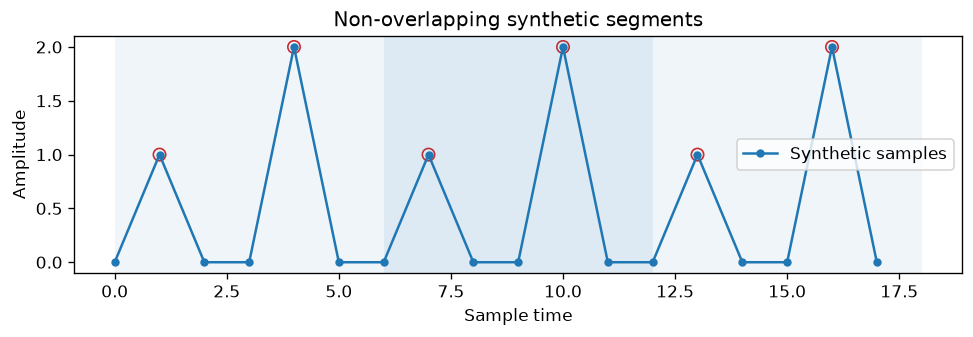

In [5]:
fig, ax = plt.subplots(figsize=(8, 2.7), layout="constrained")
ax.plot(test_time, test_values, "o-", ms=4, label="Synthetic samples")
for index, (times, values) in enumerate(test_segments):
    peaks_t, peaks = local_maxima(times, values)
    ax.scatter(peaks_t, peaks, s=55, facecolors="none", edgecolors="tab:red")
    ax.axvspan(
        6 * index, 6 * (index + 1), alpha=0.07 if index % 2 == 0 else 0.15
    )
ax.set(
    xlabel="Sample time",
    ylabel="Amplitude",
    title="Non-overlapping synthetic segments",
)
ax.legend()
plt.show()

**Diagnostic:** each shaded interval owns six different samples and two known
interior maxima. The assertions also test strict peaks placed exactly at a
segment start or final sample: those are deliberately not passed to another
segment's detector. This isolates a boundary choice rather than attributing a
lost edge maximum to a change in the system dynamics.

## 3. Recurrence matrix and mean recurrence time

For a segment's scalar peak sequence E = (e₁,…,eₙ), use
\[
R_{ij}=\mathbf{1}(|e_i-e_j|\le\epsilon),\qquad
\epsilon=0.3\,\operatorname{std}(E;\mathrm{ddof}=0).
\]
Scalar Euclidean distance is absolute difference. There is no embedding,
Theiler band, triangular mask, or removal of self-recurrence in the primary
estimate: **the main diagonal stays 1**, as specified by the distance formula.
The scope of σ and ddof are assumptions, not explicitly resolved by the paper.

A white vertical line is a **positive-length maximal run of zeros in one column**.
For recurrence rows r < s that are consecutive in that column, its length is
l = s−r−1. Primary counts require **both bounding recurrences**, excluding leading
and trailing censored zero runs. Adjacent recurrences give no positive white line.
All columns contribute line counts p(l), and Eq. (1) gives
\[
\mathrm{MRT}=\frac{\sum_{l\ge1}l\,p(l)}{\sum_{l\ge1}p(l)}.
\]
MRT counts white cells in **peak-index units**, not elapsed physical time. The
return-index lag would be l+1; it is not silently substituted for the printed
white-line definition. Boundary policy and diagonal handling are audited below.
No valid positive complete line means **MRT is undefined (NaN)**, not zero.

In [6]:
def recurrence_matrix(peaks, epsilon=None):
    peaks = np.asarray(peaks, dtype=float)
    if peaks.ndim != 1 or peaks.size == 0 or not np.all(np.isfinite(peaks)):
        raise ValueError("A nonempty finite peak sequence is required.")
    if peaks.size > MAX_MATRIX_PEAKS:
        raise MemoryError(
            "Too many peaks for the matrix; no subsampling applied."
        )
    if epsilon is None:
        epsilon = RECURRENCE_FACTOR * peaks.std(ddof=0)
    if not np.isfinite(epsilon) or epsilon < 0:
        raise ValueError(
            "The recurrence threshold must be finite and nonnegative."
        )
    return np.abs(peaks[:, None] - peaks[None, :]) <= epsilon, float(epsilon)


def white_vertical_lengths(matrix, *, include_boundary=False):
    """Count positive zero runs; default requires recurrence at both ends."""
    matrix = np.asarray(matrix)
    if (
        matrix.ndim != 2
        or matrix.shape[0] != matrix.shape[1]
        or matrix.shape[0] == 0
        or not np.all((matrix == 0) | (matrix == 1))
    ):
        raise ValueError("Provide a nonempty square binary matrix.")
    lengths = []
    for column in matrix.T:
        recurrent = np.flatnonzero(column)
        if recurrent.size:
            gaps = np.diff(recurrent) - 1
            lengths.extend(gaps[gaps > 0])
            if include_boundary:
                lengths.extend(
                    value
                    for value in (
                        recurrent[0],
                        matrix.shape[0] - 1 - recurrent[-1],
                    )
                    if value > 0
                )
        elif include_boundary:
            lengths.append(matrix.shape[0])
    return np.asarray(lengths, dtype=int)


def mrt_from_lengths(lengths):
    lengths = np.asarray(lengths, dtype=float)
    if lengths.ndim != 1:
        raise ValueError("Line lengths must be one-dimensional.")
    if lengths.size == 0:
        return float("nan")
    if (
        not np.all(np.isfinite(lengths))
        or np.any(lengths < 1)
        or np.any(lengths != np.floor(lengths))
    ):
        raise ValueError("White-line lengths must be positive integers.")
    support, frequency = np.unique(lengths, return_counts=True)
    return float(np.dot(support, frequency) / frequency.sum())

In [7]:
toy_peaks = np.array([0, 1, 0, 2, 1, 0], dtype=float)
toy_matrix, _ = recurrence_matrix(toy_peaks, epsilon=0)
expected = np.array(
    [
        [1, 0, 1, 0, 0, 1],
        [0, 1, 0, 0, 1, 0],
        [1, 0, 1, 0, 0, 1],
        [0, 0, 0, 1, 0, 0],
        [0, 1, 0, 0, 1, 0],
        [1, 0, 1, 0, 0, 1],
    ],
    dtype=bool,
)
np.testing.assert_array_equal(toy_matrix, expected)
np.testing.assert_array_equal(toy_matrix, toy_matrix.T)
assert np.all(np.diag(toy_matrix))
lengths = white_vertical_lengths(toy_matrix)
np.testing.assert_array_equal(np.sort(lengths), [1, 1, 1, 2, 2, 2, 2, 2])
np.testing.assert_allclose(mrt_from_lengths(lengths), 13 / 8)
np.testing.assert_allclose(mrt_from_lengths([1, 1, 2, 4]), 2)
inclusive, _ = recurrence_matrix([0, 1, 2], epsilon=1.0)
np.testing.assert_array_equal(inclusive, [[1, 1, 0], [1, 1, 1], [0, 1, 1]])
assert np.isnan(mrt_from_lengths(white_vertical_lengths(np.ones((5, 5)))))
assert np.isnan(mrt_from_lengths(white_vertical_lengths(np.eye(5))))
for period in (2, 4, 8):
    matrix, _ = recurrence_matrix(np.tile(np.arange(period), 4), epsilon=0)
    np.testing.assert_allclose(
        mrt_from_lengths(white_vertical_lengths(matrix)), period - 1
    )
print("Recurrence symmetry, threshold, known gaps, and MRT checks passed.")

Recurrence symmetry, threshold, known gaps, and MRT checks passed.


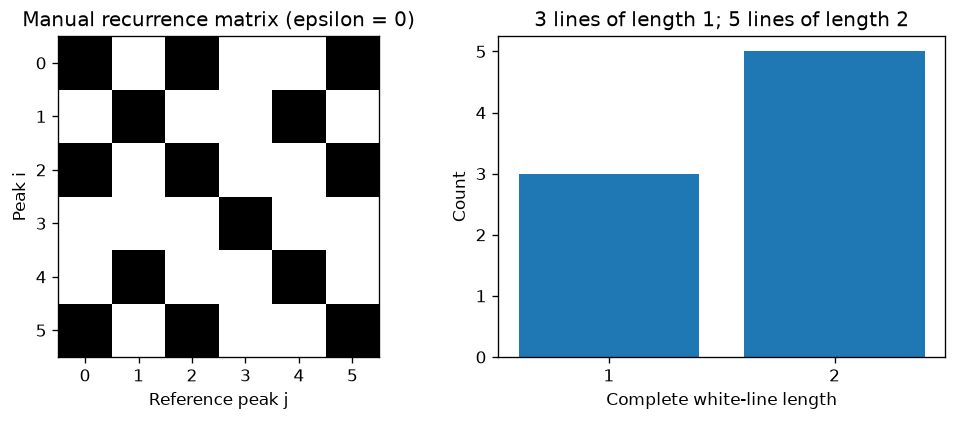

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3.4), layout="constrained")
axes[0].imshow(
    toy_matrix, cmap="binary", vmin=0, vmax=1, interpolation="nearest"
)
axes[0].set(
    xlabel="Reference peak j",
    ylabel="Peak i",
    title="Manual recurrence matrix (epsilon = 0)",
)
axes[0].set_xticks(range(6))
axes[0].set_yticks(range(6))
support, frequency = np.unique(lengths, return_counts=True)
axes[1].bar(support, frequency)
axes[1].set(
    xlabel="Complete white-line length",
    ylabel="Count",
    title="3 lines of length 1; 5 lines of length 2",
    xticks=[1, 2],
)
plt.show()

**Diagnostic:** black cells are recurrences, including the diagonal, and the
white vertical gaps bounded by them give MRT = (3×1 + 5×2)/8 = **1.625**.
This is the average count of non-recurrent peak indices in complete gaps;
it is neither a physical return time nor the return-index lag 2.625.
The unique value 2 has only its self-recurrence, so its boundary-censored gaps
do not establish a completed return under the primary convention.

In [9]:
censored_lengths = white_vertical_lengths(toy_matrix, include_boundary=True)
np.testing.assert_allclose(mrt_from_lengths(censored_lengths), 22 / 14)
masked_diagonal = toy_matrix.copy()
np.fill_diagonal(masked_diagonal, False)
np.testing.assert_allclose(
    mrt_from_lengths(white_vertical_lengths(masked_diagonal)), 7 / 3
)
show_table(
    ["Toy-matrix convention", "Line count", "MRT"],
    [
        [
            "Primary: diagonal kept, complete gaps",
            lengths.size,
            f"{mrt_from_lengths(lengths):.6f}",
        ],
        [
            "Include censored boundary runs",
            censored_lengths.size,
            f"{mrt_from_lengths(censored_lengths):.6f}",
        ],
        [
            "Set diagonal to zero (diagnostic only)",
            white_vertical_lengths(masked_diagonal).size,
            f"{mrt_from_lengths(white_vertical_lengths(masked_diagonal)):.6f}",
        ],
    ],
)

| Toy-matrix convention | Line count | MRT |
|---|---|---|
| Primary: diagonal kept, complete gaps | 8 | 1.625000 |
| Include censored boundary runs | 14 | 1.571429 |
| Set diagonal to zero (diagnostic only) | 3 | 2.333333 |

Turning the diagonal into zeros introduces and merges white gaps; it is not a
neutral removal of self-matches. Counting incomplete edge runs also changes
MRT. The primary convention follows the distance-defined diagonal and positive
complete white lines; the paper does not specify these implementation details
well enough to identify its software convention. Those uncertainties remain
open for Phase 2, rather than selecting whichever version best matches Fig. 1.

## 4. Normalized Shannon entropy

Each segment uses m equal-width bins spanning its own peak-amplitude minimum
and maximum, including empty bins. With pᵢ = countᵢ / number of peaks,
\[
H=-\sum_i p_i\log_2 p_i,\qquad \mathrm{ENT}=H/\log_2m.
\]
Zero-probability terms contribute zero. Exactly constant peaks occupy one bin
and ENT = 0 (NumPy supplies a finite artificial edge range for this degenerate
case). Empty peak sequences are undefined and are reported, not assigned a
fabricated distribution. The fixed **m = 50 is our assumption**, not a value
reported for this experiment; ENT depends on it.

In [10]:
def peak_probabilities(peaks, bins=N_BINS):
    peaks = np.asarray(peaks, dtype=float)
    if peaks.ndim != 1 or peaks.size == 0 or not np.all(np.isfinite(peaks)):
        raise ValueError("A nonempty finite peak sequence is required.")
    if not isinstance(bins, (int, np.integer)) or bins < 2:
        raise ValueError("Use at least two integer bins.")
    counts, edges = np.histogram(peaks, bins=bins)
    return counts / peaks.size, edges


def normalized_entropy(probabilities):
    p = np.asarray(probabilities, dtype=float)
    if (
        p.ndim != 1
        or p.size < 2
        or not np.all(np.isfinite(p))
        or np.any(p < 0)
        or not np.isclose(p.sum(), 1.0, rtol=1e-12, atol=1e-12)
    ):
        raise ValueError(
            "Provide a normalized nonnegative probability vector."
        )
    positive = p[p > 0]
    return float(-np.sum(positive * np.log2(positive)) / np.log2(p.size))

In [11]:
concentrated = np.zeros(N_BINS)
concentrated[0] = 1
np.testing.assert_allclose(normalized_entropy(concentrated), 0, atol=1e-14)
np.testing.assert_allclose(normalized_entropy(np.full(N_BINS, 1 / N_BINS)), 1)
np.testing.assert_allclose(
    normalized_entropy([0.5, 0.25, 0.25]), 1.5 / np.log2(3)
)
p, edges = peak_probabilities([0, 0, 0, 1, 2, 3])
np.testing.assert_allclose(p.sum(), 1)
np.testing.assert_allclose(np.diff(edges), np.diff(edges)[0])
np.testing.assert_allclose(
    normalized_entropy(peak_probabilities(np.ones(12))[0]), 0
)
print("Entropy limits, nonuniform values, and histograms verified.")

Entropy limits, nonuniform values, and histograms verified.


In [12]:
constant = np.ones(12)
near_constant = 1 + 1e-12 * np.tile([0, 1, 3, 2], 3)
rows = []
for label, peaks in (
    ("Exactly constant", constant),
    ("Tiny repeated variations", near_constant),
):
    matrix, epsilon = recurrence_matrix(peaks)
    white = white_vertical_lengths(matrix)
    rows.append(
        [
            label,
            f"{np.ptp(peaks):.3e}",
            f"{epsilon:.3e}",
            white.size,
            str(mrt_from_lengths(white)),
            f"{normalized_entropy(peak_probabilities(peaks)[0]):.6f}",
        ]
    )
show_table(
    ["Peak sequence", "Range", "epsilon", "Valid lines", "MRT", "ENT"], rows
)

| Peak sequence | Range | epsilon | Valid lines | MRT | ENT |
|---|---|---|---|---|---|
| Exactly constant | 0.000e+00 | 0.000e+00 | 0 | nan | -0.000000 |
| Tiny repeated variations | 3.000e-12 | 3.354e-13 | 24 | 3.0 | 0.354368 |

For exactly constant peaks, ε = 0 and all cells recur, so there are **no positive
white lines**: Eq. (1) has a zero denominator and MRT is undefined. A near-constant
sequence can instead give finite MRT and nonzero ENT because both ε and the bin
range rescale with its tiny variation. This numerical/scale sensitivity is
preserved in the primary estimator, with no arbitrary rounding or imported
amplitude tolerance. A constant raw signal has no isolated peaks at all, another
case kept distinct from a constant *peak sequence*.

## 5. Variance across segments — Eq. (4)

For Z = MRT or ENT, use the unweighted segment mean and
\[
V_Z=\frac{1}{k-1}\sum_{j=1}^k (Z_j-\bar Z)^2.
\]
This is a **between-segment sample variance**, not the variance of raw amplitudes,
pooled line lengths, or values across control parameters. Intermittency may give
different metrics to quiet and burst-containing segments even when their average
is similar; variance can also reflect finite estimation error or a transient.
An undefined segment metric makes its mean and variance undefined under the
strict primary rule. No undefined segment is dropped or silently imputed.

In [13]:
def sample_variance(values):
    values = np.asarray(values, dtype=float)
    if values.ndim != 1 or values.size < 2:
        raise ValueError("Sample variance requires at least two segments.")
    if not np.all(np.isfinite(values)):
        return float("nan")
    return float(np.sum((values - values.mean()) ** 2) / (values.size - 1))


np.testing.assert_allclose(sample_variance([1, 2, 3]), 1)
np.testing.assert_allclose(sample_variance([2, 2, 2]), 0)
np.testing.assert_allclose(sample_variance([1, 3]), 2)
assert np.isnan(sample_variance([1, np.nan, 3]))
try:
    sample_variance([1])
except ValueError:
    pass
else:
    raise AssertionError("Undefined one-segment variance was accepted.")
print("Sample-variance denominator and undefined-metric policy verified.")

Sample-variance denominator and undefined-metric policy verified.


## 6. Forced Brusselator — Eq. (5)

\[
\dot u_1=\mu-(\alpha+1)u_1+u_1^2u_2+I\sin(\omega t),\qquad
\dot u_2=\alpha u_1-u_1^2u_2.
\]
The same equations and model parameters are used for every condition. All starts
are independent, with identical initial concentrations and absolute forcing
phase. Uniformly sampled **u₁** supplies the primary segmented maxima. Separate
downward-zero event roots of du₁/dt are a numerical reference only; they never
fill or interpolate across segment boundaries in the primary pipeline.

In [14]:
def brusselator(time, state, amplitude):
    u1, u2 = state
    reaction = u1**2 * u2
    forcing = amplitude * np.sin(MODEL["omega"] * time)
    return (
        MODEL["mu"] - (MODEL["alpha"] + 1) * u1 + reaction + forcing,
        MODEL["alpha"] * u1 - reaction,
    )


def u1_maximum(time, state, amplitude):
    return brusselator(time, state, amplitude)[0]


u1_maximum.direction = -1
u1_maximum.terminal = False
np.testing.assert_allclose(
    brusselator(0, NUMERICS["initial_state"], 0), 0, atol=1e-14
)
np.testing.assert_allclose(
    brusselator(0, (0.3, 4.0), 0.051), (-0.0742, -0.0258)
)
forced_time = np.pi / (2 * MODEL["omega"])
np.testing.assert_allclose(
    brusselator(forced_time, NUMERICS["initial_state"], 0.051),
    (0.051, 0),
    atol=1e-14,
)
print("Unforced equilibrium, component values, and forcing sign verified.")

Unforced equilibrium, component values, and forcing sign verified.


In [15]:
def simulate_brusselator(amplitude):
    started = perf_counter()
    dt = NUMERICS["sample_dt"]
    duration = NUMERICS["segment_duration"] * NUMERICS["segments"]
    count = round(duration / dt)
    times = NUMERICS["transient"] + dt * np.arange(count)
    early = np.arange(0.0, NUMERICS["transient"], 1.0)
    solution = solve_ivp(
        brusselator,
        (0.0, NUMERICS["transient"] + duration),
        NUMERICS["initial_state"],
        args=(amplitude,),
        events=u1_maximum,
        t_eval=np.r_[early, times],
        method=NUMERICS["method"],
        rtol=NUMERICS["rtol"],
        atol=NUMERICS["atol"],
        max_step=NUMERICS["max_step"],
    )
    if not solution.success or not np.all(np.isfinite(solution.y)):
        raise RuntimeError(f"I={amplitude}: {solution.message}")
    roots = (solution.t_events[0] > times[0]) & (
        solution.t_events[0] < NUMERICS["transient"] + duration
    )
    return {
        "time": solution.t[early.size :],
        "state": solution.y[:, early.size :],
        "early_time": solution.t[: early.size],
        "early_u1": solution.y[0, : early.size],
        "root_time": solution.t_events[0][roots],
        "root_peaks": solution.y_events[0][roots, 0],
        "nfev": solution.nfev,
        "seconds": perf_counter() - started,
    }

In [16]:
def analyze_segments(time, values):
    results = []
    for times, signal in nonoverlap_segments(
        time, values, NUMERICS["segment_duration"]
    ):
        peak_time, peaks = local_maxima(times, signal)
        if peaks.size:
            matrix, epsilon = recurrence_matrix(peaks)
            white = white_vertical_lengths(matrix)
            mrt = mrt_from_lengths(white)
            entropy = normalized_entropy(peak_probabilities(peaks)[0])
            line_count = white.size
        else:
            epsilon, mrt, entropy, line_count = np.nan, np.nan, np.nan, 0
        results.append(
            {
                "start": times[0],
                "stop": times[0] + NUMERICS["segment_duration"],
                "samples": times.size,
                "peak_time": peak_time,
                "peaks": peaks,
                "epsilon": epsilon,
                "lines": line_count,
                "mrt": mrt,
                "entropy": entropy,
            }
        )
    return results


def summarize_segments(segments):
    mrt = np.array([s["mrt"] for s in segments])
    entropy = np.array([s["entropy"] for s in segments])
    return {
        "mrt": float(mrt.mean()),
        "vmrt": sample_variance(mrt),
        "entropy": float(entropy.mean()),
        "vent": sample_variance(entropy),
        "invalid_mrt": np.flatnonzero(~np.isfinite(mrt)).tolist(),
        "invalid_entropy": np.flatnonzero(~np.isfinite(entropy)).tolist(),
    }


undefined_test = summarize_segments(
    [{"mrt": 1.0, "entropy": 0.2}, {"mrt": np.nan, "entropy": 0.3}]
)
assert np.isnan(undefined_test["mrt"]) and np.isnan(undefined_test["vmrt"])
assert undefined_test["invalid_mrt"] == [1]
np.testing.assert_allclose(undefined_test["vent"], 0.005)

### 6.1 Selected-condition baseline before a sweep

Selected I = 0.05105, 0.05122, 0.0515, 0.0517 sample the lower, middle, and upper
parts of Fig. 1. These are chosen control values, **not assigned regime labels**;
periodic windows may occur inside a broadly chaotic parameter range. The table
reports every segment, including undefined entries. Peak arrays and summaries
are retained in memory; only four selected full traces are kept for diagnostics.
No simulation or analysis cache is written to disk.

In [17]:
selected_runs, records = {}, {}
for label, amplitude in SELECTED.items():
    simulation = simulate_brusselator(amplitude)
    segments = analyze_segments(simulation["time"], simulation["state"][0])
    summary = summarize_segments(segments)
    record = {
        "segments": segments,
        "summary": summary,
        "root_peaks": simulation["root_peaks"],
        "seconds": simulation["seconds"],
    }
    records[amplitude] = record
    selected_runs[label] = {
        "amplitude": amplitude,
        "simulation": simulation,
        "record": record,
    }
    print(
        f"Selected I={amplitude:.6f}: {len(segments)} segments; "
        f"{sum(s['peaks'].size for s in segments)} peaks; "
        f"{simulation['seconds']:.1f} s",
        flush=True,
    )
rows = []
for label, case in selected_runs.items():
    for index, segment in enumerate(case["record"]["segments"], 1):
        rows.append(
            [
                label,
                index,
                f"[{segment['start']:.0f}, {segment['stop']:.0f})",
                segment["samples"],
                segment["peaks"].size,
                segment["lines"],
                f"{segment['mrt']:.6f}",
                f"{segment['entropy']:.6f}",
            ]
        )
show_table(
    [
        "Condition",
        "Segment",
        "Time interval",
        "Samples",
        "Peaks",
        "Complete white lines",
        "MRT",
        "ENT",
    ],
    rows,
)

Selected I=0.051050: 10 segments; 2196 peaks; 5.6 s


Selected I=0.051220: 10 segments; 2196 peaks; 5.7 s


Selected I=0.051500: 10 segments; 2196 peaks; 5.7 s


Selected I=0.051700: 10 segments; 2197 peaks; 5.7 s


| Condition | Segment | Time interval | Samples | Peaks | Complete white lines | MRT | ENT |
|---|---|---|---|---|---|---|---|
| low | 1 | [10000, 12000) | 40000 | 220 | 11880 | 3.000000 | 0.442938 |
| low | 2 | [12000, 14000) | 40000 | 219 | 11772 | 3.000000 | 0.442536 |
| low | 3 | [14000, 16000) | 40000 | 220 | 11880 | 3.000000 | 0.442938 |
| low | 4 | [16000, 18000) | 40000 | 220 | 11880 | 3.000000 | 0.442938 |
| low | 5 | [18000, 20000) | 40000 | 219 | 11772 | 3.000000 | 0.443335 |
| low | 6 | [20000, 22000) | 40000 | 220 | 11880 | 3.000000 | 0.442938 |
| low | 7 | [22000, 24000) | 40000 | 219 | 11772 | 3.000000 | 0.443335 |
| low | 8 | [24000, 26000) | 40000 | 219 | 11772 | 3.000000 | 0.443335 |
| low | 9 | [26000, 28000) | 40000 | 220 | 11880 | 3.000000 | 0.442938 |
| low | 10 | [28000, 30000) | 40000 | 220 | 11880 | 3.000000 | 0.442938 |
| middle | 1 | [10000, 12000) | 40000 | 220 | 12636 | 2.764957 | 0.579657 |
| middle | 2 | [12000, 14000) | 40000 | 219 | 12556 | 2.752469 | 0.582123 |
| middle | 3 | [14000, 16000) | 40000 | 220 | 12636 | 2.760684 | 0.582267 |
| middle | 4 | [16000, 18000) | 40000 | 220 | 12608 | 2.771098 | 0.580135 |
| middle | 5 | [18000, 20000) | 40000 | 219 | 12528 | 2.762931 | 0.581671 |
| middle | 6 | [20000, 22000) | 40000 | 220 | 12636 | 2.760684 | 0.581441 |
| middle | 7 | [22000, 24000) | 40000 | 220 | 12664 | 2.759002 | 0.582267 |
| middle | 8 | [24000, 26000) | 40000 | 219 | 12474 | 2.774892 | 0.579049 |
| middle | 9 | [26000, 28000) | 40000 | 220 | 12664 | 2.754580 | 0.581441 |
| middle | 10 | [28000, 30000) | 40000 | 219 | 12528 | 2.758621 | 0.581671 |
| upper-middle | 1 | [10000, 12000) | 40000 | 220 | 15086 | 2.154183 | 0.783658 |
| upper-middle | 2 | [12000, 14000) | 40000 | 219 | 15566 | 2.035076 | 0.775995 |
| upper-middle | 3 | [14000, 16000) | 40000 | 220 | 16100 | 1.959006 | 0.790511 |
| upper-middle | 4 | [16000, 18000) | 40000 | 220 | 14672 | 2.239504 | 0.747252 |
| upper-middle | 5 | [18000, 20000) | 40000 | 219 | 15102 | 2.121308 | 0.768655 |
| upper-middle | 6 | [20000, 22000) | 40000 | 220 | 15800 | 2.013671 | 0.787136 |
| upper-middle | 7 | [22000, 24000) | 40000 | 219 | 15550 | 2.036399 | 0.771919 |
| upper-middle | 8 | [24000, 26000) | 40000 | 219 | 15128 | 2.118985 | 0.774343 |
| upper-middle | 9 | [26000, 28000) | 40000 | 220 | 14888 | 2.200161 | 0.746226 |
| upper-middle | 10 | [28000, 30000) | 40000 | 220 | 15186 | 2.128408 | 0.775037 |
| upper | 1 | [10000, 12000) | 40000 | 220 | 14134 | 2.362106 | 0.606310 |
| upper | 2 | [12000, 14000) | 40000 | 219 | 14194 | 2.320699 | 0.606367 |
| upper | 3 | [14000, 16000) | 40000 | 220 | 14142 | 2.360204 | 0.606310 |
| upper | 4 | [16000, 18000) | 40000 | 220 | 14134 | 2.362106 | 0.606310 |
| upper | 5 | [18000, 20000) | 40000 | 219 | 13928 | 2.380816 | 0.606367 |
| upper | 6 | [20000, 22000) | 40000 | 220 | 14136 | 2.364743 | 0.606310 |
| upper | 7 | [22000, 24000) | 40000 | 219 | 13928 | 2.383975 | 0.606367 |
| upper | 8 | [24000, 26000) | 40000 | 220 | 14132 | 2.368808 | 0.606310 |
| upper | 9 | [26000, 28000) | 40000 | 220 | 14126 | 2.370239 | 0.606310 |
| upper | 10 | [28000, 30000) | 40000 | 220 | 14142 | 2.366426 | 0.606310 |

### 6.2 Local solver, sampling, and peak-extraction audit

At each selected condition, restart the same retained state at the same absolute
forcing time and compare a 200-time-unit interval with rtol = 10⁻¹¹,
atol = 10⁻¹³ and max_step = 0.5. Event roots provide reference peak amplitudes;
samples at 0.05 and 0.025 test extraction accuracy. Only peaks with neighbors
inside the interval are paired. This is local numerical accuracy, not statistical
convergence or pointwise agreement of indefinitely long chaotic trajectories.

In [18]:
solver_rows, reference_errors = [], []
for label, case in selected_runs.items():
    source = case["simulation"]
    start = float(source["time"][0])
    times = start + np.arange(8_001) * 0.025
    pair = []
    for rtol, atol, step in ((1e-9, 1e-11, 1.0), (1e-11, 1e-13, 0.5)):
        solution = solve_ivp(
            brusselator,
            (start, float(times[-1])),
            source["state"][:, 0],
            args=(case["amplitude"],),
            method="DOP853",
            events=u1_maximum,
            t_eval=times,
            rtol=rtol,
            atol=atol,
            max_step=step,
        )
        if not solution.success:
            raise RuntimeError(solution.message)
        pair.append(solution)
    baseline, refined = pair
    masks = [
        (s.t_events[0] > start + 0.05) & (s.t_events[0] < times[-1] - 0.05)
        for s in pair
    ]
    assert masks[0].sum() == masks[1].sum() > 0
    error = np.max(
        np.abs(
            baseline.y_events[0][masks[0], 0]
            - refined.y_events[0][masks[1], 0]
        )
    )
    state_error = np.max(np.abs(baseline.y - refined.y))
    assert state_error < 1e-5, "Investigate the local solver discrepancy."
    reference_errors.append(float(error))
    sample_errors = []
    event_time = refined.t_events[0][masks[1]]
    event_peaks = refined.y_events[0][masks[1], 0]
    for stride in (2, 1):
        ts, peaks = local_maxima(times[::stride], refined.y[0, ::stride])
        keep = (ts > start + 0.05) & (ts < times[-1] - 0.05)
        ts, peaks = ts[keep], peaks[keep]
        assert ts.size == event_time.size
        assert np.max(np.abs(ts - event_time)) <= 0.05
        sample_errors.append(np.max(np.abs(peaks - event_peaks)))
    solver_rows.append(
        [
            label,
            event_time.size,
            f"{state_error:.3e}",
            f"{error:.3e}",
            *(f"{value:.3e}" for value in sample_errors),
        ]
    )
show_table(
    [
        "Condition",
        "Paired maxima",
        "Max state error",
        "Max root-peak error",
        "Sample error 0.05",
        "Sample error 0.025",
    ],
    solver_rows,
)

| Condition | Paired maxima | Max state error | Max root-peak error | Sample error 0.05 | Sample error 0.025 |
|---|---|---|---|---|---|
| low | 22 | 5.998e-08 | 9.794e-09 | 8.378e-06 | 2.985e-06 |
| middle | 22 | 4.583e-08 | 7.232e-09 | 1.141e-05 | 2.813e-06 |
| upper-middle | 22 | 8.482e-07 | 1.224e-07 | 1.188e-05 | 2.619e-06 |
| upper | 22 | 2.738e-07 | 4.382e-08 | 1.104e-05 | 3.168e-06 |

### 6.3 Transient and output-sampling sensitivity

The diagnostic plot shows discarded dynamics and retained peak evolution.
Then, separately compare the two retained halves (five segments each) and
coarsen the **same retained samples** to Δt = 0.1. No parameter or forcing phase
is changed and no alternate trajectory is selected to improve Fig. 1. Half-record
variance changes are descriptive, not independent error bars or evidence that
10,000 time units necessarily removes every long transient.

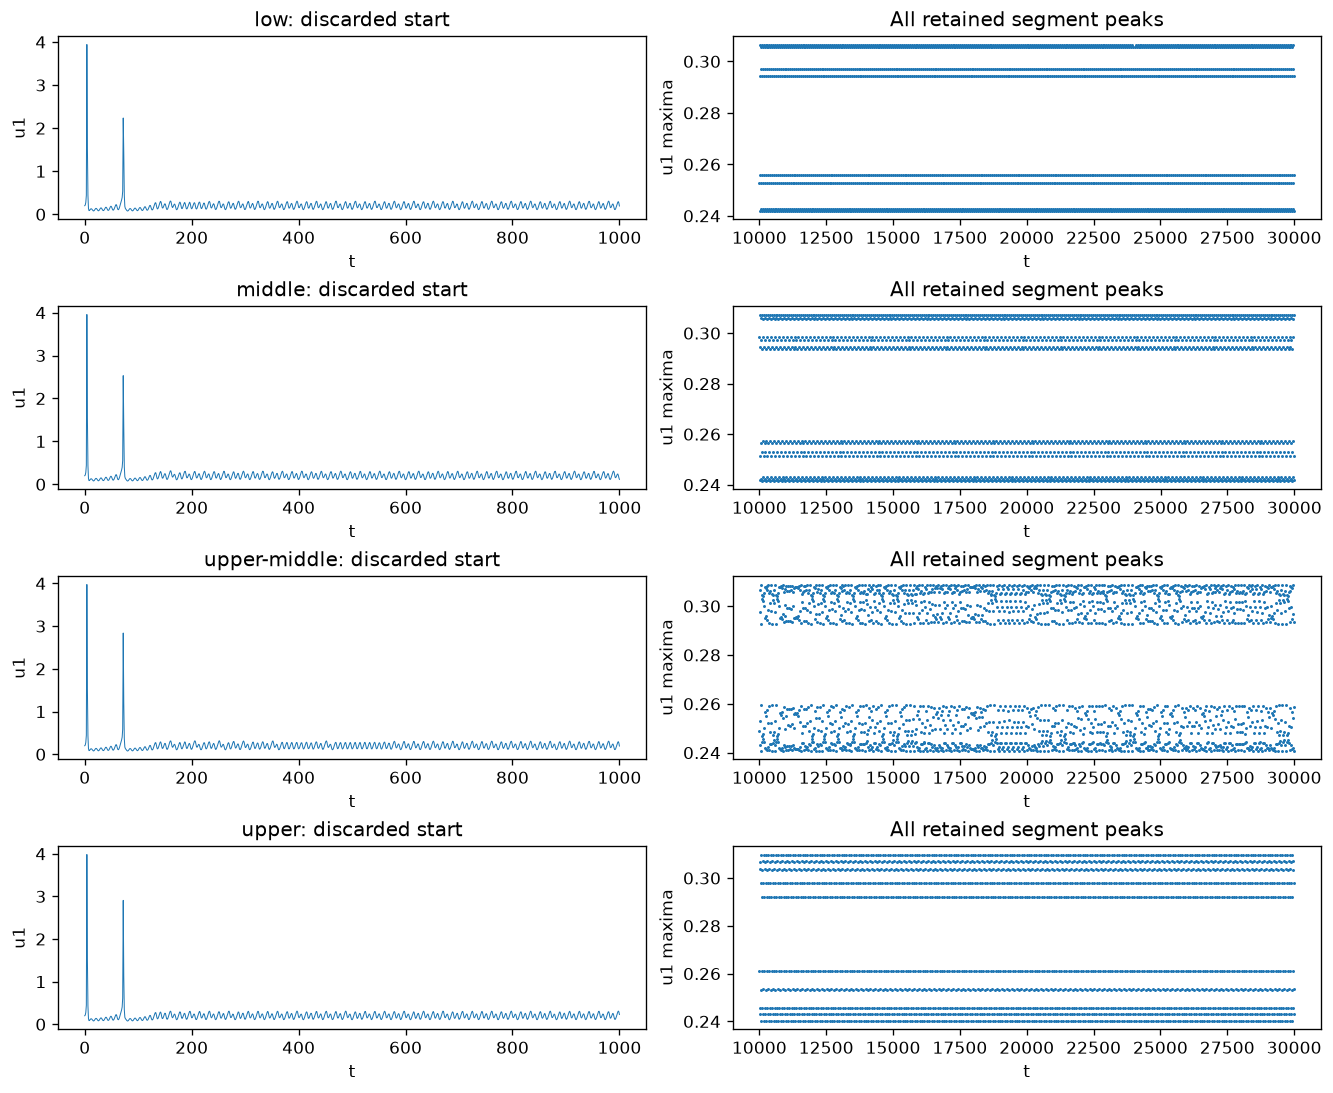

In [19]:
fig, axes = plt.subplots(4, 2, figsize=(11, 9), layout="constrained")
for row, (label, case) in enumerate(selected_runs.items()):
    simulation, segments = case["simulation"], case["record"]["segments"]
    show = simulation["early_time"] <= 1_000
    axes[row, 0].plot(
        simulation["early_time"][show], simulation["early_u1"][show], lw=0.6
    )
    axes[row, 0].set(
        xlabel="t", ylabel="u1", title=f"{label}: discarded start"
    )
    peaks_t = np.concatenate([s["peak_time"] for s in segments])
    peaks = np.concatenate([s["peaks"] for s in segments])
    axes[row, 1].plot(peaks_t, peaks, ".", ms=1.6)
    axes[row, 1].set(
        xlabel="t", ylabel="u1 maxima", title="All retained segment peaks"
    )
plt.show()

**Diagnostic:** discarded concentration dynamics are separated from the retained
maxima, so large initial excursions cannot be mistaken for stationary behavior.
Repeated levels versus varying amplitude bands can be inspected, but their
appearance alone does not prove periodic stability or chaos. The following
half-record and sampling tables quantify limits of this finite baseline.

In [20]:
sensitivity_rows = []
for label, case in selected_runs.items():
    simulation, segments = case["simulation"], case["record"]["segments"]
    comparisons = [
        ("first 5 segments", segments[:5]),
        ("last 5 segments", segments[5:]),
        ("all, dt=0.05", segments),
        (
            "same data, dt=0.1",
            analyze_segments(
                simulation["time"][::2], simulation["state"][0, ::2]
            ),
        ),
    ]
    for name, subset in comparisons:
        summary = summarize_segments(subset)
        sensitivity_rows.append(
            [
                label,
                name,
                sum(s["peaks"].size for s in subset),
                *(
                    f"{summary[key]:.6g}"
                    for key in ("mrt", "vmrt", "entropy", "vent")
                ),
                len(summary["invalid_mrt"]),
                len(summary["invalid_entropy"]),
            ]
        )
show_table(
    [
        "Condition",
        "Comparison",
        "Peaks",
        "Mean MRT",
        "VMRT",
        "Mean ENT",
        "VENT",
        "Invalid MRT",
        "Invalid ENT",
    ],
    sensitivity_rows,
)

| Condition | Comparison | Peaks | Mean MRT | VMRT | Mean ENT | VENT | Invalid MRT | Invalid ENT |
|---|---|---|---|---|---|---|---|---|
| low | first 5 segments | 1098 | 3 | 0 | 0.442937 | 7.9692e-08 | 0 | 0 |
| low | last 5 segments | 1098 | 3 | 0 | 0.443097 | 4.71431e-08 | 0 | 0 |
| low | all, dt=0.05 | 2196 | 3 | 0 | 0.443017 | 6.34547e-08 | 0 | 0 |
| low | same data, dt=0.1 | 2196 | 3 | 0 | 0.443017 | 6.34547e-08 | 0 | 0 |
| middle | first 5 segments | 1098 | 2.76243 | 4.60099e-05 | 0.581171 | 1.43044e-06 | 0 | 0 |
| middle | last 5 segments | 1098 | 2.76156 | 6.06023e-05 | 0.581174 | 1.52521e-06 | 0 | 0 |
| middle | all, dt=0.05 | 2196 | 2.76199 | 4.75944e-05 | 0.581172 | 1.31362e-06 | 0 | 0 |
| middle | same data, dt=0.1 | 2196 | 2.76199 | 4.75944e-05 | 0.581172 | 1.31362e-06 | 0 | 0 |
| upper-middle | first 5 segments | 1098 | 2.10182 | 0.0117322 | 0.773214 | 0.000277701 | 0 | 0 |
| upper-middle | last 5 segments | 1098 | 2.09952 | 0.0056741 | 0.770932 | 0.000225611 | 0 | 0 |
| upper-middle | all, dt=0.05 | 2196 | 2.10067 | 0.00773761 | 0.772073 | 0.000225141 | 0 | 0 |
| upper-middle | same data, dt=0.1 | 2195 | 2.09943 | 0.00761399 | 0.772035 | 0.000234225 | 0 | 0 |
| upper | first 5 segments | 1098 | 2.35719 | 0.000486795 | 0.606333 | 9.61866e-10 | 0 | 0 |
| upper | last 5 segments | 1099 | 2.37084 | 5.84175e-05 | 0.606322 | 6.41244e-10 | 0 | 0 |
| upper | all, dt=0.05 | 2197 | 2.36401 | 0.000294091 | 0.606327 | 7.48118e-10 | 0 | 0 |
| upper | same data, dt=0.1 | 2197 | 2.35758 | 0.000101637 | 0.603914 | 1.75062e-06 | 0 | 0 |

### 6.4 Convention sensitivity at fixed trajectories

Recompute segment MRT with censored boundary runs included, and with ε based on
the pooled peak standard deviation for that condition. Both are labeled
alternatives to the primary complete-line, segment-σ estimate. The diagonal is
kept in these numerical records. The manual diagonal-masking example above
already shows why replacing self-matches with white cells changes the metric.
No alternative is chosen because it happens to resemble the paper better.

In [21]:
convention_rows = []
for label, case in selected_runs.items():
    segments = case["record"]["segments"]
    pooled = np.concatenate([s["peaks"] for s in segments])
    for convention in ("primary", "include edge runs", "pooled peak sigma"):
        values = []
        for segment in segments:
            epsilon = (
                RECURRENCE_FACTOR * pooled.std(ddof=0)
                if convention == "pooled peak sigma"
                else None
            )
            matrix, _ = recurrence_matrix(segment["peaks"], epsilon=epsilon)
            white = white_vertical_lengths(
                matrix, include_boundary=convention == "include edge runs"
            )
            values.append(mrt_from_lengths(white))
        convention_rows.append(
            [
                label,
                convention,
                f"{np.mean(values):.6f}",
                f"{sample_variance(values):.6g}",
                int(np.sum(~np.isfinite(values))),
            ]
        )
show_table(
    ["Condition", "MRT convention", "Mean MRT", "VMRT", "Undefined"],
    convention_rows,
)

| Condition | MRT convention | Mean MRT | VMRT | Undefined |
|---|---|---|---|---|
| low | primary | 3.000000 | 0 | 0 |
| low | include edge runs | 2.972875 | 1.60983e-08 | 0 |
| low | pooled peak sigma | 3.000000 | 0 | 0 |
| middle | primary | 2.761992 | 4.75944e-05 | 0 |
| middle | include edge runs | 2.741840 | 5.41236e-05 | 0 |
| middle | pooled peak sigma | 2.761992 | 4.75944e-05 | 0 |
| upper-middle | primary | 2.100670 | 0.00773761 | 0 |
| upper-middle | include edge runs | 2.098254 | 0.00747945 | 0 |
| upper-middle | pooled peak sigma | 2.100323 | 0.00710917 | 0 |
| upper | primary | 2.364012 | 0.000294091 | 0 |
| upper | include edge runs | 2.354347 | 0.000308954 | 0 |
| upper | pooled peak sigma | 2.367807 | 1.60688e-05 | 0 |

## 7. Preliminary Figure 1(a–c) reproduction

The grid contains 17 uniformly spaced interior controls plus the four selected
conditions, all within **0.051 < I < 0.0518**. Selected simulations are reused in
memory. Remaining simulations are discarded after their compact peak records
and segment summaries are extracted. This is a coarse preliminary sweep, not a
fine critical-parameter estimate. σ, segmentation, m, initial state, and solver
settings remain unchanged across the grid.

In [22]:
for index, amplitude in enumerate(CONTROL_VALUES, 1):
    amplitude = float(amplitude)
    if amplitude not in records:
        simulation = simulate_brusselator(amplitude)
        segments = analyze_segments(simulation["time"], simulation["state"][0])
        records[amplitude] = {
            "segments": segments,
            "summary": summarize_segments(segments),
            "root_peaks": simulation["root_peaks"],
            "seconds": simulation["seconds"],
        }
    summary = records[amplitude]["summary"]
    print(
        f"I={amplitude:.7f} ({index}/{len(CONTROL_VALUES)}): "
        f"MRT={summary['mrt']:.5f}, VMRT={summary['vmrt']:.4g}, "
        f"ENT={summary['entropy']:.5f}, VENT={summary['vent']:.4g}",
        flush=True,
    )

I=0.0510100 (1/21): MRT=3.00000, VMRT=0, ENT=0.44294, VENT=7.084e-08


I=0.0510500 (2/21): MRT=3.00000, VMRT=0, ENT=0.44302, VENT=6.345e-08


I=0.0510587 (3/21): MRT=3.00000, VMRT=0, ENT=0.46324, VENT=4.094e-06


I=0.0511075 (4/21): MRT=3.00000, VMRT=0, ENT=0.44294, VENT=7.084e-08


I=0.0511563 (5/21): MRT=3.00000, VMRT=0, ENT=0.48716, VENT=9.316e-09


...

I=0.0516438 (17/21): MRT=1.99131, VMRT=0.01431, ENT=0.79939, VENT=8.449e-05


I=0.0516925 (18/21): MRT=2.11959, VMRT=0.009419, ENT=0.80003, VENT=4.74e-05


I=0.0517000 (19/21): MRT=2.36401, VMRT=0.0002941, ENT=0.60633, VENT=7.481e-10


I=0.0517413 (20/21): MRT=2.16817, VMRT=0.007223, ENT=0.81151, VENT=3.735e-05


I=0.0517900 (21/21): MRT=2.36382, VMRT=0.01376, ENT=0.81661, VENT=4.123e-05


### 7.1 Peak-repeat diagnostic for the route to bounded complexity

As a separate check, search all candidate peak periods q = 1,…,64 in the
last 512 **event-refined reference peaks**, which avoid sample-grid amplitude
jitter and gaps from segmented edge exclusions. The maximum lag-q difference
must be below a declared empirical scale, ten times the larger of the local
root-refinement discrepancy and rtol × peak amplitude + atol. This is not a
universal error bound or a new complexity measure. A finite repeating tail
supports a periodic interpretation; failure to close does **not** prove chaos.
MRT need not equal q−1 when its ε merges nearby peak levels.

In [23]:
peak_scale = max(np.max(np.abs(r["root_peaks"])) for r in records.values())
REPEAT_TOLERANCE = 10 * max(
    max(reference_errors), NUMERICS["atol"] + NUMERICS["rtol"] * peak_scale
)
period_rows = []
for amplitude, record in sorted(records.items()):
    tail = record["root_peaks"][-512:]
    matches = []
    errors = []
    for period in range(1, 65):
        error = np.max(np.abs(tail[period:] - tail[:-period]))
        errors.append(error)
        if error <= REPEAT_TOLERANCE:
            matches.append(period)
    record["candidate_period"] = matches[0] if matches else None
    period_rows.append(
        [
            f"{amplitude:.7f}",
            str(record["candidate_period"]) if matches else "no closure <=64",
            f"{min(errors):.3e}",
            f"{np.ptp(tail):.6f}",
        ]
    )
print(f"Peak-repeat tolerance (diagnostic only): {REPEAT_TOLERANCE:.3e}")
show_table(
    [
        "I",
        "Smallest tested peak period",
        "Smallest lag residual",
        "Peak range",
    ],
    period_rows,
)

Peak-repeat tolerance (diagnostic only): 1.224e-06


| I | Smallest tested peak period | Smallest lag residual | Peak range |
|---|---|---|---|
| 0.0510100 | 8 | 8.573e-11 | 0.064410 |
| 0.0510500 | 8 | 7.965e-11 | 0.064669 |
| 0.0510587 | 8 | 6.689e-09 | 0.064723 |
| 0.0511075 | 8 | 5.205e-09 | 0.065013 |
| 0.0511563 | 8 | 9.462e-11 | 0.065286 |
| 0.0512050 | 16 | 1.576e-08 | 0.065777 |
| 0.0512200 | 16 | 2.673e-10 | 0.065906 |
| 0.0512538 | 64 | 5.815e-08 | 0.066159 |
| 0.0513025 | no closure <=64 | 3.551e-03 | 0.066516 |
| 0.0513513 | no closure <=64 | 6.560e-03 | 0.066869 |
| 0.0514000 | no closure <=64 | 7.753e-03 | 0.067267 |
| 0.0514488 | no closure <=64 | 8.525e-03 | 0.067758 |
| 0.0514975 | no closure <=64 | 7.552e-05 | 0.067920 |
| 0.0515000 | no closure <=64 | 1.110e-02 | 0.068125 |
| 0.0515463 | no closure <=64 | 1.371e-02 | 0.068479 |
| 0.0515950 | no closure <=64 | 1.501e-02 | 0.068830 |
| 0.0516438 | no closure <=64 | 1.629e-02 | 0.069192 |
| 0.0516925 | no closure <=64 | 1.728e-02 | 0.069543 |
| 0.0517000 | 20 | 4.880e-09 | 0.069653 |
| 0.0517413 | no closure <=64 | 1.912e-02 | 0.069951 |
| 0.0517900 | no closure <=64 | 1.954e-02 | 0.070281 |

### 7.2 Figure 1(a–c) — Bifurcation, mean metrics, and sample variances

Panel (a) shows the retained segmented u₁ maxima. Color is **raw peak count per
shared amplitude-display bin on a logarithmic color scale**, an explicit plotting
choice; it is not claimed to match the paper's unspecified occurrence-color
normalization. These 256 display bins do not change the **50 entropy bins**.
Panels (b,c) use blue unweighted segment means and red k−1 sample variances.
Every primary segment is included; undefined metrics remain gaps, with their
indices reported in the audit. No extreme-event parameter range is explored.

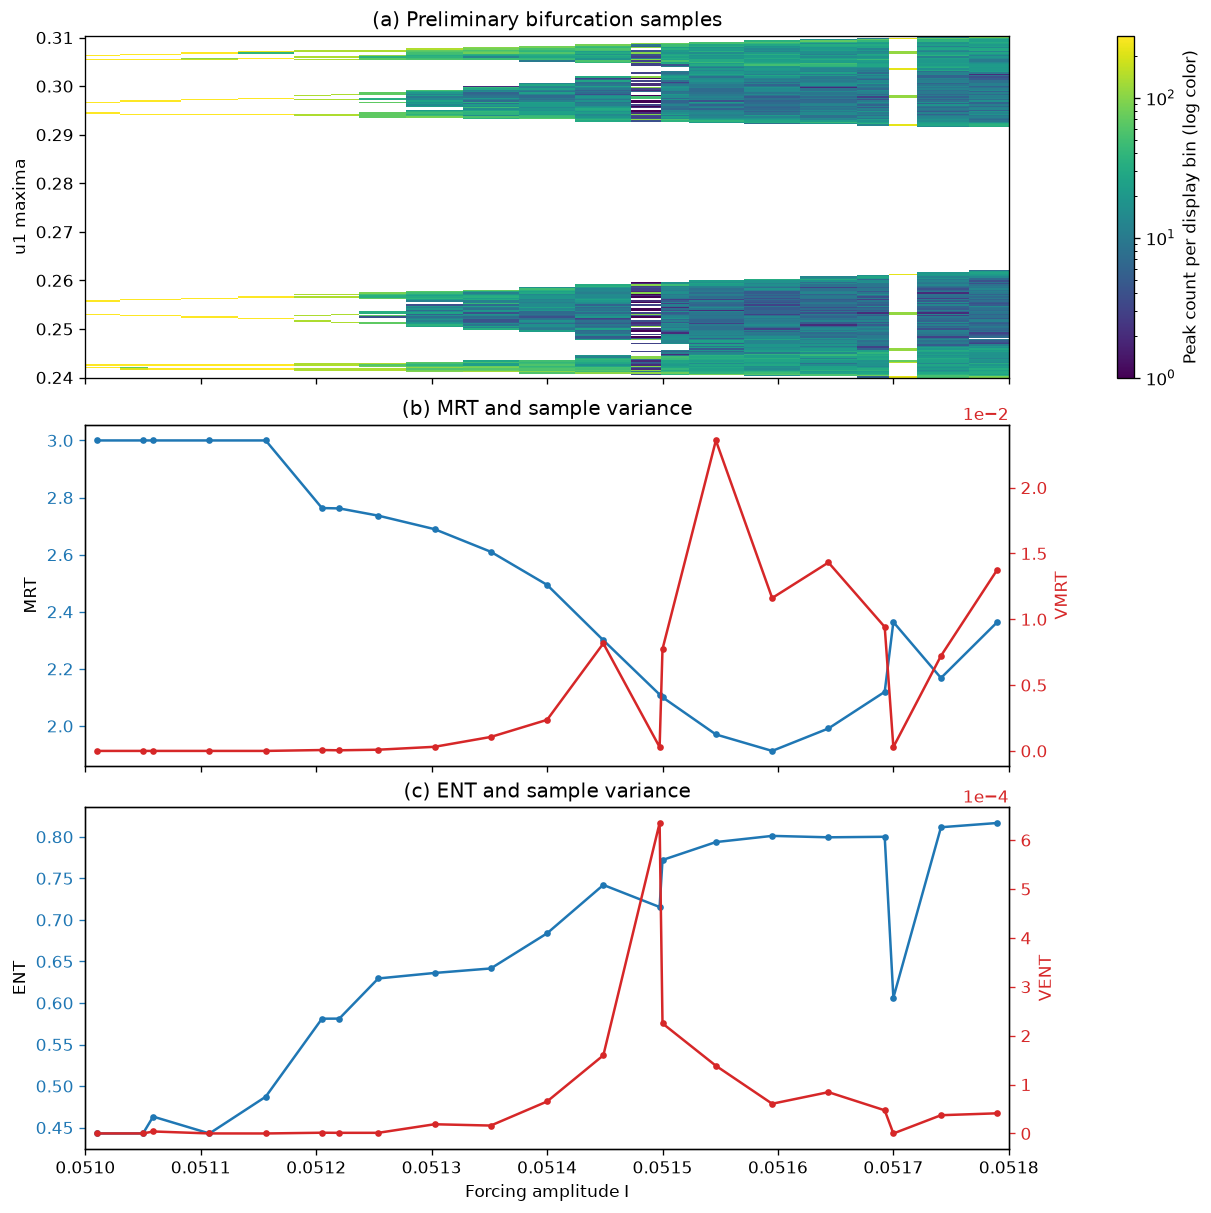

In [24]:
parameters = np.array(sorted(records))
all_peaks = [
    np.concatenate([s["peaks"] for s in records[p]["segments"]])
    for p in parameters
]
amplitude_edges = np.linspace(
    min(v.min() for v in all_peaks), max(v.max() for v in all_peaks), 257
)
counts = np.array(
    [np.histogram(v, bins=amplitude_edges)[0] for v in all_peaks]
)
parameter_edges = np.r_[
    parameters[0] - (parameters[1] - parameters[0]) / 2,
    (parameters[:-1] + parameters[1:]) / 2,
    parameters[-1] + (parameters[-1] - parameters[-2]) / 2,
]
fig, axes = plt.subplots(
    3, 1, figsize=(10, 10), sharex=True, layout="constrained"
)
mesh = axes[0].pcolormesh(
    parameter_edges,
    amplitude_edges,
    np.ma.masked_equal(counts.T, 0),
    norm=LogNorm(vmin=1, vmax=counts.max()),
    cmap="viridis",
)
fig.colorbar(mesh, ax=axes[0], label="Peak count per display bin (log color)")
axes[0].set(ylabel="u1 maxima", title="(a) Preliminary bifurcation samples")
variance_axes = []
for row, (mean_key, variance_key, label) in enumerate(
    (("mrt", "vmrt", "MRT"), ("entropy", "vent", "ENT")), 1
):
    means = [records[p]["summary"][mean_key] for p in parameters]
    variances = [records[p]["summary"][variance_key] for p in parameters]
    axes[row].plot(parameters, means, ".-", color="tab:blue")
    axes[row].set(
        ylabel=label, title=f"({'bc'[row - 1]}) {label} and sample variance"
    )
    axes[row].tick_params(axis="y", colors="tab:blue")
    twin = axes[row].twinx()
    twin.plot(parameters, variances, ".-", color="tab:red")
    twin.set_ylabel(variance_key.upper(), color="tab:red")
    twin.tick_params(axis="y", colors="tab:red")
    twin.ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
    variance_axes.append(twin)
for ax in axes:
    ax.set_xlim(0.051, 0.0518)
    ax.ticklabel_format(axis="x", useOffset=False)
axes[-1].set_xlabel("Forcing amplitude I")
plt.show()

**Figure:** preliminary Fig. 1(a–c), with u₁ and 21 independent-start controls.
**Observation:** low-I repeated bands split into richer amplitude sets; mean MRT
falls from 3 to about 1.9–2.4 while ENT rises from about 0.443 toward 0.8, with a
periodic-window dip at I = 0.0517.
**Scientific meaning:** finite-tail checks support peak-period doubling 8→16 and
a period-20 window, while segment variances are generally larger in non-closing
records; neither a variance feature nor non-closure alone proves a bifurcation.
**Reproduction status:** **partially reproduced**; the broad dynamics and metric
trends agree qualitatively, but the coarse grid, unresolved author conventions,
and variance magnitudes prevent an exact quantitative curve comparison.

## 8. Preliminary scientific and execution audit

Validate the reported sample counts, equal physical segment durations, metric
bounds, and all undefined-segment indices. The largest recurrence matrix is
reported to make the memory requirement explicit; subtraction/absolute-value
evaluation may briefly allocate two float-distance arrays of the reported size. The 2,000-peak guard refuses
an oversized matrix rather than silently dropping peaks or changing the metric.

In [25]:
expected_samples = round(
    NUMERICS["segment_duration"] * NUMERICS["segments"] / NUMERICS["sample_dt"]
)
audit_rows = []
for amplitude, record in sorted(records.items()):
    segments, summary = record["segments"], record["summary"]
    assert len(segments) == NUMERICS["segments"]
    assert sum(s["samples"] for s in segments) == expected_samples
    for index, segment in enumerate(segments):
        expected_start = (
            NUMERICS["transient"] + index * NUMERICS["segment_duration"]
        )
        np.testing.assert_allclose(segment["start"], expected_start)
        assert np.all(
            (segment["peak_time"] > segment["start"])
            & (segment["peak_time"] < segment["stop"] - NUMERICS["sample_dt"])
        )
        if np.isfinite(segment["entropy"]):
            assert -1e-14 <= segment["entropy"] <= 1 + 1e-14
        if np.isfinite(segment["mrt"]):
            assert segment["mrt"] >= 1
    audit_rows.append(
        [
            f"{amplitude:.7f}",
            sum(s["peaks"].size for s in segments),
            *(
                f"{summary[key]:.6g}"
                for key in ("mrt", "vmrt", "entropy", "vent")
            ),
            str(summary["invalid_mrt"]),
            str(summary["invalid_entropy"]),
        ]
    )
show_table(
    [
        "I",
        "Retained peaks",
        "Mean MRT",
        "VMRT",
        "Mean ENT",
        "VENT",
        "Undefined MRT indices (0-based)",
        "Undefined ENT indices",
    ],
    audit_rows,
)
max_peaks = max(
    s["peaks"].size for r in records.values() for s in r["segments"]
)
print(
    "Simulated conditions:",
    len(records),
    "; total retained samples:",
    expected_samples * len(records),
)
print("Largest segment recurrence matrix:", (max_peaks, max_peaks))
print(
    f"Largest Boolean matrix: {max_peaks**2 / 2**20:.3f} MiB; "
    f"distance temporary: {8 * max_peaks**2 / 2**20:.3f} MiB"
)
print("No simulation caches or separate summary documents were written.")

| I | Retained peaks | Mean MRT | VMRT | Mean ENT | VENT | Undefined MRT indices (0-based) | Undefined ENT indices |
|---|---|---|---|---|---|---|---|
| 0.0510100 | 2196 | 3 | 0 | 0.442937 | 7.08374e-08 | [] | [] |
| 0.0510500 | 2196 | 3 | 0 | 0.443017 | 6.34547e-08 | [] | [] |
| 0.0510587 | 2197 | 3 | 0 | 0.463241 | 4.09444e-06 | [] | [] |
| 0.0511075 | 2196 | 3 | 0 | 0.442937 | 7.08374e-08 | [] | [] |
| 0.0511563 | 2197 | 3 | 0 | 0.487164 | 9.31625e-09 | [] | [] |
| 0.0512050 | 2196 | 2.76318 | 6.67958e-05 | 0.581089 | 1.53038e-06 | [] | [] |
| 0.0512200 | 2196 | 2.76199 | 4.75944e-05 | 0.581172 | 1.31362e-06 | [] | [] |
| 0.0512538 | 2196 | 2.73663 | 9.19317e-05 | 0.629504 | 1.33575e-06 | [] | [] |
| 0.0513025 | 2196 | 2.68934 | 0.000312899 | 0.636115 | 1.88525e-05 | [] | [] |
| 0.0513513 | 2196 | 2.61012 | 0.00106158 | 0.641556 | 1.61817e-05 | [] | [] |
| 0.0514000 | 2196 | 2.49423 | 0.00236024 | 0.683839 | 6.54072e-05 | [] | [] |
| 0.0514488 | 2197 | 2.30028 | 0.0081664 | 0.742062 | 0.000159799 | [] | [] |
| 0.0514975 | 2197 | 2.11016 | 0.000291373 | 0.71549 | 0.000634949 | [] | [] |
| 0.0515000 | 2196 | 2.10067 | 0.00773761 | 0.772073 | 0.000225141 | [] | [] |
| 0.0515463 | 2196 | 1.97035 | 0.0235846 | 0.793659 | 0.000138487 | [] | [] |
| 0.0515950 | 2197 | 1.91269 | 0.0116138 | 0.801094 | 6.07818e-05 | [] | [] |
| 0.0516438 | 2196 | 1.99131 | 0.0143148 | 0.799387 | 8.44937e-05 | [] | [] |
| 0.0516925 | 2197 | 2.11959 | 0.00941933 | 0.800035 | 4.74031e-05 | [] | [] |
| 0.0517000 | 2197 | 2.36401 | 0.000294091 | 0.606327 | 7.48118e-10 | [] | [] |
| 0.0517413 | 2196 | 2.16817 | 0.00722349 | 0.811508 | 3.7346e-05 | [] | [] |
| 0.0517900 | 2197 | 2.36382 | 0.0137631 | 0.816614 | 4.12349e-05 | [] | [] |

Simulated conditions: 21 ; total retained samples: 8400000
Largest segment recurrence matrix: (220, 220)
Largest Boolean matrix: 0.046 MiB; distance temporary: 0.369 MiB
No simulation caches or separate summary documents were written.


### Phase 1 Conclusions and Phase 2 Handoff

1. **Mathematical measures are implemented and validated.** Synthetic boundaries
   and known peaks verify non-overlap and independent extraction. Manual recurrence
   tests verify symmetry, the inclusive threshold, diagonal policy, and complete
   white-line frequencies (MRT = 13/8 in the six-peak example). Entropy limits and
   k−1 sample variances pass analytical tests. Undefined segment metrics propagate
   to undefined means/variances with their indices retained; none of the **210**
   primary simulated segments is undefined. Constant peaks and no completed returns
   can both have undefined MRT, so NaN alone has no dynamical classification.
2. **Period-doubling is supported at the sampled resolution.** Event-refined tails
   repeat with peak periods 8 at I = 0.05105 and 16 at 0.05122. A period-64 candidate
   occurs at 0.05125375, but the coarse grid does not resolve a full sequence of
   intermediate bifurcations. Many larger-I records fail all tested periods 1–64,
   consistent with bounded aperiodic dynamics; this is not a proof of chaos.
   I = 0.0517 instead has a repeating period-20 tail, demonstrating why the whole
   upper parameter range must not receive a single imposed label.
3. **MRT/ENT and their variances give distinct information.** At I = 0.05105,
   mean MRT = 3, VMRT = 0, and ENT ≈ 0.443. At 0.0515 they are approximately
   2.101, 0.00774, and 0.772, with VENT ≈ 2.25 × 10⁻⁴. The larger variances in
   this non-closing record distinguish it from the lower-I repeated case, but
   finite peak counts, threshold geometry, and sample-grid errors also contribute.
   MRT does not simply count orbit period when ε merges nearby peak amplitudes.
4. **Figure 1 is partially reproduced.** The u₁ maxima occupy about 0.240–0.310,
   with repeated bands, broadening, and a periodic window. Declining mean MRT,
   increasing ENT, and generally small regular versus larger aperiodic segment
   variances agree qualitatively with the paper. Exact plateau heights, variance
   magnitudes, transition locations, and occurrence colors are not verified:
   original numerical data and the authors' T/k/m and implementation are absent.
5. **The numerical baseline is explicit, not an author protocol.** μ = 0.2,
   α = 1.114, ω = 0.69 and Eq. (5) are reported. Initial state (0.2, 5.57), zero
   forcing phase, DOP853 (rtol 10⁻⁹, atol 10⁻¹¹, max_step 1), Δt = 0.05,
   a 10,000-time-unit discard, T = 2,000, k = 10, m = 50, per-segment peak σ
   with ddof = 0, complete white gaps, and unweighted blue-curve means are our
   assumptions. Each condition retains 400,000 samples; the largest matrix is
   only 220 × 220 and is discarded before the next segment.
6. **Important discrepancies and numerical limits remain.** Local tightening
   gives maximum state/root-peak differences about 8.5 × 10⁻⁷ / 1.2 × 10⁻⁷;
   this does not establish global statistical convergence. At the period-20
   window, coarsening the same output from Δt = 0.05 to 0.1 changes VENT from
   about 7.5 × 10⁻¹⁰ to 1.75 × 10⁻⁶. Using pooled rather than segment peak σ
   changes VMRT there from about 2.94 × 10⁻⁴ to 1.61 × 10⁻⁵. Thus tiny amplitude
   differences and recurrence/histogram boundaries can substantially affect a
   variance without a new physical regime. Half-record mean similarity is not
   proof of transient adequacy or convergence of the variance.
7. **Prepare Phase 2 without starting it.** Seek the authors' diagonal/censoring,
   σ, T/k/m, and aggregation conventions if available. Test segment/record length,
   initial conditions, bin count, and peak resolution systematically, preserving
   invalid segments and the present literal estimator as reference. Refine the
   bounded-chaos baseline and the period-20 window before making extreme-event
   discrimination claims. This phase does not test that later claim: no Fig. 2,
   3, or 8, extreme-event-range sweep, other model, sliding-window extension,
   persistent simulation cache, or separate summary document has been created.

# Phase 2 — Brusselator extreme-event verification and variance comparison

The first **47 cells, including their saved outputs and interpretations**, remain
unchanged. Section III.B, Fig. 2, and the Appendix's Fig. 8(a,b) of the original
PDF are the primary sources for this phase; the existing research discussion
provides supporting context. The positive chemical parameters and exact Eq. (5)
remain unchanged. No other model or two-parameter Fig. 3 is implemented.

The reference estimator remains the Phase 1 convention: independent sample-grid
maxima inside half-open, non-overlapping segments; ε = 0.3 × population standard
deviation of segment peaks; diagonal retained; positive complete white gaps;
50 equal-width entropy bins; and sample variance with denominator k−1.
**An undefined segment still makes its mean/variance undefined.** Valid counts
are reported, not used to silently switch to a valid-only average.

Phases are executed in separate kernels, restoring verified definitions for
Phase 2 rather than rerunning the expensive Phase 1 sweep. A standard
whole-notebook run remains possible. Earlier execution counts are historical.
All scientific interpretation remains here, with no separate summary document.

## 9. Stage A — Representative conditions and explicit protocols

Reported reference intervals are bounded chaos (0.051, 0.0519), rare extremes
(0.0520, 0.0545), and frequent large amplitudes (0.0546, 0.056). They are **not
record labels**: measured amplitudes, counts, and distributions will be inspected
before the main sweep. We select I = **0.0515, 0.0521, 0.0553** before inspecting
their Phase 2 results. Fig. 8 does not give its Brusselator I, so 0.0521 is an
explicit reproduction assumption rather than an author parameter specification.

The main sweep retains **20,000** time units after the Phase 1 10,000 discard,
with T = 2,000 and k = 10. Representatives retain **60,000** after the same
discard (k = 30), with 20,000 prefixes for controlled main-curve comparisons.
All start independently from (0.2, 5.57), forcing phase zero; DOP853 tolerances,
max_step = 1 and Δt = 0.05 are unchanged. The full-reference threshold is
Q_th = mean(all full-record maxima) + 6 × population std(maxima),
separate from MRT/ENT. Counts are peaks, not independent burst episodes.
Global peaks for Q/PDF/bifurcation exclude only the full record's endpoints;
independent metric segments also exclude their own boundary peaks. Both counts
are retained so a boundary omission is not mistaken for a missing event.

The initial Fig. 8 display is fixed at **t = 40,000–70,000**, covering the final
30,000 retained time units, without searching for favorable bursts. Every fifth
raw sample is cached for drawing (display spacing 0.25); all segment-peak
positions remain available and threshold-crossing amplitudes are overlaid so
that drawing does not hide narrow observed maxima. Statistics use Δt = 0.05.

In [12]:
import hashlib
import inspect
import json
from pathlib import Path

P2_SETTINGS = {
    "initial_state": NUMERICS["initial_state"],
    "transient": NUMERICS["transient"],
    "duration": 20_000.0,
    "sample_dt": NUMERICS["sample_dt"],
    "method": NUMERICS["method"],
    "rtol": NUMERICS["rtol"],
    "atol": NUMERICS["atol"],
    "max_step": NUMERICS["max_step"],
    "trace_start": 40_000.0,
    "trace_duration": 0.0,
    "display_stride": 5,
}
P2_REPRESENTATIVES = {
    "lower reference": 0.0515,
    "rare-range reference": 0.0521,
    "upper reference": 0.0553,
}
P2_INITIALS = (NUMERICS["initial_state"], (0.1, 6.0), (0.3, 5.0))
P2_CACHE = Path("seralan_2026_cache")
P2_CACHE.mkdir(exist_ok=True)
P2_CACHE_ACTIVITY = {"hits": 0, "computed": 0}
P2_CACHE_USED = set()
print("Reference model:", MODEL)
print("Main numerical settings:", P2_SETTINGS)
print("Primary T/k/m:", NUMERICS["segment_duration"], 10, N_BINS)

Reference model: {'mu': 0.2, 'alpha': 1.114, 'omega': 0.69}
Main numerical settings: {'initial_state': (0.2, 5.57), 'transient': 10000.0, 'duration': 20000.0, 'sample_dt': 0.05, 'method': 'DOP853', 'rtol': 1e-09, 'atol': 1e-11, 'max_step': 1.0, 'trace_start': 40000.0, 'trace_duration': 0.0, 'display_stride': 5}
Primary T/k/m: 2000.0 10 50


### 9.1 Compact peaks with exact independent-segment boundaries

A global peak's midpoint, left plateau edge, and right plateau edge are saved.
For a segment's integer sample interval [a,b), the peak is retained only if
**left > a and right < b−1**. This exactly reproduces independent `find_peaks`
inside each segment, including flat peaks touching a boundary; it does not
borrow a neighbor across segments. Re-segmentation can therefore use the same
trajectory without losing peaks at old boundaries. A second compact peak set
from every other original sample supports a controlled Δt = 0.1 comparison.

Cache metadata identifies model parameters, every numerical setting, versions,
and hashes of the actual equation/integration/extraction code. Atomic compressed
files contain peaks, their indices, optional short display data and one restart
state. Full long sampled trajectories and recurrence matrices are not stored.
Changing entropy bins or recurrence conventions recomputes metrics from the
same peak input rather than invalidating an unchanged physical simulation.

Printed integration timings are creation times saved in each cache entry,
not the elapsed time for loading a warm cache. The cache path is relative to
the notebook kernel directory (`reproduce_paper/` for this saved execution).

In [13]:
def sample_peak_data(values):
    indices, properties = find_peaks(values, plateau_size=True)
    return {
        "index": indices,
        "left": properties["left_edges"],
        "right": properties["right_edges"],
        "peaks": np.asarray(values)[indices],
    }


def segments_from_peak_data(
    record,
    *,
    duration=2_000.0,
    length=None,
    bins=50,
    sigma_scope="segment",
    stride=1,
):
    """Reconstruct independently bracketed maxima from exact sample indices."""
    if stride not in (1, 2) or sigma_scope not in ("segment", "pooled"):
        raise ValueError("Use stride 1/2 and segment/pooled peak sigma.")
    dt = float(record["sample_dt"]) * stride
    length = float(record["duration"]) if length is None else float(length)
    if length > float(record["duration"]) or length <= 0:
        raise ValueError("The requested length must fit the cached record.")
    count, per_segment = round(length / dt), round(duration / dt)
    if (
        per_segment < 3
        or count % per_segment
        or not np.isclose(count * dt, length, rtol=0, atol=1e-8)
        or not np.isclose(per_segment * dt, duration, rtol=0, atol=1e-8)
    ):
        raise ValueError(
            "Equal complete segments and integer sample counts required."
        )
    prefix = "coarse_" if stride == 2 else ""
    data = {
        name: record[prefix + name]
        for name in ("index", "left", "right", "peaks")
    }
    segments = []
    for start in range(0, count, per_segment):
        stop = start + per_segment
        keep = (data["left"] > start) & (data["right"] < stop - 1)
        segments.append(
            {
                "start": float(record["transient"]) + start * dt,
                "stop": float(record["transient"]) + stop * dt,
                "samples": per_segment,
                "peaks": data["peaks"][keep],
                "peak_time": float(record["transient"])
                + data["index"][keep] * dt,
            }
        )
    pooled = np.concatenate([s["peaks"] for s in segments])
    for segment in segments:
        peaks = segment["peaks"]
        if peaks.size:
            epsilon = (
                RECURRENCE_FACTOR * pooled.std(ddof=0)
                if sigma_scope == "pooled"
                else None
            )
            matrix, epsilon = recurrence_matrix(peaks, epsilon)
            white = white_vertical_lengths(matrix)
            segment.update(
                epsilon=epsilon,
                lines=white.size,
                mrt=mrt_from_lengths(white),
                entropy=normalized_entropy(peak_probabilities(peaks, bins)[0]),
            )
        else:
            segment.update(epsilon=np.nan, lines=0, mrt=np.nan, entropy=np.nan)
    return segments

In [14]:
synthetic = np.array(
    [0, 1, 0, 0, 2, 0, 3, 3, 3, 0, 2, 0, 0, 4, 0, 0, 2, 0, 0, 3, 0, 0, 4, 0],
    dtype=float,
)
primary = sample_peak_data(synthetic)
coarse = sample_peak_data(synthetic[::2])
test_record = {
    **primary,
    **{"coarse_" + k: v for k, v in coarse.items()},
    "sample_dt": np.array(1.0),
    "transient": np.array(0.0),
    "duration": np.array(24.0),
}
for duration, stride in ((6, 1), (12, 1), (12, 2)):
    direct = nonoverlap_segments(
        np.arange(0, 24, stride), synthetic[::stride], duration
    )
    reconstructed = segments_from_peak_data(
        test_record, duration=duration, stride=stride
    )
    for (times, values), cached in zip(direct, reconstructed, strict=True):
        pt, pv = local_maxima(times, values)
        np.testing.assert_array_equal(cached["peak_time"], pt)
        np.testing.assert_array_equal(cached["peaks"], pv)
print("Compact peaks match independent extraction, including plateaus.")

Compact peaks match independent extraction, including plateaus.


In [15]:
def simulate_phase2(amplitude, settings):
    """Integrate the verified equations and compress sampled extrema."""
    started = perf_counter()
    dt, duration = settings["sample_dt"], settings["duration"]
    count = round(duration / dt)
    if not np.isclose(count * dt, duration):
        raise ValueError("Retained duration must be divisible by sample_dt.")
    times = settings["transient"] + dt * np.arange(count)
    solution = solve_ivp(
        brusselator,
        (0.0, settings["transient"] + duration),
        settings["initial_state"],
        args=(amplitude,),
        events=u1_maximum,
        t_eval=times,
        method=settings["method"],
        rtol=settings["rtol"],
        atol=settings["atol"],
        max_step=settings["max_step"],
    )
    if not solution.success or not np.all(np.isfinite(solution.y)):
        raise RuntimeError(f"I={amplitude}: {solution.message}")
    primary = sample_peak_data(solution.y[0])
    coarse = sample_peak_data(solution.y[0, ::2])
    anchor = max(
        0, int(primary["index"][np.argmax(primary["peaks"])]) - round(20 / dt)
    )
    if settings["trace_duration"]:
        stop = settings["trace_start"] + settings["trace_duration"]
        if stop > settings["transient"] + duration:
            raise ValueError("Display window exceeds the retained record.")
        shown = np.flatnonzero(
            (times >= settings["trace_start"]) & (times < stop)
        )
        shown = shown[:: settings["display_stride"]]
    else:
        shown = np.array([], dtype=int)
    record = {
        **primary,
        **{"coarse_" + key: value for key, value in coarse.items()},
        "sample_dt": np.array(dt),
        "duration": np.array(duration),
        "transient": np.array(settings["transient"]),
        "samples": np.array(count),
        "trace_time": times[shown],
        "trace_u1": solution.y[0, shown],
        "anchor_time": np.array(times[anchor]),
        "anchor_state": solution.y[:, anchor],
        "nfev": np.array(solution.nfev),
        "seconds": np.array(perf_counter() - started),
    }
    direct = analyze_segments(times, solution.y[0])
    reconstructed = segments_from_peak_data(record)
    for left, right in zip(direct, reconstructed, strict=True):
        np.testing.assert_array_equal(left["peaks"], right["peaks"])
        np.testing.assert_array_equal(left["peak_time"], right["peak_time"])
        np.testing.assert_allclose(
            [left["mrt"], left["entropy"]],
            [right["mrt"], right["entropy"]],
            equal_nan=True,
        )
    return record

In [16]:
def cached_phase2(amplitude, settings):
    """Use only a metadata-exact compressed simulation record."""
    functions = (brusselator, u1_maximum, sample_peak_data, simulate_phase2)
    source = "\n".join(inspect.getsource(f) for f in functions)
    metadata = {
        "schema": 1,
        "model": "Brusselator",
        "parameter": float(amplitude),
        "parameters": MODEL,
        "settings": settings,
        "numpy": np.__version__,
        "scipy": scipy.__version__,
        "python": platform.python_version(),
        "source_sha256": hashlib.sha256(source.encode()).hexdigest(),
        "observable": "u1",
        "extrema": "sampled maxima with plateau edges",
    }
    serialized = json.dumps(metadata, sort_keys=True)
    key = hashlib.sha256(serialized.encode()).hexdigest()[:20]
    path = P2_CACHE / f"brusselator_{amplitude:.9f}_{key}.npz"
    if path.exists():
        with np.load(path, allow_pickle=False) as saved:
            if saved["metadata"].item() != serialized:
                raise RuntimeError("Cached simulation metadata mismatch.")
            record = {
                name: saved[name].copy()
                for name in saved.files
                if name != "metadata"
            }
        P2_CACHE_ACTIVITY["hits"] += 1
    else:
        record = simulate_phase2(amplitude, settings)
        if not np.all(np.isfinite(record["peaks"])):
            raise RuntimeError("Nonfinite peaks cannot be cached.")
        temporary = path.with_suffix(".tmp")
        with temporary.open("wb") as stream:
            np.savez_compressed(stream, metadata=serialized, **record)
        temporary.replace(path)
        P2_CACHE_ACTIVITY["computed"] += 1
    P2_CACHE_USED.add(path.name)
    return record

In [17]:
def describe_record(
    record,
    *,
    length=None,
    duration=2_000.0,
    bins=50,
    sigma_scope="segment",
    stride=1,
):
    segments = segments_from_peak_data(
        record,
        length=length,
        duration=duration,
        bins=bins,
        sigma_scope=sigma_scope,
        stride=stride,
    )
    summary = summarize_segments(segments)
    segment_peak_count = sum(s["peaks"].size for s in segments)
    length = float(record["duration"]) if length is None else float(length)
    prefix = "coarse_" if stride == 2 else ""
    dt = float(record["sample_dt"]) * stride
    limit = round(length / dt)
    keep = (record[prefix + "left"] > 0) & (
        record[prefix + "right"] < limit - 1
    )
    peaks = record[prefix + "peaks"][keep]
    times = float(record["transient"]) + record[prefix + "index"][keep] * dt
    threshold = peaks.mean() + 6 * peaks.std(ddof=0) if peaks.size else np.nan
    count = int(np.count_nonzero(peaks > threshold))
    summary.update(
        {
            "segments": segments,
            "peaks": peaks,
            "peak_time": times,
            "threshold": float(threshold),
            "count": count,
            "rate": count / length,
            "large_count": int(np.count_nonzero(peaks > 1)),
            "duration": length,
            "peak_count": peaks.size,
            "segment_peak_count": segment_peak_count,
        }
    )
    return summary

In [18]:
p2_representatives, p2_rep_metrics = {}, {}
for amplitude in P2_REPRESENTATIVES.values():
    settings = {**P2_SETTINGS, "duration": 60_000.0}
    if amplitude == 0.0521:
        settings["trace_duration"] = 30_000.0
    record = cached_phase2(amplitude, settings)
    metrics = describe_record(record)
    p2_representatives[amplitude] = record
    p2_rep_metrics[amplitude] = metrics
    print(
        f"Representative I={amplitude:.6f}: {metrics['peak_count']} peaks; "
        f"{metrics['count']} above Q; {record['seconds'].item():.1f} s",
        flush=True,
    )
show_table(
    [
        "I",
        "Retained t",
        "Segments",
        "Peaks",
        "Q",
        "Peaks > Q",
        "Rate / 1000 t",
        "Peaks > fixed 1",
        "Mean MRT",
        "VMRT",
        "Mean ENT",
        "VENT",
        "Invalid MRT",
        "Invalid ENT",
    ],
    [
        [
            amplitude,
            int(m["duration"]),
            len(m["segments"]),
            m["peak_count"],
            f"{m['threshold']:.5f}",
            m["count"],
            f"{1_000 * m['rate']:.4f}",
            m["large_count"],
            *(f"{m[key]:.6g}" for key in ("mrt", "vmrt", "entropy", "vent")),
            str(m["invalid_mrt"]),
            str(m["invalid_entropy"]),
        ]
        for amplitude, m in p2_rep_metrics.items()
    ],
)

Representative I=0.051500: 6589 peaks; 0 above Q; 14.1 s


Representative I=0.052100: 6570 peaks; 19 above Q; 14.0 s


Representative I=0.055300: 6364 peaks; 0 above Q; 15.7 s


| I | Retained t | Segments | Peaks | Q | Peaks > Q | Rate / 1000 t | Peaks > fixed 1 | Mean MRT | VMRT | Mean ENT | VENT | Invalid MRT | Invalid ENT |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| 0.0515 | 60000 | 30 | 6589 | 0.44082 | 0 | 0.0000 | 0 | 2.14058 | 0.0100932 | 0.764468 | 0.000208719 | [] | [] |
| 0.0521 | 60000 | 30 | 6570 | 1.18035 | 19 | 0.3167 | 19 | 2.86552 | 2.35966 | 0.589694 | 0.11953 | [] | [] |
| 0.0553 | 60000 | 30 | 6364 | 3.28636 | 0 | 0.0000 | 219 | 1.87552 | 0.0268243 | 0.368455 | 0.000259334 | [] | [] |

### 9.2 Pilot numerical checkpoint

The table is evidence about the *simulated* records, not a validation of labels
assigned by a reference interval. A fixed height **1** separates the observed
bounded Fig. 1 peaks (about 0.24–0.31) from excursions of order 3; it is an
auxiliary count for frequency comparisons and is neither Q_th nor an input to
MRT/ENT. A record with high large-excursion rate can have no strict Q crossings
because its sample-derived Q moves upward. Conversely, an isolated crossing
does not demonstrate interior crisis. Representative plots and the full-record
PDF will be inspected before the parameter sweep.

**Observed checkpoint:** the full 60,000-time-unit records give 0, 19, and 0
Q crossings at 0.0515, 0.0521, and 0.0553. Their fixed-height (>1) counts are
0, 19, and 219, so the last record has much more frequent large maxima despite
no strict Q crossing. VMRT is approximately 0.0101, 2.36, and 0.0268; VENT is
0.000209, 0.1195, and 0.000259. Thus the representative comparison supports the
variance claim under this convention, while absolute MRT (about 1.9–2.9) differs
substantially from the larger values plotted in the paper's large-event region.
That discrepancy is retained; neither the white-line definition nor σ is tuned.


### 9.3 Diagnostic regime inspection before the sweep

The left panels display the chronological local-maxima sequences over the
complete retained 60,000 time units; the right panels show their normalized
amplitude PDFs. This is a temporal peak diagnostic, not a substituted continuous
u₁ trace. Full raw signal behavior for the selected rare-range condition is
examined separately in Fig. 8 below. Frequency comparisons use complete-record
counts and rates, not the apparent density of plotted points alone.

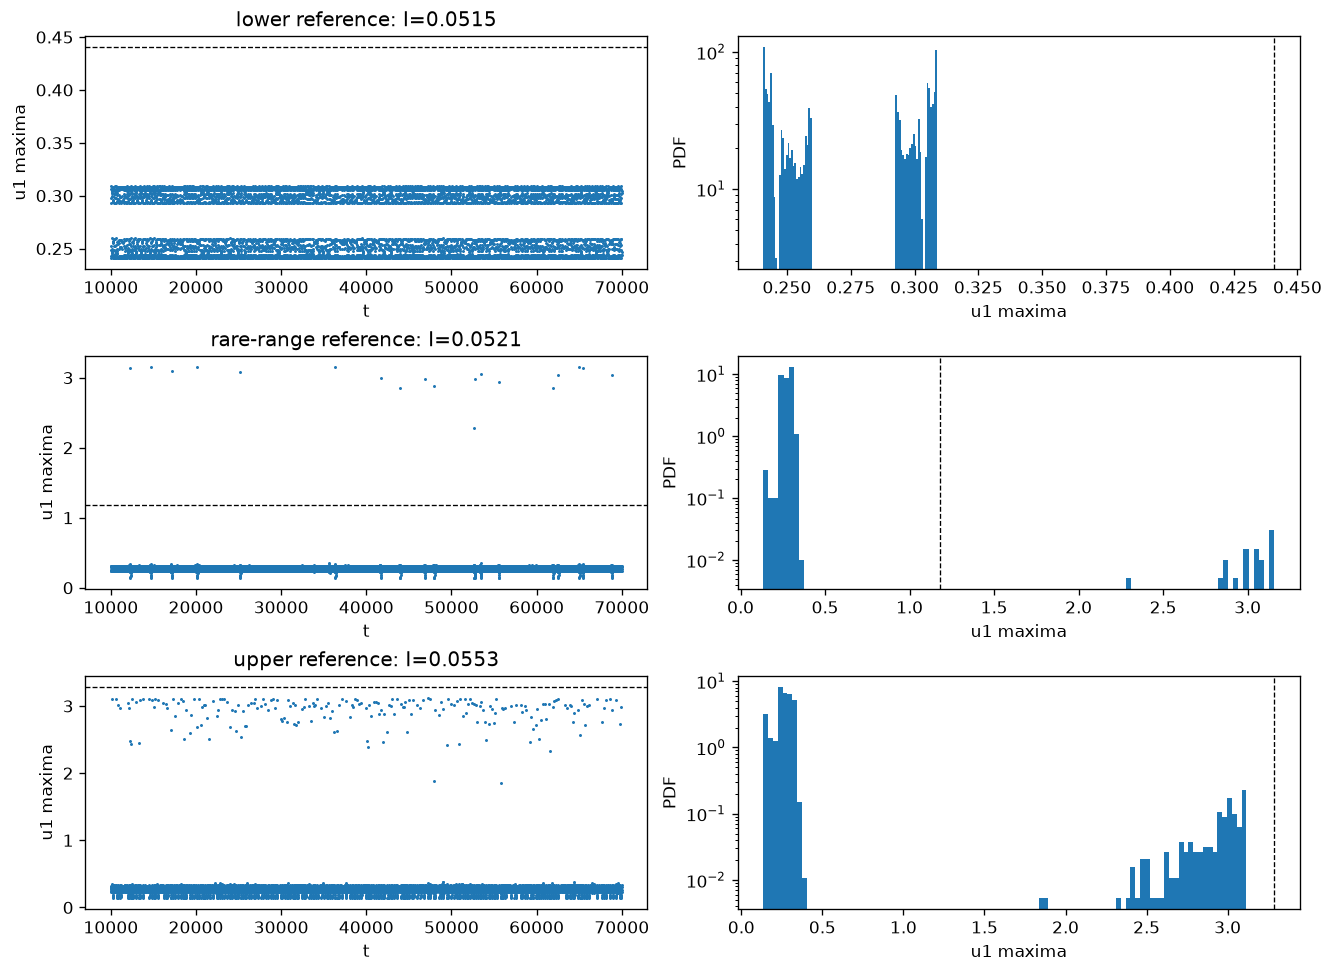

In [19]:
fig, axes = plt.subplots(3, 2, figsize=(11, 8), layout="constrained")
for row, (label, amplitude) in enumerate(P2_REPRESENTATIVES.items()):
    metrics = p2_rep_metrics[amplitude]
    axes[row, 0].plot(metrics["peak_time"], metrics["peaks"], ".", ms=1.6)
    axes[row, 0].axhline(metrics["threshold"], color="k", ls="--", lw=0.8)
    axes[row, 0].set(
        xlabel="t", ylabel="u1 maxima", title=f"{label}: I={amplitude}"
    )
    p, edges = peak_probabilities(metrics["peaks"], bins=100)
    widths = np.diff(edges)
    occupied = p > 0
    axes[row, 1].bar(
        (edges[:-1] + widths / 2)[occupied],
        (p / widths)[occupied],
        width=widths[occupied],
    )
    axes[row, 1].axvline(metrics["threshold"], color="k", ls="--", lw=0.8)
    axes[row, 1].set(xlabel="u1 maxima", ylabel="PDF", yscale="log")
plt.show()

**Diagnostic:** the low-amplitude support is contrasted with a sparse high tail
and a record with more frequent large maxima. The fixed-height count increases
from 19 to 219 across the latter two records, while the moving Q changes the
strict extreme classification. These are observed amplitude regimes; the plot
does not establish a positive Lyapunov exponent or prove an interior crisis.

## 10. Stage B — Figure 8(a,b): explicit extreme-event verification

Reproduce only the Brusselator panels at **I = 0.0521**, an assumption because
the original caption does not supply I. The full statistical record is
[10,000,70,000); display [40,000,70,000) is fixed to the published temporal
scale before looking for events. The red/magenta markers are measured maxima
from the original Δt = 0.05 analysis, overlaid on the 0.25-spaced drawing samples.
Q is the full-record mean peak plus six population standard deviations.

The PDF uses **100 equal-width bins over the complete full-record peak range**,
an explicitly chosen plotting resolution, distinct from the 50 bins per segment
used in ENT. Density is p/bin_width and integrates to one. Empty bins are omitted
without pseudocounts. A rare tail on a semi-log plot is not evidence of a power
law or other fitted heavy-tail distribution.

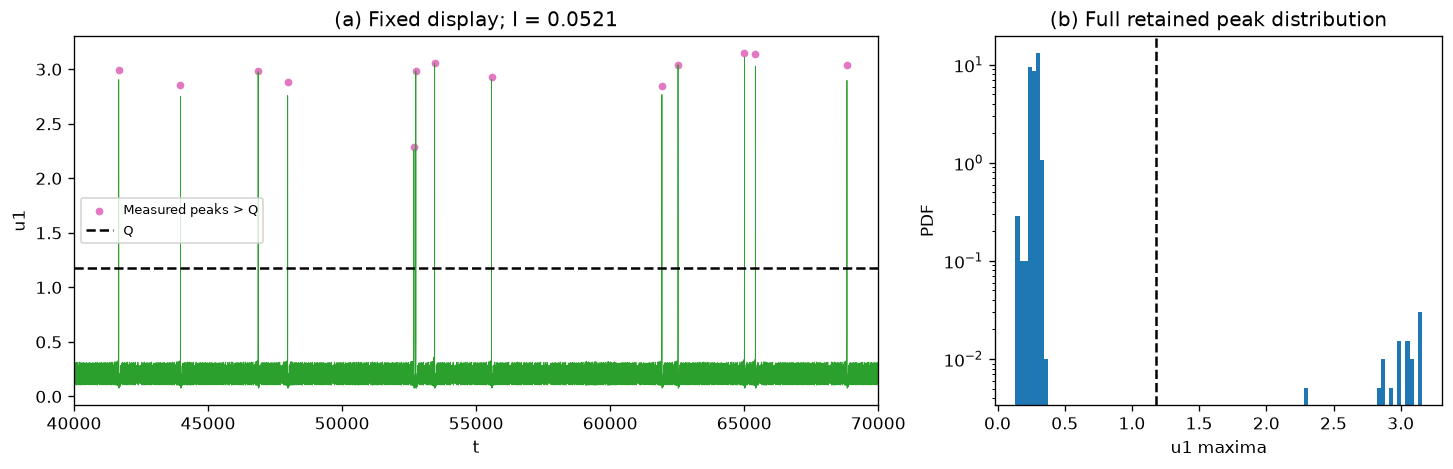

In [20]:
fig8_amplitude = 0.0521
fig8_record = p2_representatives[fig8_amplitude]
fig8_metrics = p2_rep_metrics[fig8_amplitude]
shown = (fig8_metrics["peak_time"] >= 40_000) & (
    fig8_metrics["peak_time"] < 70_000
)
shown_extreme = shown & (fig8_metrics["peaks"] > fig8_metrics["threshold"])
fig, axes = plt.subplots(
    1, 2, figsize=(12, 3.8), width_ratios=(1.8, 1), layout="constrained"
)
axes[0].plot(
    fig8_record["trace_time"],
    fig8_record["trace_u1"],
    lw=0.5,
    color="tab:green",
)
axes[0].scatter(
    fig8_metrics["peak_time"][shown_extreme],
    fig8_metrics["peaks"][shown_extreme],
    s=13,
    color="tab:pink",
    label="Measured peaks > Q",
)
axes[0].axhline(fig8_metrics["threshold"], color="k", ls="--", label="Q")
axes[0].set(
    xlabel="t",
    ylabel="u1",
    title="(a) Fixed display; I = 0.0521",
    xlim=(40_000, 70_000),
)
axes[0].legend(fontsize=8)
pdf_probability, pdf_edges = peak_probabilities(
    fig8_metrics["peaks"], bins=100
)
pdf_widths = np.diff(pdf_edges)
pdf_density = pdf_probability / pdf_widths
np.testing.assert_allclose(np.sum(pdf_density * pdf_widths), 1.0)
occupied = pdf_probability > 0
axes[1].bar(
    (pdf_edges[:-1] + pdf_widths / 2)[occupied],
    pdf_density[occupied],
    width=pdf_widths[occupied],
)
axes[1].axvline(fig8_metrics["threshold"], color="k", ls="--")
axes[1].set(
    xlabel="u1 maxima",
    ylabel="PDF",
    yscale="log",
    title="(b) Full retained peak distribution",
)
plt.show()

**Figure:** Fig. 8(a,b), with explicitly assumed I = 0.0521.
**Observation:** 19 of 6,570 full-record peaks exceed Q = 1.180349 over 60,000
time units (0.3167 per 1,000); 13 appear in the predeclared 40,000–70,000 display,
and the normalized 100-bin PDF has a sparsely populated large-amplitude tail.
**Scientific meaning:** the measured tail supports a rare-amplitude record for
Fig. 2 comparisons, without establishing a fitted tail law or a crisis mechanism.
**Reproduction status:** **partially reproduced**; the original I, record length,
PDF configuration and trajectory are unavailable, and the observed rate is not
statistically converged merely because a finite tail is visible.

In [21]:
show_table(
    [
        "I",
        "Retained t",
        "Global peaks",
        "Segmented peaks",
        "Q",
        "Full > Q",
        "Rate / 1000 t",
        "Shown > Q",
        "PDF bins",
        "PDF integral",
    ],
    [
        [
            fig8_amplitude,
            60_000,
            fig8_metrics["peak_count"],
            fig8_metrics["segment_peak_count"],
            f"{fig8_metrics['threshold']:.6f}",
            fig8_metrics["count"],
            f"{1_000 * fig8_metrics['rate']:.4f}",
            int(shown_extreme.sum()),
            100,
            f"{np.sum(pdf_density * pdf_widths):.12f}",
        ]
    ],
)
show_table(
    [
        "I",
        "Global peaks",
        "Segmented peaks",
        "MRT valid / total",
        "ENT valid / total",
    ],
    [
        [
            amplitude,
            m["peak_count"],
            m["segment_peak_count"],
            (
                f"{len(m['segments']) - len(m['invalid_mrt'])}"
                f"/{len(m['segments'])}"
            ),
            (
                f"{len(m['segments']) - len(m['invalid_entropy'])}"
                f"/{len(m['segments'])}"
            ),
        ]
        for amplitude, m in p2_rep_metrics.items()
    ],
)

| I | Retained t | Global peaks | Segmented peaks | Q | Full > Q | Rate / 1000 t | Shown > Q | PDF bins | PDF integral |
|---|---|---|---|---|---|---|---|---|---|
| 0.0521 | 60000 | 6570 | 6570 | 1.180349 | 19 | 0.3167 | 13 | 100 | 1.000000000000 |

| I | Global peaks | Segmented peaks | MRT valid / total | ENT valid / total |
|---|---|---|---|---|
| 0.0515 | 6589 | 6587 | 30/30 | 30/30 |
| 0.0521 | 6570 | 6570 | 30/30 | 30/30 |
| 0.0553 | 6364 | 6364 | 30/30 | 30/30 |

## 11. Stages C–D — Coarse Figure 2 sweep inspection

Use **21 uniformly spaced interior I values over (0.051,0.056)** plus the three
preselected controls. Every main result retains **20,000 time units**, giving
10 baseline segments. Representatives use the first 20,000 of their longer
trajectory; this is explicitly a prefix, not a 60,000-point estimate mixed into
an otherwise shorter curve. The other conditions are integrated under the same
settings. All panels will use these identical retained trajectory portions.

The pilot timings printed above estimate roughly one third to one half of the
long-record cost per new main condition. Coarse results and counts will be
inspected before adding local refinement. The large-support flag max(peak)>1
and the disappearance of sampled Q crossings provide **finite-record candidate
intervals**, not true bifurcation parameters or guaranteed labels.

In [22]:
def collect_phase2(parameters):
    records, metrics = {}, {}
    for index, amplitude in enumerate(parameters, 1):
        amplitude = float(amplitude)
        record = (
            p2_representatives[amplitude]
            if amplitude in p2_representatives
            else cached_phase2(amplitude, P2_SETTINGS)
        )
        summary = describe_record(record, length=P2_SETTINGS["duration"])
        records[amplitude], metrics[amplitude] = record, summary
        print(
            f"Sweep {index}/{len(parameters)} I={amplitude:.7f}: "
            f"{summary['count']} peaks > Q, {summary['large_count']} > 1; "
            f"VMRT={summary['vmrt']:.4g}, VENT={summary['vent']:.4g}",
            flush=True,
        )
    return records, metrics


P2_COARSE = np.unique(
    np.r_[np.linspace(0.05105, 0.05595, 21), list(P2_REPRESENTATIVES.values())]
)
p2_coarse_records, p2_coarse_metrics = collect_phase2(P2_COARSE)

Sweep 1/24 I=0.0510500: 0 peaks > Q, 0 > 1; VMRT=0, VENT=6.345e-08


Sweep 2/24 I=0.0512950: 0 peaks > Q, 0 > 1; VMRT=8.846e-05, VENT=7.183e-06


Sweep 3/24 I=0.0515000: 0 peaks > Q, 0 > 1; VMRT=0.007738, VENT=0.0002251


Sweep 4/24 I=0.0515400: 0 peaks > Q, 0 > 1; VMRT=0.02842, VENT=8.696e-05


Sweep 5/24 I=0.0517850: 0 peaks > Q, 0 > 1; VMRT=0.005515, VENT=6.173e-05


...

Sweep 20/24 I=0.0552150: 0 peaks > Q, 83 > 1; VMRT=0.002462, VENT=9.288e-05


Sweep 21/24 I=0.0553000: 0 peaks > Q, 70 > 1; VMRT=0.02701, VENT=0.0002909


Sweep 22/24 I=0.0554600: 0 peaks > Q, 80 > 1; VMRT=0.005496, VENT=0.0001535


Sweep 23/24 I=0.0557050: 0 peaks > Q, 89 > 1; VMRT=0.005666, VENT=0.0002251


Sweep 24/24 I=0.0559500: 0 peaks > Q, 108 > 1; VMRT=0.005607, VENT=0.0001913


In [23]:
coarse_rows = []
for amplitude, m in sorted(p2_coarse_metrics.items()):
    coarse_rows.append(
        [
            f"{amplitude:.7f}",
            m["peak_count"],
            f"{m['peaks'].max():.5f}",
            f"{m['threshold']:.5f}",
            m["count"],
            m["large_count"],
            *(f"{m[key]:.6g}" for key in ("mrt", "vmrt", "entropy", "vent")),
        ]
    )
show_table(
    [
        "I",
        "Global peaks",
        "Highest peak",
        "Q",
        "Peaks > Q",
        "Peaks > 1",
        "Mean MRT",
        "VMRT",
        "Mean ENT",
        "VENT",
    ],
    coarse_rows,
)
parameters = np.array(sorted(p2_coarse_metrics))
large_flags = [p2_coarse_metrics[p]["large_count"] > 0 for p in parameters]
q_flags = [p2_coarse_metrics[p]["count"] > 0 for p in parameters]
large_intervals = [
    (parameters[i], parameters[i + 1])
    for i in range(parameters.size - 1)
    if not large_flags[i] and large_flags[i + 1]
]
end_intervals = [
    (parameters[i], parameters[i + 1])
    for i in range(parameters.size - 1)
    if q_flags[i] and not q_flags[i + 1]
]
print("All observed large-support onset intervals:", large_intervals)
print("All observed ends of Q-crossing samples:", end_intervals)

| I | Global peaks | Highest peak | Q | Peaks > Q | Peaks > 1 | Mean MRT | VMRT | Mean ENT | VENT |
|---|---|---|---|---|---|---|---|---|---|
| 0.0510500 | 2197 | 0.30655 | 0.43586 | 0 | 0 | 3 | 0 | 0.443017 | 6.34547e-08 |
| 0.0512950 | 2196 | 0.30773 | 0.43800 | 0 | 0 | 2.72708 | 8.8463e-05 | 0.625321 | 7.18331e-06 |
| 0.0515000 | 2197 | 0.30883 | 0.44093 | 0 | 0 | 2.10067 | 0.00773761 | 0.772073 | 0.000225141 |
| 0.0515400 | 2196 | 0.30903 | 0.44208 | 0 | 0 | 1.8759 | 0.0284163 | 0.786291 | 8.69558e-05 |
| 0.0517850 | 2197 | 0.31026 | 0.44232 | 0 | 0 | 2.40381 | 0.00551475 | 0.815473 | 6.17289e-05 |
| 0.0520300 | 2193 | 3.10917 | 0.96984 | 4 | 4 | 3.11004 | 2.07901 | 0.71506 | 0.104871 |
| 0.0521000 | 2192 | 3.15616 | 1.11557 | 5 | 5 | 2.88729 | 3.25969 | 0.589317 | 0.146865 |
| 0.0522750 | 2179 | 3.15516 | 1.73490 | 18 | 18 | 2.09249 | 1.11916 | 0.339282 | 0.0461134 |
| 0.0525200 | 2152 | 3.15899 | 2.41673 | 29 | 43 | 2.56651 | 0.713466 | 0.369703 | 0.0367913 |
| 0.0527650 | 2160 | 3.14713 | 2.16112 | 30 | 34 | 2.54115 | 0.786603 | 0.362217 | 0.0379579 |
| 0.0530100 | 2169 | 3.14231 | 1.98197 | 26 | 28 | 2.88115 | 1.07296 | 0.373468 | 0.0421822 |
| 0.0532550 | 2162 | 3.13746 | 2.19989 | 32 | 33 | 2.47571 | 0.585979 | 0.304269 | 0.000680197 |
| 0.0535000 | 2153 | 3.14161 | 2.52404 | 38 | 42 | 2.33148 | 0.36264 | 0.318187 | 0.000771401 |
| 0.0537450 | 2128 | 3.13831 | 3.00295 | 22 | 67 | 1.94452 | 0.0979994 | 0.352786 | 0.000298344 |
| 0.0539900 | 2130 | 3.12895 | 2.92720 | 28 | 65 | 1.97426 | 0.0274193 | 0.358675 | 9.57214e-05 |
| 0.0542350 | 2120 | 3.12975 | 3.08747 | 8 | 72 | 1.97751 | 0.169225 | 0.361373 | 0.000433396 |
| 0.0544800 | 2111 | 3.12220 | 3.39511 | 0 | 84 | 1.7574 | 0.0197552 | 0.375538 | 0.000114479 |
| 0.0547250 | 2067 | 3.01098 | 4.45913 | 0 | 130 | 1.8231 | 0.000392481 | 0.373699 | 3.08588e-07 |
| 0.0549700 | 2116 | 3.12269 | 3.36693 | 0 | 78 | 1.84024 | 0.0262444 | 0.371254 | 0.00016205 |
| 0.0552150 | 2113 | 3.11029 | 3.46303 | 0 | 83 | 1.76699 | 0.00246221 | 0.375107 | 9.28784e-05 |
| 0.0553000 | 2126 | 3.11054 | 3.23988 | 0 | 70 | 1.88343 | 0.0270128 | 0.364415 | 0.000290886 |
| 0.0554600 | 2115 | 3.10823 | 3.44309 | 0 | 80 | 1.78961 | 0.0054957 | 0.376368 | 0.000153457 |
| 0.0557050 | 2102 | 3.10545 | 3.64056 | 0 | 89 | 1.7945 | 0.00566566 | 0.38898 | 0.000225144 |
| 0.0559500 | 2087 | 3.09910 | 3.77260 | 0 | 108 | 1.74361 | 0.00560721 | 0.402597 | 0.000191315 |

All observed large-support onset intervals: [(np.float64(0.051785), np.float64(0.05203))]
All observed ends of Q-crossing samples: [(np.float64(0.054235), np.float64(0.05448))]


The coarse gate retains all observed intervals, including multiple changes or
missing extremes, rather than selecting an interval solely because it contains
a published reference. Local refinement will use the **first observed
large-support onset** and the **last observed end of Q crossings**, if present,
with seven grid values per selected interval. A moving sample-derived Q and
finite waiting times can shift either boundary. Missing intervals will remain
unresolved, not be replaced with presumed paper transitions.

### 11.1 Targeted refinement, preserving the coarse observations

Refine the first observed large-support onset and the last observed end of
Q crossings with seven points each. Their coarse intervals are reported above;
no printed transition value is used to decide whether a simulation has an event.
Keep every coarse point. All main-panel statistics still use the first 20,000
retained time units, T = 2,000, k = 10, and the original estimator.

In [24]:
refinement_intervals = []
if large_intervals:
    refinement_intervals.append(large_intervals[0])
if end_intervals:
    refinement_intervals.append(end_intervals[-1])
refinement_intervals = list(dict.fromkeys(refinement_intervals))
if refinement_intervals:
    refined_parameters = np.unique(
        np.concatenate(
            [np.linspace(low, high, 7) for low, high in refinement_intervals]
        )
    )
    fine_records, fine_metrics = collect_phase2(refined_parameters)
else:
    fine_records, fine_metrics = {}, {}
    print("No observed candidate interval; no transition was invented.")
p2_main_records = {**p2_coarse_records, **fine_records}
p2_main_metrics = {**p2_coarse_metrics, **fine_metrics}
p2_parameters = np.array(sorted(p2_main_metrics))
flags_large = [p2_main_metrics[p]["large_count"] > 0 for p in p2_parameters]
flags_q = [p2_main_metrics[p]["count"] > 0 for p in p2_parameters]
observed_onsets = [
    (p2_parameters[i], p2_parameters[i + 1])
    for i in range(p2_parameters.size - 1)
    if not flags_large[i] and flags_large[i + 1]
]
observed_ends = [
    (p2_parameters[i], p2_parameters[i + 1])
    for i in range(p2_parameters.size - 1)
    if flags_q[i] and not flags_q[i + 1]
]
print("Refined main conditions:", len(p2_main_metrics))
print("Observed >1-peak onset intervals:", observed_onsets)
print("Observed last-Q-crossing candidate intervals:", observed_ends)
print("These intervals are not confidence intervals or mechanism proofs.")

Sweep 1/14 I=0.0517850: 0 peaks > Q, 0 > 1; VMRT=0.005515, VENT=6.173e-05


Sweep 2/14 I=0.0518258: 0 peaks > Q, 0 > 1; VMRT=0.01965, VENT=5.07e-05


Sweep 3/14 I=0.0518667: 1 peaks > Q, 1 > 1; VMRT=0.3504, VENT=0.03591


Sweep 4/14 I=0.0519075: 0 peaks > Q, 0 > 1; VMRT=0.3318, VENT=0.001042


Sweep 5/14 I=0.0519483: 1 peaks > Q, 1 > 1; VMRT=0.8978, VENT=0.05046


...

Sweep 11/14 I=0.0543575: 0 peaks > Q, 84 > 1; VMRT=0.009615, VENT=0.0001677


Sweep 12/14 I=0.0543983: 0 peaks > Q, 78 > 1; VMRT=0.1029, VENT=0.0003199


Sweep 13/14 I=0.0544392: 0 peaks > Q, 91 > 1; VMRT=0.007934, VENT=9.367e-05


Sweep 14/14 I=0.0544800: 0 peaks > Q, 84 > 1; VMRT=0.01976, VENT=0.0001145


Refined main conditions: 34
Observed >1-peak onset intervals: [(np.float64(0.051825833333333335), np.float64(0.051866666666666665)), (np.float64(0.051907499999999995), np.float64(0.05194833333333333))]
Observed last-Q-crossing candidate intervals: [(np.float64(0.051866666666666665), np.float64(0.051907499999999995)), (np.float64(0.054235), np.float64(0.05427583333333333)), (np.float64(0.054316666666666666), np.float64(0.0543575))]
These intervals are not confidence intervals or mechanism proofs.


### 11.2 Figure 2(a–c) — Same-trajectory bifurcation and segment measures

Every column uses the same main 20,000-time-unit record portion for Q, local
maxima, MRT, ENT and their variances. Full-record extrema supply panel (a), while
independent metric segments omit peaks that cannot be bracketed inside their
boundaries; both counts are retained. Panel (a) uses **256 shared amplitude
bins** and raw occurrence counts with logarithmic color, an explicit display
choice separate from the 50 per-segment ENT bins. A black line shows Q.

Panels (b,c) retain the Phase 1 unweighted means and k−1 variances on separate
blue/red axes. Q never enters the segment estimator. No curve smoothing, peak
clipping, amplitude rounding, continuation, or parameter retuning is performed.
Finite event waiting times and a moving Q can make sampled boundaries differ
from the reference ranges. The missing author T/k/m prevents an exact numerical
comparison of variance magnitudes.

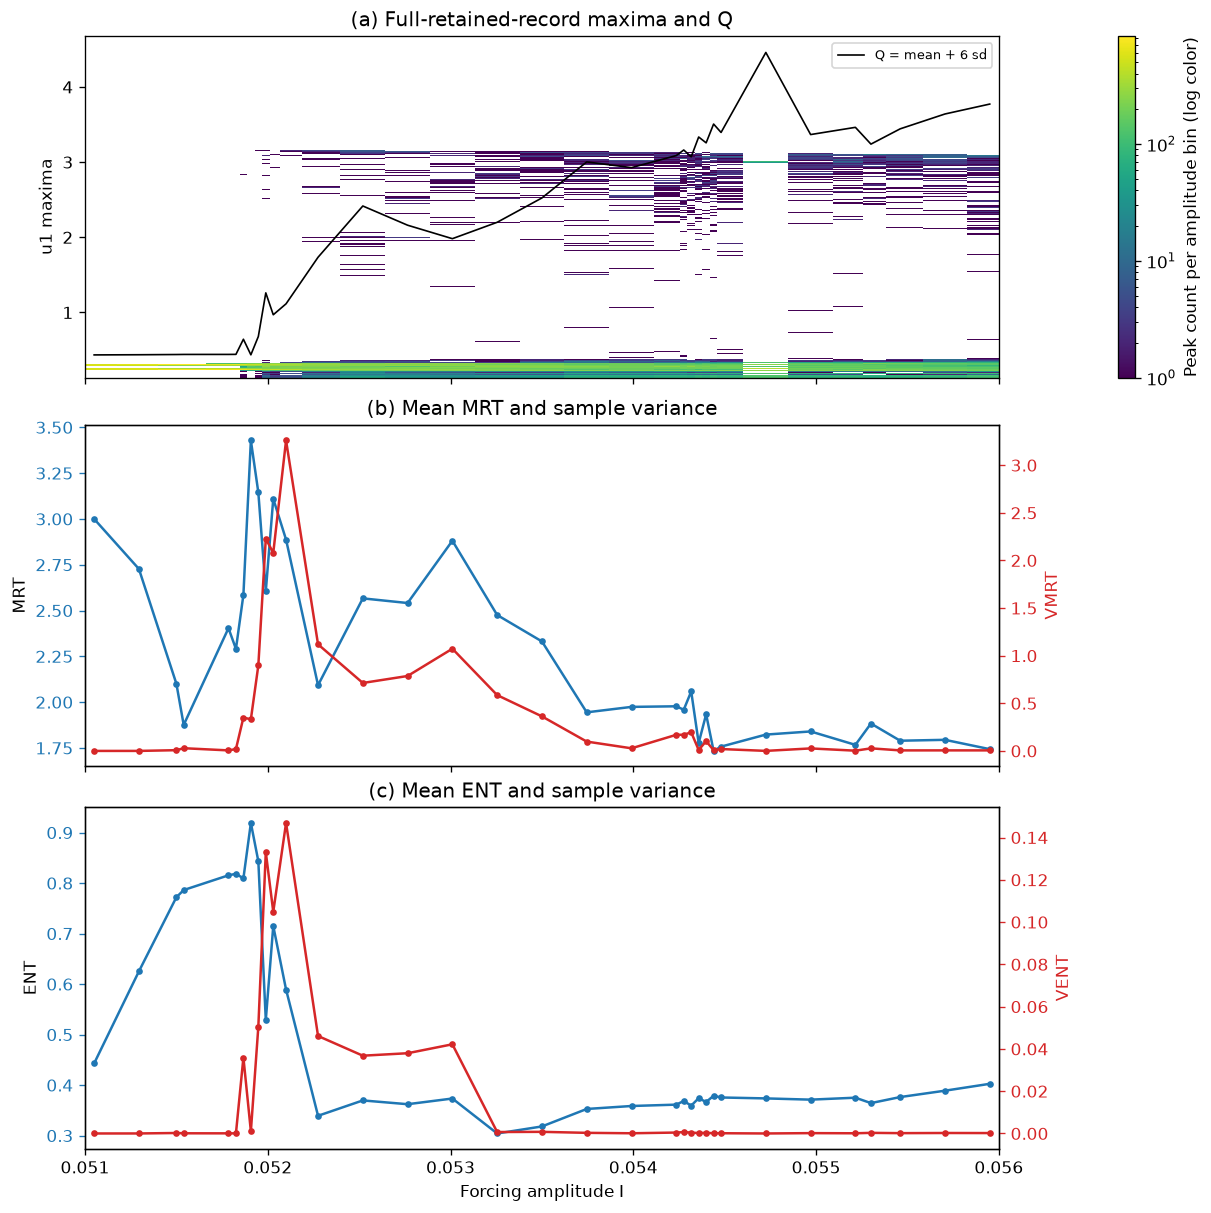

In [25]:
main_peaks = [p2_main_metrics[p]["peaks"] for p in p2_parameters]
amp_edges = np.linspace(
    min(v.min() for v in main_peaks), max(v.max() for v in main_peaks), 257
)
occurrences = np.array(
    [np.histogram(v, bins=amp_edges)[0] for v in main_peaks]
)
i_edges = np.r_[
    p2_parameters[0] - np.diff(p2_parameters)[0] / 2,
    (p2_parameters[:-1] + p2_parameters[1:]) / 2,
    p2_parameters[-1] + np.diff(p2_parameters)[-1] / 2,
]
fig, axes = plt.subplots(
    3, 1, figsize=(10, 10), sharex=True, layout="constrained"
)
mesh = axes[0].pcolormesh(
    i_edges,
    amp_edges,
    np.ma.masked_equal(occurrences.T, 0),
    cmap="viridis",
    norm=LogNorm(vmin=1, vmax=occurrences.max()),
)
fig.colorbar(
    mesh, ax=axes[0], label="Peak count per amplitude bin (log color)"
)
axes[0].plot(
    p2_parameters,
    [p2_main_metrics[p]["threshold"] for p in p2_parameters],
    color="k",
    lw=1,
    label="Q = mean + 6 sd",
)
axes[0].set(ylabel="u1 maxima", title="(a) Full-retained-record maxima and Q")
axes[0].legend(fontsize=8)
for row, (mean_key, var_key, label) in enumerate(
    (("mrt", "vmrt", "MRT"), ("entropy", "vent", "ENT")), 1
):
    axes[row].plot(
        p2_parameters,
        [p2_main_metrics[p][mean_key] for p in p2_parameters],
        ".-",
        color="tab:blue",
    )
    axes[row].set(
        ylabel=label,
        title=f"({'bc'[row - 1]}) Mean {label} and sample variance",
    )
    axes[row].tick_params(axis="y", colors="tab:blue")
    twin = axes[row].twinx()
    twin.plot(
        p2_parameters,
        [p2_main_metrics[p][var_key] for p in p2_parameters],
        ".-",
        color="tab:red",
    )
    twin.set_ylabel(var_key.upper(), color="tab:red")
    twin.tick_params(axis="y", colors="tab:red")
for ax in axes:
    ax.set_xlim(0.051, 0.056)
    ax.ticklabel_format(axis="x", useOffset=False)
axes[-1].set_xlabel("Forcing amplitude I")
plt.show()

**Figure:** Fig. 2(a–c), under the equal-length independent-start protocol.
**Observation:** the 34-point sweep expands from peaks near 0.3 to about 3.1;
VMRT/VENT rise strongly near sparse excursions and usually fall as large peaks
become more frequent, with nonmonotone sampled intervals and counterexamples.
**Scientific meaning:** the means can obscure differences in segment
heterogeneity, but a large variance is neither a universal extreme-event label
nor proof of an interior crisis.
**Reproduction status:** **partially reproduced**; broad trends are supported,
while absolute MRT/VMRT, sampled boundaries and the exact smooth published
curves are not quantitatively matched under the missing author conventions.

### 11.3 Test the variance claim rather than assuming it

Use observational groups: no maximum above the fixed height 1; sampled Q
crossings; or large peaks above 1 with no Q crossing. The first group may include
periodic windows as well as bounded aperiodic dynamics. These are amplitude
observations, not proofs of dynamical classes. The table reports finite/total
control counts explicitly; group summaries do not replace strict segment means.

For a limited counterexample check, compare Q-crossing records against both
preselected lower/upper references at the **same 20,000 length**. Cases whose
VMRT or VENT is not larger than both references are listed. This is a descriptive,
in-sample comparison, not a learned decision threshold, accuracy score, or an
independent validation of classification performance.

In [26]:
observational_groups = {
    "no peak > 1": [],
    "Q crossed": [],
    "large support, Q not crossed": [],
}
for amplitude, metrics in p2_main_metrics.items():
    group = (
        "no peak > 1"
        if metrics["large_count"] == 0
        else "Q crossed"
        if metrics["count"] > 0
        else "large support, Q not crossed"
    )
    observational_groups[group].append(amplitude)
group_rows = []
for group, parameters in observational_groups.items():
    for key in ("mrt", "vmrt", "entropy", "vent"):
        values = np.array([p2_main_metrics[p][key] for p in parameters])
        finite = values[np.isfinite(values)]
        quantiles = (
            [
                f"{v:.6g}"
                for v in (np.median(finite), finite.min(), finite.max())
            ]
            if finite.size
            else ["undefined"] * 3
        )
        group_rows.append(
            [group, key, f"{finite.size}/{values.size}", *quantiles]
        )
show_table(
    [
        "Observed group",
        "Metric",
        "Finite / total controls",
        "Median",
        "Min",
        "Max",
    ],
    group_rows,
)
reference_variances = {
    key: max(p2_main_metrics[0.0515][key], p2_main_metrics[0.0553][key])
    for key in ("vmrt", "vent")
}
comparison_counterexamples = []
for amplitude in observational_groups["Q crossed"]:
    metrics = p2_main_metrics[amplitude]
    weak = [
        key
        for key in ("vmrt", "vent")
        if not np.isfinite(metrics[key])
        or metrics[key] <= reference_variances[key]
    ]
    if weak:
        comparison_counterexamples.append(
            [
                f"{amplitude:.8f}",
                metrics["count"],
                f"{metrics['vmrt']:.6g}",
                f"{metrics['vent']:.6g}",
                ", ".join(weak),
            ]
        )
show_table(
    [
        "I",
        "Peaks > Q",
        "VMRT",
        "VENT",
        "Not above both references / undefined",
    ],
    comparison_counterexamples,
)
print("Reference variance maxima:", reference_variances)
print(
    "Counterexamples to this limited pairwise ordering:",
    len(comparison_counterexamples),
)

| Observed group | Metric | Finite / total controls | Median | Min | Max |
|---|---|---|---|---|---|
| no peak > 1 | mrt | 7/7 | 2.40381 | 1.8759 | 3.42846 |
| no peak > 1 | vmrt | 7/7 | 0.00773761 | 0 | 0.331795 |
| no peak > 1 | entropy | 7/7 | 0.786291 | 0.443017 | 0.919066 |
| no peak > 1 | vent | 7/7 | 6.17289e-05 | 6.34547e-08 | 0.00104223 |
| Q crossed | mrt | 15/15 | 2.54115 | 1.94452 | 3.14467 |
| Q crossed | vmrt | 15/15 | 0.713466 | 0.0274193 | 3.25969 |
| Q crossed | entropy | 15/15 | 0.362217 | 0.304269 | 0.843341 |
| Q crossed | vent | 15/15 | 0.0367913 | 9.57214e-05 | 0.146865 |
| large support, Q not crossed | mrt | 12/12 | 1.79205 | 1.73396 | 1.95865 |
| large support, Q not crossed | vmrt | 12/12 | 0.00877438 | 0.000392481 | 0.169449 |
| large support, Q not crossed | entropy | 12/12 | 0.374642 | 0.364415 | 0.402597 |
| large support, Q not crossed | vent | 12/12 | 0.000164896 | 3.08588e-07 | 0.000651887 |

| I | Peaks > Q | VMRT | VENT | Not above both references / undefined |
|---|---|---|---|---|
| 0.05399000 | 28 | 0.0274193 | 9.57214e-05 | vent |

Reference variance maxima: {'vmrt': 0.027012832696416918, 'vent': 0.00029088559893269045}
Counterexamples to this limited pairwise ordering: 1


## 12. Stage E — Targeted numerical and statistical reliability

All alternatives change one choice at a time. The long representative records
provide nested length and segmentation comparisons without new dynamics;
separate independent starts test initial-condition sensitivity. The reference
always remains the Phase 1 metric convention. A difference under any check is
reported rather than choosing the setting that gives a preferred variance peak.

In [27]:
p2_reliability = []
length_rows, common_q_rows = [], []
for amplitude, record in p2_representatives.items():
    longest = p2_rep_metrics[amplitude]
    for length in (20_000.0, 60_000.0):
        metrics = describe_record(record, length=length)
        p2_reliability.append((amplitude, f"length={length:g}", metrics))
        length_rows.append(
            [
                amplitude,
                int(length),
                len(metrics["segments"]),
                metrics["peak_count"],
                *(
                    f"{metrics[key]:.6g}"
                    for key in ("mrt", "vmrt", "entropy", "vent")
                ),
                metrics["count"],
                f"{1_000 * metrics['rate']:.4f}",
            ]
        )
        common_count = np.count_nonzero(
            metrics["peaks"] > longest["threshold"]
        )
        common_q_rows.append(
            [
                amplitude,
                int(length),
                f"{metrics['threshold']:.5f}",
                metrics["count"],
                int(common_count),
                f"{1_000 * common_count / length:.4f}",
            ]
        )
show_table(
    [
        "I",
        "Retained t",
        "k",
        "Peaks",
        "Mean MRT",
        "VMRT",
        "Mean ENT",
        "VENT",
        "Peaks > own Q",
        "Rate / 1000 t",
    ],
    length_rows,
)
show_table(
    [
        "I",
        "Retained t",
        "Own Q",
        "Above own Q",
        "Above longest Q",
        "Common-Q rate / 1000 t",
    ],
    common_q_rows,
)

| I | Retained t | k | Peaks | Mean MRT | VMRT | Mean ENT | VENT | Peaks > own Q | Rate / 1000 t |
|---|---|---|---|---|---|---|---|---|---|
| 0.0515 | 20000 | 10 | 2197 | 2.10067 | 0.00773761 | 0.772073 | 0.000225141 | 0 | 0.0000 |
| 0.0515 | 60000 | 30 | 6589 | 2.14058 | 0.0100932 | 0.764468 | 0.000208719 | 0 | 0.0000 |
| 0.0521 | 20000 | 10 | 2192 | 2.88729 | 3.25969 | 0.589317 | 0.146865 | 5 | 0.2500 |
| 0.0521 | 60000 | 30 | 6570 | 2.86552 | 2.35966 | 0.589694 | 0.11953 | 19 | 0.3167 |
| 0.0553 | 20000 | 10 | 2126 | 1.88343 | 0.0270128 | 0.364415 | 0.000290886 | 0 | 0.0000 |
| 0.0553 | 60000 | 30 | 6364 | 1.87552 | 0.0268243 | 0.368455 | 0.000259334 | 0 | 0.0000 |

| I | Retained t | Own Q | Above own Q | Above longest Q | Common-Q rate / 1000 t |
|---|---|---|---|---|---|
| 0.0515 | 20000 | 0.44093 | 0 | 0 | 0.0000 |
| 0.0515 | 60000 | 0.44082 | 0 | 0 | 0.0000 |
| 0.0521 | 20000 | 1.11557 | 5 | 5 | 0.2500 |
| 0.0521 | 60000 | 1.18035 | 19 | 19 | 0.3167 |
| 0.0553 | 20000 | 3.23988 | 0 | 0 | 0.0000 |
| 0.0553 | 60000 | 3.28636 | 0 | 0 | 0.0000 |

In [28]:
segmentation_rows = []
for amplitude, record in p2_representatives.items():
    for duration in (2_000.0, 1_000.0):
        metrics = describe_record(record, duration=duration)
        p2_reliability.append((amplitude, f"T={duration:g}", metrics))
        np.testing.assert_array_equal(
            metrics["peaks"], p2_rep_metrics[amplitude]["peaks"]
        )
        segmentation_rows.append(
            [
                amplitude,
                int(duration),
                len(metrics["segments"]),
                metrics["segment_peak_count"],
                *(
                    f"{metrics[key]:.6g}"
                    for key in ("mrt", "vmrt", "entropy", "vent")
                ),
            ]
        )
show_table(
    [
        "I",
        "Segment T",
        "k",
        "Independent segment peaks",
        "Mean MRT",
        "VMRT",
        "Mean ENT",
        "VENT",
    ],
    segmentation_rows,
)

| I | Segment T | k | Independent segment peaks | Mean MRT | VMRT | Mean ENT | VENT |
|---|---|---|---|---|---|---|---|
| 0.0515 | 2000 | 30 | 6587 | 2.14058 | 0.0100932 | 0.764468 | 0.000208719 |
| 0.0515 | 1000 | 60 | 6587 | 2.13321 | 0.0180996 | 0.753049 | 0.000417779 |
| 0.0521 | 2000 | 30 | 6570 | 2.86552 | 2.35966 | 0.589694 | 0.11953 |
| 0.0521 | 1000 | 60 | 6569 | 3.59669 | 1.22533 | 0.730531 | 0.0853269 |
| 0.0553 | 2000 | 30 | 6364 | 1.87552 | 0.0268243 | 0.368455 | 0.000259334 |
| 0.0553 | 1000 | 60 | 6362 | 1.78086 | 0.0627085 | 0.365192 | 0.000374932 |

In [29]:
initial_rows = []
for amplitude in P2_REPRESENTATIVES.values():
    for initial in P2_INITIALS:
        if initial == P2_INITIALS[0]:
            record = p2_representatives[amplitude]
        else:
            settings = {**P2_SETTINGS, "initial_state": initial}
            record = cached_phase2(amplitude, settings)
        metrics = describe_record(record, length=20_000)
        p2_reliability.append((amplitude, f"initial={initial}", metrics))
        initial_rows.append(
            [
                amplitude,
                str(initial),
                metrics["peak_count"],
                metrics["count"],
                f"{1_000 * metrics['rate']:.4f}",
                metrics["large_count"],
                *(
                    f"{metrics[key]:.6g}"
                    for key in ("mrt", "vmrt", "entropy", "vent")
                ),
            ]
        )
        print(f"Initial-state check I={amplitude}: {initial}", flush=True)
show_table(
    [
        "I",
        "Initial state",
        "Peaks",
        "Peaks > Q",
        "Rate / 1000 t",
        "Peaks > 1",
        "Mean MRT",
        "VMRT",
        "Mean ENT",
        "VENT",
    ],
    initial_rows,
)

Initial-state check I=0.0515: (0.2, 5.57)


Initial-state check I=0.0515: (0.1, 6.0)


Initial-state check I=0.0515: (0.3, 5.0)


Initial-state check I=0.0521: (0.2, 5.57)


Initial-state check I=0.0521: (0.1, 6.0)


Initial-state check I=0.0521: (0.3, 5.0)


Initial-state check I=0.0553: (0.2, 5.57)


Initial-state check I=0.0553: (0.1, 6.0)


Initial-state check I=0.0553: (0.3, 5.0)


| I | Initial state | Peaks | Peaks > Q | Rate / 1000 t | Peaks > 1 | Mean MRT | VMRT | Mean ENT | VENT |
|---|---|---|---|---|---|---|---|---|---|
| 0.0515 | (0.2, 5.57) | 2197 | 0 | 0.0000 | 0 | 2.10067 | 0.00773761 | 0.772073 | 0.000225141 |
| 0.0515 | (0.1, 6.0) | 2196 | 0 | 0.0000 | 0 | 2.10197 | 0.0239906 | 0.76431 | 0.000258136 |
| 0.0515 | (0.3, 5.0) | 2196 | 0 | 0.0000 | 0 | 2.20335 | 0.0194784 | 0.755767 | 0.000957909 |
| 0.0521 | (0.2, 5.57) | 2192 | 5 | 0.2500 | 5 | 2.88729 | 3.25969 | 0.589317 | 0.146865 |
| 0.0521 | (0.1, 6.0) | 2191 | 5 | 0.2500 | 5 | 3.19482 | 3.02545 | 0.67138 | 0.125238 |
| 0.0521 | (0.3, 5.0) | 2190 | 6 | 0.3000 | 6 | 3.2943 | 2.56305 | 0.665557 | 0.13408 |
| 0.0553 | (0.2, 5.57) | 2126 | 0 | 0.0000 | 70 | 1.88343 | 0.0270128 | 0.364415 | 0.000290886 |
| 0.0553 | (0.1, 6.0) | 2129 | 0 | 0.0000 | 66 | 1.90639 | 0.00736862 | 0.36169 | 0.000153789 |
| 0.0553 | (0.3, 5.0) | 2120 | 0 | 0.0000 | 75 | 1.83724 | 0.0123265 | 0.371621 | 0.000214408 |

In [30]:
estimator_rows = []
for amplitude, record in p2_representatives.items():
    baseline = p2_rep_metrics[amplitude]
    alternatives = (
        ("reference", {}),
        ("m=25", {"bins": 25}),
        ("pooled peak sigma", {"sigma_scope": "pooled"}),
        ("same samples, dt=0.1", {"stride": 2}),
    )
    digest = hashlib.sha256(record["peaks"].tobytes()).hexdigest()
    for name, options in alternatives:
        metrics = describe_record(record, **options)
        p2_reliability.append((amplitude, name, metrics))
        if name == "m=25":
            np.testing.assert_allclose(
                [metrics["mrt"], metrics["vmrt"]],
                [baseline["mrt"], baseline["vmrt"]],
                equal_nan=True,
            )
        if name == "pooled peak sigma":
            np.testing.assert_allclose(
                [metrics["entropy"], metrics["vent"]],
                [baseline["entropy"], baseline["vent"]],
                equal_nan=True,
            )
        estimator_rows.append(
            [
                amplitude,
                name,
                metrics["segment_peak_count"],
                *(
                    f"{metrics[key]:.6g}"
                    for key in ("mrt", "vmrt", "entropy", "vent")
                ),
                metrics["count"],
            ]
        )
    assert hashlib.sha256(record["peaks"].tobytes()).hexdigest() == digest
show_table(
    [
        "I",
        "Single changed choice",
        "Segmented peaks",
        "Mean MRT",
        "VMRT",
        "Mean ENT",
        "VENT",
        "Full peaks > Q",
    ],
    estimator_rows,
)

| I | Single changed choice | Segmented peaks | Mean MRT | VMRT | Mean ENT | VENT | Full peaks > Q |
|---|---|---|---|---|---|---|---|
| 0.0515 | reference | 6587 | 2.14058 | 0.0100932 | 0.764468 | 0.000208719 | 0 |
| 0.0515 | m=25 | 6587 | 2.14058 | 0.0100932 | 0.74984 | 0.000108353 | 0 |
| 0.0515 | pooled peak sigma | 6587 | 2.14029 | 0.00945418 | 0.764468 | 0.000208719 | 0 |
| 0.0515 | same samples, dt=0.1 | 6586 | 2.14025 | 0.010062 | 0.764498 | 0.000201181 | 0 |
| 0.0521 | reference | 6570 | 2.86552 | 2.35966 | 0.589694 | 0.11953 | 19 |
| 0.0521 | m=25 | 6570 | 2.86552 | 2.35966 | 0.564305 | 0.143756 | 19 |
| 0.0521 | pooled peak sigma | 6570 | 1.06977 | 0.00924259 | 0.589694 | 0.11953 | 19 |
| 0.0521 | same samples, dt=0.1 | 6570 | 2.86416 | 2.3624 | 0.589994 | 0.119299 | 19 |
| 0.0553 | reference | 6364 | 1.87552 | 0.0268243 | 0.368455 | 0.000259334 | 0 |
| 0.0553 | m=25 | 6364 | 1.87552 | 0.0268243 | 0.262951 | 0.000156522 | 0 |
| 0.0553 | pooled peak sigma | 6364 | 1.80105 | 0.00734088 | 0.368455 | 0.000259334 | 0 |
| 0.0553 | same samples, dt=0.1 | 6364 | 1.87955 | 0.0281269 | 0.369361 | 0.000270397 | 0 |

### 12.1 Solver and peak-extraction accuracy near the largest excursion

Restart the same cached state about 20 time units before the largest sampled
peak, at the correct absolute forcing time, for an 80-time-unit local audit.
Compare baseline tolerances against rtol = 10⁻¹¹, atol = 10⁻¹³, max_step = 0.5;
compare output spacings 0.05 and 0.025 against the tighter event roots. This is
an intentional numerical stress test near a large excursion, not a replacement
representative display chosen to improve a published figure. Long chaotic
trajectories need not coincide pointwise even when this check passes.

In [31]:
numerical_rows = []
for amplitude, record in p2_representatives.items():
    start = float(record["anchor_time"])
    times = start + np.arange(3_201) * 0.025
    solutions = []
    for rtol, atol, step in ((1e-9, 1e-11, 1.0), (1e-11, 1e-13, 0.5)):
        solution = solve_ivp(
            brusselator,
            (start, float(times[-1])),
            record["anchor_state"],
            args=(amplitude,),
            method="DOP853",
            events=u1_maximum,
            t_eval=times,
            rtol=rtol,
            atol=atol,
            max_step=step,
        )
        if not solution.success:
            raise RuntimeError(solution.message)
        solutions.append(solution)
    paired = []
    for solution in solutions:
        keep = (solution.t_events[0] > start + 0.05) & (
            solution.t_events[0] < times[-1] - 0.05
        )
        paired.append(
            (solution.t_events[0][keep], solution.y_events[0][keep, 0])
        )
    assert paired[0][0].size == paired[1][0].size > 0
    state_error = np.max(np.abs(solutions[0].y - solutions[1].y))
    root_error = np.max(np.abs(paired[0][1] - paired[1][1]))
    assert state_error < 1e-3, "Investigate the local solver discrepancy."
    sampling_errors = []
    for stride in (2, 1):
        pt, peaks = local_maxima(times[::stride], solutions[1].y[0, ::stride])
        keep = (pt > start + 0.05) & (pt < times[-1] - 0.05)
        pt, peaks = pt[keep], peaks[keep]
        assert peaks.size == paired[1][0].size
        nearest = np.argmin(
            np.abs(pt[:, None] - paired[1][0][None, :]), axis=1
        )
        sampling_errors.append(np.max(np.abs(peaks - paired[1][1][nearest])))
    numerical_rows.append(
        [
            amplitude,
            paired[0][0].size,
            f"{state_error:.3e}",
            f"{root_error:.3e}",
            *(f"{value:.3e}" for value in sampling_errors),
        ]
    )
show_table(
    [
        "I",
        "Paired peaks",
        "Max state error",
        "Max root-peak error",
        "Sample error 0.05",
        "Sample error 0.025",
    ],
    numerical_rows,
)

| I | Paired peaks | Max state error | Max root-peak error | Sample error 0.05 | Sample error 0.025 |
|---|---|---|---|---|---|
| 0.0515 | 9 | 1.052e-07 | 1.232e-08 | 1.301e-05 | 2.947e-06 |
| 0.0521 | 7 | 1.446e-07 | 4.106e-09 | 7.454e-05 | 7.454e-05 |
| 0.0553 | 7 | 3.277e-08 | 8.567e-10 | 1.669e-03 | 1.669e-03 |

### 12.2 Segment heterogeneity, independent of the curve means

The diagnostic below plots each segment's MRT and ENT at its center. Shading
marks segments containing a **global** maximum above the full-record Q. The
metric still uses only independently bracketed maxima of that segment, and all
segments enter the variance. Global peaks omitted by metric boundaries, if any,
are reported separately in the final audit.

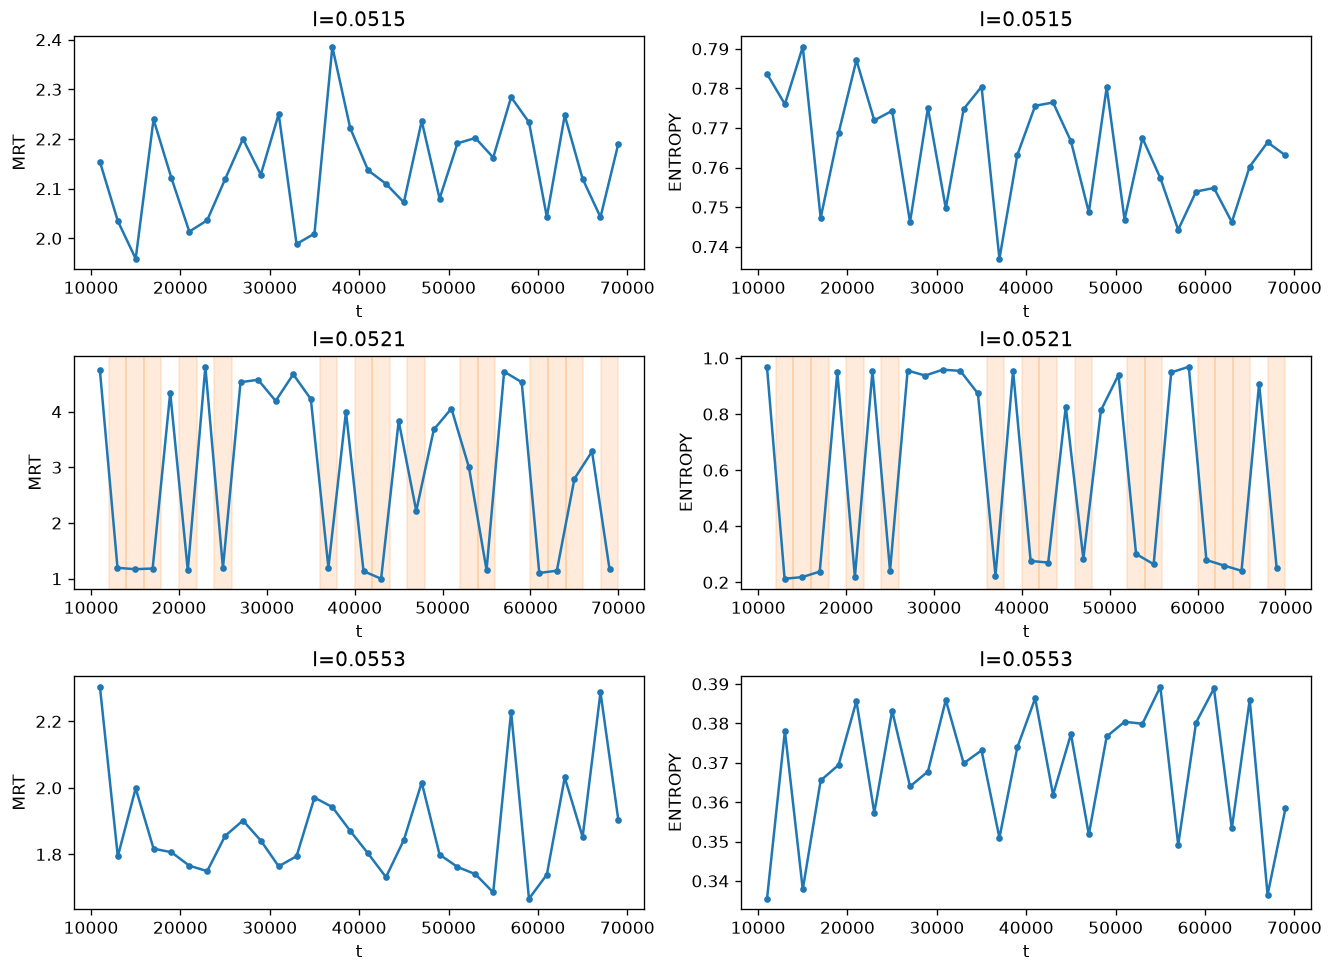

In [32]:
fig, axes = plt.subplots(3, 2, figsize=(11, 8), layout="constrained")
for row, (amplitude, metrics) in enumerate(p2_rep_metrics.items()):
    centers = [(s["start"] + s["stop"]) / 2 for s in metrics["segments"]]
    for col, key in enumerate(("mrt", "entropy")):
        axes[row, col].plot(
            centers, [s[key] for s in metrics["segments"]], ".-"
        )
        for segment in metrics["segments"]:
            present = (
                (metrics["peak_time"] >= segment["start"])
                & (metrics["peak_time"] < segment["stop"])
                & (metrics["peaks"] > metrics["threshold"])
            )
            if np.any(present):
                axes[row, col].axvspan(
                    segment["start"],
                    segment["stop"],
                    color="tab:orange",
                    alpha=0.15,
                )
        axes[row, col].set(
            xlabel="t", ylabel=key.upper(), title=f"I={amplitude}"
        )
plt.show()

**Diagnostic:** event-containing and quiet segments can have different metric
values even when an overall mean is similar to another regime. This gives a
mechanism for a large between-segment variance, while the reliability tables
show that finite counts and conventions can also change it. Shading is a
separate amplitude reference; it does not enter recurrence or entropy estimation.

## 13. Phase 2 numerical and reproducibility audit

Check every main and sensitivity result without discarding undefined segments.
The source/canonical-metadata hashes, parameters, finite peaks, peak indices,
and original reference core are preserved. Rebinning and changing segment length
use unchanged trajectory arrays. A cache may be deleted; a later run regenerates
its documented simulation, while plotting can reuse a warm cache.

In [33]:
all_checks = [
    (p, "main 20000", m) for p, m in p2_main_metrics.items()
] + p2_reliability
undefined_rows, edge_rows = [], []
for amplitude, label, metrics in all_checks:
    for segment in metrics["segments"]:
        if np.isfinite(segment["mrt"]):
            assert segment["mrt"] >= 1
        if np.isfinite(segment["entropy"]):
            assert -1e-14 <= segment["entropy"] <= 1 + 1e-14
    for key, variance, invalid in (
        ("mrt", "vmrt", "invalid_mrt"),
        ("entropy", "vent", "invalid_entropy"),
    ):
        if metrics[invalid]:
            assert np.isnan(metrics[key]) and np.isnan(metrics[variance])
        else:
            assert np.isfinite(metrics[key]) and metrics[variance] >= 0
    if metrics["invalid_mrt"] or metrics["invalid_entropy"]:
        undefined_rows.append(
            [
                amplitude,
                label,
                str(metrics["invalid_mrt"]),
                str(metrics["invalid_entropy"]),
            ]
        )
    assert metrics["count"] == np.count_nonzero(
        metrics["peaks"] > metrics["threshold"]
    )
edge_views = [(p, "main 20000", m) for p, m in p2_main_metrics.items()] + [
    (p, "long 60000", m) for p, m in p2_rep_metrics.items()
]
edge_totals = [0, 0]
for amplitude, label, metrics in edge_views:
    included = np.concatenate([s["peak_time"] for s in metrics["segments"]])
    omitted = ~np.isin(metrics["peak_time"], included)
    lost = int(omitted.sum())
    lost_extremes = int(
        np.sum(omitted & (metrics["peaks"] > metrics["threshold"]))
    )
    assert lost == metrics["peak_count"] - metrics["segment_peak_count"]
    edge_totals[0] += lost
    edge_totals[1] += lost_extremes
    if lost:
        edge_rows.append([amplitude, label, lost, lost_extremes])
show_table(
    ["I", "Check", "Undefined MRT indices", "Undefined ENT indices"],
    undefined_rows,
)
show_table(
    [
        "I",
        "Record view",
        "Global peaks omitted at metric edges",
        "Omitted peaks > Q",
    ],
    edge_rows,
)
source = "\n".join(
    inspect.getsource(f)
    for f in (brusselator, u1_maximum, sample_peak_data, simulate_phase2)
)
source_hash = hashlib.sha256(source.encode()).hexdigest()
for name in P2_CACHE_USED:
    with np.load(P2_CACHE / name, allow_pickle=False) as saved:
        serialized = saved["metadata"].item()
        metadata = json.loads(serialized)
        assert metadata["parameters"] == MODEL
        assert metadata["source_sha256"] == source_hash
        assert name.endswith(
            hashlib.sha256(serialized.encode()).hexdigest()[:20] + ".npz"
        )
        assert np.all(np.isfinite(saved["peaks"]))
        assert np.all(np.diff(saved["index"]) > 0)
        assert np.all(saved["left"] <= saved["index"])
        assert np.all(saved["right"] >= saved["index"])
files = list(P2_CACHE.glob("*.npz"))
cache_size_mib = sum(p.stat().st_size for p in files) / 2**20
print("Main parameter conditions:", len(p2_main_metrics))
print("Targeted sensitivity results:", len(p2_reliability))
print("Checks with undefined metrics:", len(undefined_rows))
print(
    "Matched active cache entries:",
    len(P2_CACHE_USED),
    "; activity:",
    P2_CACHE_ACTIVITY,
)
print(f"Total compact cache size: {cache_size_mib:.2f} MiB")
print("Mathematical checks passed; statistical limits remain.")
print(
    "Audited main/long views:",
    len(edge_views),
    "; omitted peaks/Q peaks:",
    edge_totals,
)

| I | Check | Undefined MRT indices | Undefined ENT indices |
|---|---|---|---|

| I | Record view | Global peaks omitted at metric edges | Omitted peaks > Q |
|---|---|---|---|
| 0.05105 | main 20000 | 1 | 0 |
| 0.0515 | main 20000 | 1 | 0 |
| 0.052765 | main 20000 | 1 | 0 |
| 0.05448 | main 20000 | 1 | 0 |
| 0.0515 | long 60000 | 2 | 0 |

Main parameter conditions: 34
Targeted sensitivity results: 33
Checks with undefined metrics: 0
Matched active cache entries: 40 ; activity: {'hits': 44, 'computed': 0}
Total compact cache size: 3.83 MiB
Mathematical checks passed; statistical limits remain.
Audited main/long views: 37 ; omitted peaks/Q peaks: [6, 0]


### Phase 2 Conclusions and Phase 3 Handoff

1. **The three representative amplitude regimes are observed.** Over 60,000
   retained time units, I = 0.0515 has no peak above 1, I = 0.0521 has 19 peaks
   above both 1 and its Q, and I = 0.0553 has 219 peaks above 1 but none above its
   larger Q. These are recorded amplitude/rate differences, not labels guaranteed
   by a parameter interval or proof of chaotic/interior-crisis mechanisms.
2. **Figure 2(a–c) is partially reproduced.** A 24-point coarse grid plus ten new
   targeted points gives 34 equal-length main records (20,000 time units, k = 10).
   The first observed >1 excursion is bracketed by [0.05182583, 0.05186667],
   then disappears at the next sampled point and reappears within
   [0.05190750, 0.05194833]. Near the upper end, Q crossings alternate before
   their last observed end in [0.05431667, 0.05435750]. These nonmonotone,
   finite-observation intervals are not bifurcation estimates or confidence
   intervals and do not precisely confirm the paper's reference boundaries.
3. **Figure 8(a,b) is partially reproduced.** The predeclared I = 0.0521 gives
   Q = 1.180349 and 19/6,570 peaks above it; 13 appear in the unchanged displayed
   [40,000,70,000) interval. The 100-bin full-peak PDF integrates to one. The
   original I is not reported, so this is an explicit qualitative comparison,
   not a matched author trajectory or a fitted heavy-tail law.
4. **The variance claim receives conditional support, with counterexamples.**
   Full-record VMRT is approximately 0.0101 / 2.36 / 0.0268 and VENT is
   0.000209 / 0.1195 / 0.000259 for the three references. The sparse-excursion
   record is clearly more heterogeneous under the primary convention. However,
   at I = 0.05399 there are 28 main-record Q crossings and VENT ≈ 9.57 × 10⁻⁵,
   below both preselected non-extreme reference variances. At I = 0.0519075,
   no >1 peak or Q crossing is sampled despite VMRT ≈ 0.332 and VENT ≈ 0.00104.
   The observational-group ranges overlap. These are in-sample observations,
   not an independent classification-performance test or a universal separation.
5. **Means versus variances.** Mean MRT ranges overlap across observational
   groups, and mean ENT is similar for several Q-crossing and frequent-large
   records. Segment plots show how event-containing and quiet segments can
   differ, explaining the added information in variance. Nevertheless, a
   variance peak may reflect geometry, finite estimation, or transient effects;
   it is not a physical mechanism or an early-warning result by itself.
6. **Reliability materially changes the magnitude and sometimes the conclusion.**
   At I = 0.0521, extending 20,000 to 60,000 retained time units changes VMRT
   from 3.26 to 2.36 and VENT from 0.1469 to 0.1195. Changing T from 2,000 to
   1,000 on the same long trajectory changes k from 30 to 60 and VMRT to 1.23.
   Most importantly, pooled rather than segment peak σ reduces rare-record
   VMRT to **0.00924**, close to the bounded-record pooled value 0.00945; the
   strong MRT-variance distinction does not survive that convention. VENT is
   unchanged by σ and remains large in this test. The m = 25 and coarser-sampling
   results are retained separately, as are three initial states per condition.
   Their finite event counts and variance differences do not prove multistability
   or statistical convergence.
7. **Main discrepancies remain explicit.** The article's larger absolute MRT
   and VMRT values are not reproduced; its T/k/m, exact RQA implementation,
   initial conditions, continuation policy, and Fig. 8 I are unspecified.
   The governing equations, original positive complete-white-line definition,
   and model parameters are unchanged. Numerical/censoring/threshold conventions
   are plausible explanations for differences, not demonstrated author settings.
   Global Q/PDF peaks and independent-segment edge omissions are separately audited.
8. **Accuracy and uncertainty are distinct.** Local two-solver errors near the
   largest excursions are small and sampling errors are measured, but neither
   establishes convergence of rare-event rates. No primary or sensitivity
   segment in this execution is undefined; the strict propagation policy and
   index reporting remain in force if undefined segments occur later. Source-
   and metadata-matched compressed caches permit reproducible plotting and
   controlled re-segmentation, not independent statistical replication.
9. **Prepare Phase 3 only.** Resolve or explicitly fix σ/white-line/T/k/m and
   record conventions before a two-parameter I–omega validation. Use this phase's
   counterexamples, finite waiting-time effects, and global/segment boundary
   accounting when defining comparison criteria. More independent long records
   and a criterion independent of the variance curves are needed before claiming
   robust discrimination. No Figure 3, other model, new measure, software package,
   sliding-window analysis, or automatic Phase 3 computation is included.

# Phase 3 — Final Brusselator two-parameter assessment

The preceding **89 cells and their outputs are preserved verbatim**. The original
PDF, Section III.B and Fig. 3 (printed p. 6), and the existing research discussion
are the sources. This phase covers only Eq. (5), Fig. 3(a–c), count/variance
correspondence and a final audit. Figures 1, 2 and 8 retain their partial status;
the counterexamples and σ sensitivity established in Phase 2 remain evidence.

The published maps show a narrow ascending event-positive band, approximately
ω ≈ 0.683 at I = 0.05 to ω ≈ 0.713 at I = 0.07, with weaker secondary structures.
These visually read positions are qualitative comparison targets, not values
used to assign events. Author grid size, T/k/m, initialization and full numerical
protocol are unavailable. No exact boundary or mechanism is inferred from a map.

**Cache lifecycle:** temporary compressed simulation caches are used during
execution, then removed as requested. Executed outputs remain in this notebook;
a small, explicit numerical-results snapshot below permits the final maps and
comparison tables to be redrawn without simulation caches. It is an archive of
computed map/table values, not a substitute for rerunning the scientific model.

## 14. Stage A — Prespecified two-parameter protocol

The primary rectangular grid is **11 amplitudes × 13 frequencies = 143 pairs**:
I = 0.050, 0.052, …, 0.070 (spacing 0.002), and ω = 0.660, 0.665, …, 0.720
(spacing 0.005). Endpoints are included as boundary probes of the published open
ranges. A 3 × 3 subset is executed first to estimate cost. At most one 5 × 5
local patch will refine the neighborhood of the largest observed coarse-grid
event count (lexicographic tie rule); the primary statistics use only the uniform
coarse grid so that adaptive sampling does not overweight an event region.

Each pair starts independently at **(0.2, 5.57)** and forcing phase zero,
with μ = 0.2, α = 1.114, DOP853, rtol = 10⁻⁹, atol = 10⁻¹¹, max_step = 1,
transient = 10,000, retained duration = **20,000**, and Δt = 0.05. There is no
parameter continuation. T = 2,000, k = 10, m = 50, ε = 0.3 σ(segment peaks),
population σ, diagonal retained, positive complete white vertical gaps and
unweighted k−1 variance are unchanged. An undefined segment propagates NaN and
its index is recorded. Global Q = mean(full retained maxima) + 6 population σ;
strict maxima > Q give the count. Segment-edge maxima remain separately audited.

The high-variance rule is fixed **before map computation**: each variance is
high when it is positive and at least its own coarse-grid finite-value 75th
percentile (inclusive ties). The identical rule is applied separately to VMRT
and VENT; event labels are not used to choose the percentile. Undefined metric
cells are excluded only from that metric's descriptive comparison, with their
number reported. These are exploratory, in-sample comparisons.

In [18]:
P3_I = np.round(np.linspace(0.05, 0.07, 11), 8)
P3_OMEGA = np.round(np.linspace(0.66, 0.72, 13), 8)
P3_SETTINGS = {**P2_SETTINGS, "trace_start": 10_000.0}
P3_ESTIMATOR = {
    "T": 2000.0,
    "k": 10,
    "bins": 50,
    "recurrence_factor": 0.3,
    "sigma": "per-segment population peak sigma",
    "gaps": "positive complete white vertical; diagonal retained",
    "variance": "unweighted, ddof=1, strict NaN propagation",
    "qualifier": "global peak mean + 6 population std; strict exceedance",
    "extraction": "independently bracketed sampled maxima per segment",
}
P3_PERCENTILE = 75
P3_CACHE = P2_CACHE / "phase3"
P3_CACHE.mkdir(parents=True, exist_ok=True)
P3_ACTIVITY = {"hits": 0, "computed": 0}
P3_USED = set()
print("Grid shape (omega, I):", (len(P3_OMEGA), len(P3_I)))
print("Numerical settings:", P3_SETTINGS)
print("Reference estimator:", P3_ESTIMATOR)

Grid shape (omega, I): (13, 11)
Numerical settings: {'initial_state': (0.2, 5.57), 'transient': 10000.0, 'duration': 20000.0, 'sample_dt': 0.05, 'method': 'DOP853', 'rtol': 1e-09, 'atol': 1e-11, 'max_step': 1.0, 'trace_start': 10000.0, 'trace_duration': 0.0, 'display_stride': 5}
Reference estimator: {'T': 2000.0, 'k': 10, 'bins': 50, 'recurrence_factor': 0.3, 'sigma': 'per-segment population peak sigma', 'gaps': 'positive complete white vertical; diagonal retained', 'variance': 'unweighted, ddof=1, strict NaN propagation', 'qualifier': 'global peak mean + 6 population std; strict exceedance', 'extraction': 'independently bracketed sampled maxima per segment'}


In [19]:
def brusselator_pair(time, state, amplitude, omega):
    """Eq. (5) with explicit frequency and unchanged chemical parameters."""
    u1, u2 = state
    reaction = u1**2 * u2
    forcing = amplitude * np.sin(omega * time)
    return (
        MODEL["mu"] - (MODEL["alpha"] + 1) * u1 + reaction + forcing,
        MODEL["alpha"] * u1 - reaction,
    )


for time in (0.0, 0.7, 50.0):
    np.testing.assert_array_equal(
        brusselator_pair(time, (0.3, 4), 0.0521, MODEL["omega"]),
        brusselator(time, (0.3, 4), 0.0521),
    )
short_time = np.arange(0, 80.01, 0.05)
short_options = {
    "t_eval": short_time,
    "method": "DOP853",
    "rtol": 1e-9,
    "atol": 1e-11,
    "max_step": 1.0,
}
short_old = solve_ivp(
    brusselator, (0, 80), (0.2, 5.57), args=(0.0521,), **short_options
)
short_new = solve_ivp(
    brusselator_pair,
    (0, 80),
    (0.2, 5.57),
    args=(0.0521, 0.69),
    **short_options,
)
assert short_old.success and short_new.success
np.testing.assert_array_equal(short_old.y, short_new.y)
assert MODEL == {"mu": 0.2, "alpha": 1.114, "omega": 0.69}
print("Explicit-frequency Eq. (5) matches the validated reference exactly.")

Explicit-frequency Eq. (5) matches the validated reference exactly.


### 14.1 Simulation and provenance

The new frequency argument avoids mutating the Phase 1–2 model dictionary.
Compressed records store full-retained-record peak indices, plateau edges,
amplitudes, numerical metadata, a restart anchor and an optional fixed trace.
Before saving, every segment's peaks and MRT/ENT are compared with independent
extraction from the raw sampled trajectory. Failed integrations are recorded
explicitly and remain missing, rather than receiving zeros or imputed variances.

In [20]:
def simulate_phase3(pair, settings):
    """Integrate one independent start and retain compact sampled peaks."""
    started = perf_counter()
    dt, duration = settings["sample_dt"], settings["duration"]
    count = round(duration / dt)
    if not np.isclose(count * dt, duration, rtol=0, atol=1e-8):
        raise ValueError("Duration must contain an integer sample count.")
    times = settings["transient"] + dt * np.arange(count)
    solution = solve_ivp(
        brusselator_pair,
        (0, settings["transient"] + duration),
        settings["initial_state"],
        args=pair,
        t_eval=times,
        method=settings["method"],
        rtol=settings["rtol"],
        atol=settings["atol"],
        max_step=settings["max_step"],
    )
    if not solution.success or not np.all(np.isfinite(solution.y)):
        raise RuntimeError(solution.message)
    primary = sample_peak_data(solution.y[0])
    if not primary["peaks"].size:
        raise RuntimeError("No bracketed maxima; qualifier unavailable.")
    anchor = max(0, int(primary["index"][np.argmax(primary["peaks"])]))
    anchor = max(0, anchor - round(20 / dt))
    shown = np.flatnonzero(
        (times >= settings["trace_start"])
        & (times < settings["trace_start"] + settings["trace_duration"])
    )[:: settings["display_stride"]]
    record = {
        **primary,
        "sample_dt": np.array(dt),
        "duration": np.array(duration),
        "transient": np.array(settings["transient"]),
        "samples": np.array(count),
        "trace_time": times[shown],
        "trace_u1": solution.y[0, shown],
        "anchor_time": np.array(times[anchor]),
        "anchor_state": solution.y[:, anchor],
        "nfev": np.array(solution.nfev),
        "seconds": np.array(perf_counter() - started),
    }
    direct = analyze_segments(times, solution.y[0])
    rebuilt = segments_from_peak_data(record)
    for left, right in zip(direct, rebuilt, strict=True):
        np.testing.assert_array_equal(left["peaks"], right["peaks"])
        np.testing.assert_array_equal(left["peak_time"], right["peak_time"])
        np.testing.assert_allclose(
            [left["mrt"], left["entropy"]],
            [right["mrt"], right["entropy"]],
            equal_nan=True,
        )
    return record

In [21]:
def phase3_metadata(pair, settings):
    functions = (
        brusselator_pair,
        sample_peak_data,
        simulate_phase3,
        segments_from_peak_data,
        recurrence_matrix,
        white_vertical_lengths,
        mrt_from_lengths,
        peak_probabilities,
        normalized_entropy,
        summarize_segments,
        sample_variance,
        describe_record,
    )
    source = "\n".join(inspect.getsource(f) for f in functions)
    return json.dumps(
        {
            "schema": 1,
            "model": "Brusselator Eq. (5)",
            "I": float(pair[0]),
            "omega": float(pair[1]),
            "mu": MODEL["mu"],
            "alpha": MODEL["alpha"],
            "settings": settings,
            "estimator": {
                **P3_ESTIMATOR,
                "k": round(settings["duration"] / P3_ESTIMATOR["T"]),
            },
            "numpy": np.__version__,
            "scipy": scipy.__version__,
            "python": platform.python_version(),
            "source_sha256": hashlib.sha256(source.encode()).hexdigest(),
        },
        sort_keys=True,
    )


def cached_phase3(pair, settings):
    serialized = phase3_metadata(pair, settings)
    key = hashlib.sha256(serialized.encode()).hexdigest()[:20]
    path = P3_CACHE / f"pair_{pair[0]:.8f}_{pair[1]:.8f}_{key}.npz"
    if path.exists():
        with np.load(path, allow_pickle=False) as saved:
            if saved["metadata"].item() != serialized:
                raise RuntimeError("Incompatible Phase 3 cache metadata.")
            record = {
                name: saved[name].copy()
                for name in saved.files
                if name != "metadata"
            }
        P3_ACTIVITY["hits"] += 1
    else:
        record = simulate_phase3(pair, settings)
        temporary = path.with_suffix(".tmp")
        with temporary.open("wb") as stream:
            np.savez_compressed(stream, metadata=serialized, **record)
        temporary.replace(path)
        P3_ACTIVITY["computed"] += 1
    P3_USED.add(path.name)
    return record


def collect_phase3(pairs, settings, *, records=None, metrics=None):
    records = {} if records is None else records
    metrics = {} if metrics is None else metrics
    failures = {}
    for index, raw_pair in enumerate(pairs, 1):
        pair = tuple(map(float, raw_pair))
        try:
            if pair not in records:
                records[pair] = cached_phase3(pair, settings)
            metrics[pair] = describe_record(records[pair])
        except (RuntimeError, ValueError, MemoryError) as error:
            failures[pair] = str(error)
            print("FAILED", pair, str(error), flush=True)
            continue
        result = metrics[pair]
        print(
            f"Pair {index}/{len(pairs)} {pair}: NQ={result['count']}; "
            f"VMRT={result['vmrt']:.5g}, VENT={result['vent']:.5g}",
            flush=True,
        )
    return records, metrics, failures

In [22]:
P3_PILOT = [(P3_I[i], P3_OMEGA[j]) for j in (0, 6, 12) for i in (0, 5, 10)]
p3_pilot_started = perf_counter()
p3_records, p3_metrics, p3_failures = collect_phase3(P3_PILOT, P3_SETTINGS)
p3_pilot_elapsed = perf_counter() - p3_pilot_started
creation_times = [float(r["seconds"]) for r in p3_records.values()]
p3_cost_per_pair = float(np.median(creation_times))
print(f"Pilot wall time: {p3_pilot_elapsed:.1f} s")
print(f"Median saved integration creation time: {p3_cost_per_pair:.2f} s")
print(
    "Estimated remaining coarse integration minutes:",
    round(
        (len(P3_I) * len(P3_OMEGA) - len(p3_records)) * p3_cost_per_pair / 60,
        1,
    ),
)
print("This timing is an estimate; event waiting-time adequacy is separate.")

Pair 1/9 (0.05, 0.66): NQ=0; VMRT=0.00017482, VENT=1.8923e-07


Pair 2/9 (0.06, 0.66): NQ=0; VMRT=5.4782e-32, VENT=0


Pair 3/9 (0.07, 0.66): NQ=0; VMRT=5.6689e-05, VENT=8.885e-08


Pair 4/9 (0.05, 0.69): NQ=0; VMRT=0, VENT=1.5005e-11


Pair 5/9 (0.06, 0.69): NQ=0; VMRT=0.010722, VENT=9.8202e-05


Pair 6/9 (0.07, 0.69): NQ=0; VMRT=0.00030046, VENT=3.1696e-06


Pair 7/9 (0.05, 0.72): NQ=0; VMRT=0.0007259, VENT=9.66e-06


Pair 8/9 (0.06, 0.72): NQ=0; VMRT=0, VENT=1.056e-12


Pair 9/9 (0.07, 0.72): NQ=0; VMRT=0.19337, VENT=0.00011784


Pilot wall time: 0.2 s
Median saved integration creation time: 5.97 s
Estimated remaining coarse integration minutes: 13.3
This timing is an estimate; event waiting-time adequacy is separate.


The pilot establishes computational feasibility, not that the grid resolves the
thin event band. The duration is kept at the Phase 2 baseline rather than
shortened for map density. All successful coarse cells will use that same
protocol; selected longer records will test finite-count sensitivity separately.

## 15. Stages B–C — Common-grid event counts and variances

Compute all 143 independent starts, including the pilot pairs without repeating
their integrations. Counts are obtained from globally bracketed retained peaks;
variance estimates use the exact same trajectories with independently bracketed
segment peaks. Record duration, peak counts, Q, valid segments and omitted metric
boundary peaks are retained for every pair. Failed simulations stay missing.

In [23]:
P3_COARSE_PAIRS = [
    (float(amplitude), float(omega))
    for omega in P3_OMEGA
    for amplitude in P3_I
]
p3_records, p3_metrics, coarse_failures = collect_phase3(
    P3_COARSE_PAIRS,
    P3_SETTINGS,
    records=p3_records,
    metrics=p3_metrics,
)
p3_failures = {
    pair: error
    for pair, error in p3_failures.items()
    if pair not in p3_metrics
}
p3_failures.update(coarse_failures)
p3_coarse_success = [p for p in P3_COARSE_PAIRS if p in p3_metrics]
print("Completed coarse pairs:", len(p3_coarse_success), "/", 143)
print(
    "Observed event-positive pairs:",
    sum(p3_metrics[p]["count"] > 0 for p in p3_coarse_success),
)
print("Explicit failures:", p3_failures)

Pair 1/143 (0.05, 0.66): NQ=0; VMRT=0.00017482, VENT=1.8923e-07


Pair 2/143 (0.052, 0.66): NQ=0; VMRT=0.00017482, VENT=1.8923e-07


Pair 3/143 (0.054, 0.66): NQ=0; VMRT=0.00017482, VENT=1.8923e-07


Pair 4/143 (0.056, 0.66): NQ=0; VMRT=0.00017482, VENT=1.3984e-07


Pair 5/143 (0.058, 0.66): NQ=0; VMRT=0.00017482, VENT=1.3984e-07


...

Pair 140/143 (0.064, 0.72): NQ=0; VMRT=0, VENT=1.0018e-12


Pair 141/143 (0.066, 0.72): NQ=0; VMRT=0.0025567, VENT=0.00014603


Pair 142/143 (0.068, 0.72): NQ=0; VMRT=0.14528, VENT=0.00022172


Pair 143/143 (0.07, 0.72): NQ=0; VMRT=0.19337, VENT=0.00011784


Completed coarse pairs: 143 / 143
Observed event-positive pairs: 12
Explicit failures: {}


### 15.1 Coarse-map gate and one local refinement

The table lists all event-positive coarse pairs, including counts, Q and both
variances. A local 5 × 5 patch covers one neighboring coarse interval on each
side of the largest-count pair (clipped at domain edges), with lexicographic
(I, ω) tie-breaking. Refinement is triggered by observed counts alone; it neither
changes the uniform-grid comparison nor optimizes a variance threshold. If
there is no positive count, refinement is left unresolved rather than invented.

In [24]:
p3_positive_pairs = sorted(
    p for p in p3_coarse_success if p3_metrics[p]["count"] > 0
)
show_table(
    ["I", "omega", "Peaks", "Q", "NQ", "Rate / 1000 t", "VMRT", "VENT"],
    [
        [
            *p,
            p3_metrics[p]["peak_count"],
            *(f"{p3_metrics[p][key]:.6g}" for key in ("threshold", "count")),
            f"{1000 * p3_metrics[p]['rate']:.4f}",
            *(f"{p3_metrics[p][key]:.6g}" for key in ("vmrt", "vent")),
        ]
        for p in p3_positive_pairs
    ],
)
P3_FINE_I, P3_FINE_OMEGA = np.array([]), np.array([])
p3_refine_center = None
if p3_positive_pairs:
    p3_refine_center = min(
        p3_positive_pairs, key=lambda p: (-p3_metrics[p]["count"], p)
    )
    i = int(np.flatnonzero(P3_I == p3_refine_center[0])[0])
    j = int(np.flatnonzero(P3_OMEGA == p3_refine_center[1])[0])
    P3_FINE_I = np.round(
        np.linspace(P3_I[max(0, i - 1)], P3_I[min(len(P3_I) - 1, i + 1)], 5), 8
    )
    P3_FINE_OMEGA = np.round(
        np.linspace(
            P3_OMEGA[max(0, j - 1)], P3_OMEGA[min(len(P3_OMEGA) - 1, j + 1)], 5
        ),
        8,
    )
print("Count-selected local center:", p3_refine_center)
print("Local I coordinates:", P3_FINE_I)
print("Local omega coordinates:", P3_FINE_OMEGA)

| I | omega | Peaks | Q | NQ | Rate / 1000 t | VMRT | VENT |
|---|---|---|---|---|---|---|---|
| 0.05 | 0.68 | 2102 | 3.16766 | 12 | 0.6000 | 0.139152 | 0.000579952 |
| 0.05 | 0.685 | 2169 | 1.49489 | 12 | 0.6000 | 1.22934 | 0.108917 |
| 0.052 | 0.69 | 2191 | 1.16384 | 6 | 0.3000 | 1.78855 | 0.123746 |
| 0.054 | 0.69 | 2135 | 2.74851 | 35 | 1.7500 | 0.254249 | 0.000343326 |
| 0.056 | 0.695 | 2172 | 2.41478 | 39 | 1.9500 | 0.106441 | 0.00033337 |
| 0.058 | 0.7 | 2220 | 1.2395 | 8 | 0.4000 | 3.4472 | 0.0700894 |
| 0.06 | 0.7 | 2169 | 2.5597 | 29 | 1.4500 | 0.162758 | 0.000341395 |
| 0.062 | 0.705 | 2221 | 1.53469 | 16 | 0.8000 | 2.83522 | 0.0585673 |
| 0.064 | 0.705 | 2165 | 2.83389 | 5 | 0.2500 | 0.0237881 | 0.000205949 |
| 0.066 | 0.71 | 2223 | 1.90896 | 29 | 1.4500 | 0.104641 | 0.000632899 |
| 0.068 | 0.71 | 2189 | 2.58719 | 21 | 1.0500 | 0.0421812 | 0.000236878 |
| 0.07 | 0.715 | 2270 | 0.913747 | 5 | 0.2500 | 3.33788 | 0.084689 |

Count-selected local center: (0.056, 0.695)
Local I coordinates: [0.054 0.055 0.056 0.057 0.058]
Local omega coordinates: [0.69   0.6925 0.695  0.6975 0.7   ]


In [25]:
P3_FINE_PAIRS = [
    (float(amplitude), float(omega))
    for omega in P3_FINE_OMEGA
    for amplitude in P3_FINE_I
]
p3_records, p3_metrics, fine_failures = collect_phase3(
    P3_FINE_PAIRS,
    P3_SETTINGS,
    records=p3_records,
    metrics=p3_metrics,
)
p3_failures.update(fine_failures)
print("Unique coarse/refined pairs:", len(p3_metrics))
print("Uniform coarse grid remains the sole primary comparison population.")

Pair 1/25 (0.054, 0.69): NQ=35; VMRT=0.25425, VENT=0.00034333


Pair 2/25 (0.055, 0.69): NQ=0; VMRT=0.0070067, VENT=0.0001974


Pair 3/25 (0.056, 0.69): NQ=0; VMRT=0.0072275, VENT=0.00010056


Pair 4/25 (0.057, 0.69): NQ=0; VMRT=0.0047719, VENT=0.00019258


Pair 5/25 (0.058, 0.69): NQ=0; VMRT=0.0048633, VENT=0.00011569


...

Pair 22/25 (0.055, 0.7): NQ=0; VMRT=0, VENT=2.893e-07


Pair 23/25 (0.056, 0.7): NQ=0; VMRT=0.017433, VENT=0.00014694


Pair 24/25 (0.057, 0.7): NQ=0; VMRT=0.20234, VENT=5.9542e-05


Pair 25/25 (0.058, 0.7): NQ=8; VMRT=3.4472, VENT=0.070089


Unique coarse/refined pairs: 159
Uniform coarse grid remains the sole primary comparison population.


Refinement samples a local count change, without proving smoothness between
points or locating a bifurcation. The same 20,000 retained duration and estimator
apply to all new points. Coarse and refined maps will be shown separately so
unequal sampling density cannot create an apparent gain in map agreement.

### 15.2 Explicit numerical-results archive for cache-free map plotting

The following snapshot contains **executed scalar results and segment metric
vectors**, coordinates, failed-cell messages and exact numerical provenance.
No missing variance is replaced with zero; JSON null restores to a missing value.
It is stored inside this notebook because temporary simulation caches will be
deleted at completion. To redraw the published-map comparison afterward, run the
Phase 1 import/table cell, the archive/plot helpers, and the figure cells; expensive
integration and pilot/sweep cells can be skipped. The archive also includes
robustness tables and diagnostic peak/PDF arrays once those are computed below.

**Redraw without cache:** run the original imports and `show_table` definition
(cells beginning `import platform` and `MODEL =`), then this archive cell, the
`snapshot_grid`/map helper cell, and the two map cells. Stage D distribution,
frequency and spatial-comparison cells also operate on the archived arrays.
The targeted diagnostic plot uses the archived `p3_diagnostics` arrays; its
simulation/extraction cells can be skipped. All raw diagnostic arrays in the
archive are drawing/statistical result data, not external simulation caches.

The encoded numerical-results snapshot is stored in this notebook's `metadata.seralan_phase3_results`; the short loading cell verifies its SHA-256.


In [26]:
import base64
import hashlib
import json
import zlib
from pathlib import Path

P3_SAVED_JSON = None
if "p3_metrics" not in globals():
    candidates = (
        Path("Seralan_2026_reproduce.ipynb"),
        Path("reproduce_paper/Seralan_2026_reproduce.ipynb"),
    )
    archived_path = next((p for p in candidates if p.is_file()), None)
    if archived_path is None:
        raise FileNotFoundError("Run from the notebook or project directory.")
    archived_notebook = json.loads(archived_path.read_text())
    archive = archived_notebook["metadata"]["seralan_phase3_results"]
    P3_SAVED_JSON = zlib.decompress(
        base64.b64decode(archive["payload"])
    ).decode()
    assert (
        hashlib.sha256(P3_SAVED_JSON.encode()).hexdigest()
        == (archive["sha256"])
    )


def phase3_row(pair, metrics):
    row = {"I": pair[0], "omega": pair[1], "status": "success"}
    for key in (
        "threshold",
        "count",
        "rate",
        "large_count",
        "duration",
        "peak_count",
        "segment_peak_count",
        "mrt",
        "vmrt",
        "entropy",
        "vent",
        "invalid_mrt",
        "invalid_entropy",
    ):
        row[key] = metrics[key]
    row["segment_mrt"] = [s["mrt"] for s in metrics["segments"]]
    row["segment_entropy"] = [s["entropy"] for s in metrics["segments"]]
    row["segment_peaks"] = [len(s["peaks"]) for s in metrics["segments"]]
    return row


def json_compatible(value):
    if isinstance(value, dict):
        return {str(k): json_compatible(v) for k, v in value.items()}
    if isinstance(value, (list, tuple, np.ndarray)):
        return [json_compatible(v) for v in value]
    if isinstance(value, (float, np.floating)):
        return float(value) if np.isfinite(value) else None
    if isinstance(value, np.integer):
        return int(value)
    return value


if "p3_metrics" in globals():
    rows = [phase3_row(p, p3_metrics[p]) for p in sorted(p3_metrics)]
    rows.extend(
        {"I": p[0], "omega": p[1], "status": "failed", "error": error}
        for p, error in p3_failures.items()
    )
    p3_snapshot = json_compatible(
        {
            "coarse_I": P3_I,
            "coarse_omega": P3_OMEGA,
            "fine_I": P3_FINE_I,
            "fine_omega": P3_FINE_OMEGA,
            "refinement_center": p3_refine_center,
            "percentile": P3_PERCENTILE,
            "common_metadata": json.loads(
                phase3_metadata((0.05, 0.66), P3_SETTINGS)
            ),
            "rows": rows,
        }
    )
    display({"application/json": p3_snapshot}, raw=True)
elif P3_SAVED_JSON is not None:
    p3_snapshot = json.loads(P3_SAVED_JSON)
else:
    raise RuntimeError("No executed archive or computed Phase 3 results.")
print(
    "Archived successful pairs:",
    sum(row["status"] == "success" for row in p3_snapshot["rows"]),
)
P3_I = np.array(p3_snapshot["coarse_I"])
P3_OMEGA = np.array(p3_snapshot["coarse_omega"])
P3_PERCENTILE = p3_snapshot["percentile"]
p3_diagnostics = p3_snapshot.get("diagnostics", [])

Archived successful pairs: 159


In [27]:
from matplotlib.colors import Normalize
from matplotlib.patches import Patch


def snapshot_grid(snapshot, field, *, fine=False):
    prefix = "fine" if fine else "coarse"
    xs = np.array(snapshot[prefix + "_I"])
    ys = np.array(snapshot[prefix + "_omega"])
    rows = {(r["I"], r["omega"]): r for r in snapshot["rows"]}
    grid = np.full((len(ys), len(xs)), np.nan)
    for j, omega in enumerate(ys):
        for i, amplitude in enumerate(xs):
            row = rows.get((float(amplitude), float(omega)), {})
            value = row.get(field)
            if row.get("status") == "success" and value is not None:
                grid[j, i] = value
    return xs, ys, grid


def coordinate_edges(values):
    values = np.asarray(values)
    if values.size < 2 or np.any(np.diff(values) <= 0):
        raise ValueError("At least two increasing coordinates required.")
    return np.r_[
        values[0] - (values[1] - values[0]) / 2,
        (values[:-1] + values[1:]) / 2,
        values[-1] + (values[-1] - values[-2]) / 2,
    ]


def draw_phase3_maps(snapshot, *, fine=False):
    fig, axes = plt.subplots(
        1, 3, figsize=(13, 4.2), sharey=True, layout="constrained"
    )
    for ax, field, title in zip(
        axes,
        ("count", "vmrt", "vent"),
        ("(a) Observed Q crossings", "(b) VMRT", "(c) VENT"),
        strict=True,
    ):
        xs, ys, values = snapshot_grid(snapshot, field, fine=fine)
        positive = values[np.isfinite(values) & (values > 0)]
        if field == "count":
            norm = LogNorm(vmin=1, vmax=max(2, positive.max(initial=1)))
        else:
            norm = Normalize(vmin=0, vmax=max(1e-12, positive.max(initial=0)))
        cmap = plt.get_cmap("viridis").copy()
        cmap.set_bad("#d0d0d0")
        cmap.set_under("#f4cee6")
        shown = values.copy()
        if field == "count":
            shown[values == 0] = 0.5
        mesh = ax.pcolormesh(
            coordinate_edges(xs),
            coordinate_edges(ys),
            np.ma.masked_invalid(shown),
            cmap=cmap,
            norm=norm,
            shading="flat",
            rasterized=True,
        )
        ax.set(
            xlim=(xs[0], xs[-1]), ylim=(ys[0], ys[-1]), xlabel="I", title=title
        )
        fig.colorbar(
            mesh,
            ax=ax,
            label="Count (log color)" if field == "count" else field.upper(),
        )
    axes[0].set_ylabel("omega")
    axes[0].legend(
        handles=[
            Patch(facecolor="#f4cee6", label="Zero observed events"),
            Patch(facecolor="#d0d0d0", label="Missing / undefined"),
        ],
        loc="lower right",
        fontsize=7,
    )
    return fig

### 15.3 Figure 3(a–c) — Full-region coarse maps

The original target is the event-count band and corresponding VMRT/VENT on
I ∈ [0.05,0.07], ω ∈ [0.66,0.72]. All three panels below use the **same 143
20,000-time-unit records**, with T = 2,000 and k = 10. Pixel values are constant
inside coordinate midpoint cells; no interpolation or smoothing is applied.
Pink in (a) means zero observed events, positive counts use log color, and gray
means failed/missing records or undefined variances. Variance colors are linear.
The outer pixel edges are clipped to the sampled domain limits.

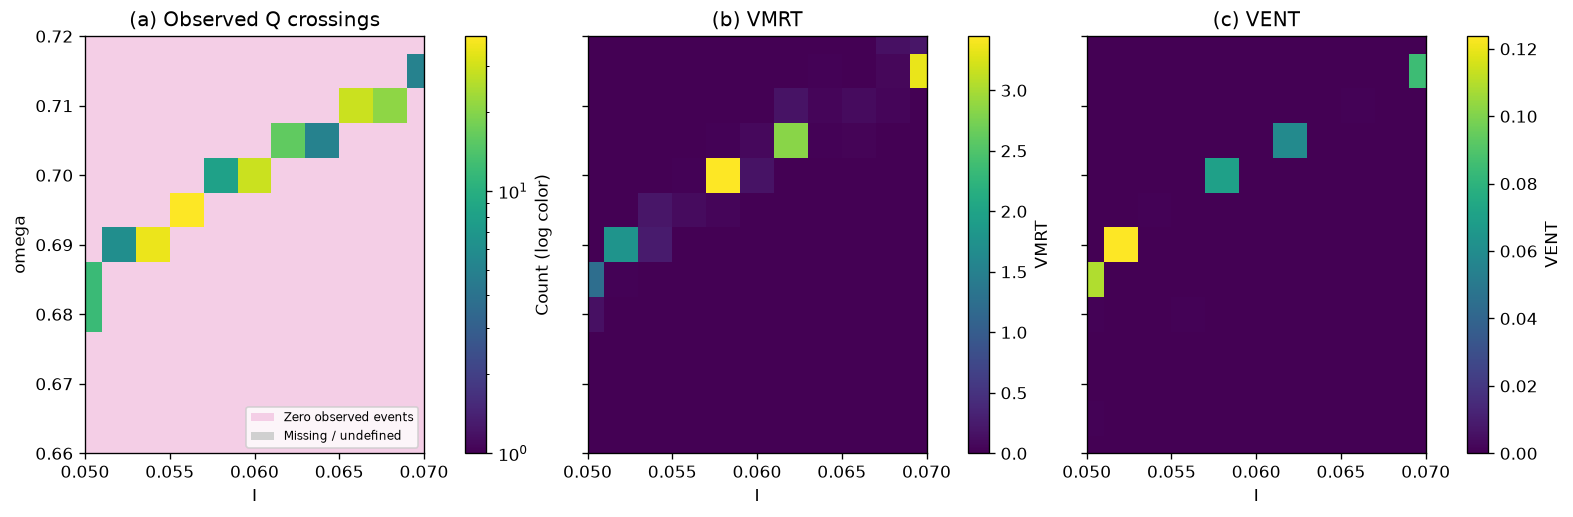

In [28]:
draw_phase3_maps(p3_snapshot)
plt.show()

**Figure:** Fig. 3(a–c), uniform coarse-grid reproduction.
**Observation:** 12/143 pairs have Q crossings along an ascending sampled band;
linear-scale maxima reach VMRT ≈ 3.45 and VENT ≈ 0.124 at localized cells.
**Scientific meaning:** both variances enhance parts of the count band, while
the controlled comparison below tests overlapping low-level variance regions.
**Reproduction status:** **partially reproduced**; the broad band orientation
agrees, but thin secondary structures, count magnitudes and the paper's much
larger VMRT values are unresolved or unmatched under unknown author settings.

### 15.4 Supplementary reproduction diagnostic — Local count-selected patch

This separate map uses a 5 × 5 rectangular patch selected from the coarse count
map alone. Its numerical protocol is identical. It illustrates resolution limits
near a sampled event-positive point and does not enter the main population
statistics, percentile thresholds or spatial component counts.

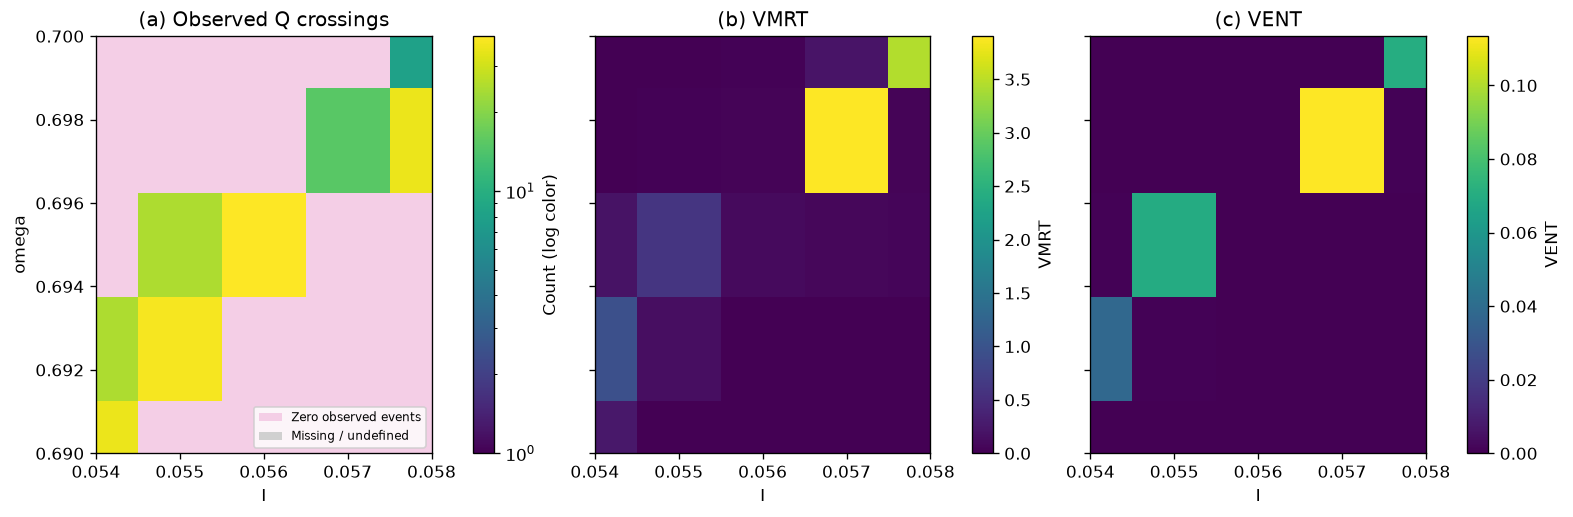

In [29]:
if p3_snapshot["fine_I"]:
    draw_phase3_maps(p3_snapshot, fine=True)
    plt.show()
else:
    print("No observed event-positive patch was available for refinement.")

**Supplementary reproduction diagnostic:** the 5 × 5 patch contains 8
count-positive cells and adds 16 new simulations. At (0.057,0.6975), 15 Q
crossings coexist with VMRT ≈ 3.90 and VENT ≈ 0.113, whereas the count-selected
center (0.056,0.695) has 39 crossings and much smaller variances. This observed
nonmonotonicity supports a distinction between count frequency and segment
heterogeneity; the adaptively selected patch is excluded from primary statistics.

## 16. Stage D — Controlled count-map versus variance-map comparison

Only the **uniform coarse grid** enters this assessment. A count >0 is an
observational reference derived from peak amplitudes, without using MRT/ENT to
assign labels; all features still share the same finite trajectory. Zero counts
are finite non-observations, not proof of impossible extremes. Missing simulations
and undefined metrics have separate denominators. The prespecified 75th-percentile
rule is applied separately to the two finite variance arrays, with inclusive
positive ties and no tuning to the count labels.

In [30]:
from scipy.ndimage import label
from scipy.stats import spearmanr

_, _, p3_counts = snapshot_grid(p3_snapshot, "count")
_, _, p3_vmrt = snapshot_grid(p3_snapshot, "vmrt")
_, _, p3_vent = snapshot_grid(p3_snapshot, "vent")
_, _, p3_large = snapshot_grid(p3_snapshot, "large_count")
p3_event_valid = np.isfinite(p3_counts)
p3_event = p3_event_valid & (p3_counts > 0)
p3_fields = {"vmrt": p3_vmrt, "vent": p3_vent}
p3_cutoffs, p3_high = {}, {}
p3_distribution_rows, p3_overlap_rows, p3_agreement_rows = [], [], []
for key, values in p3_fields.items():
    valid = p3_event_valid & np.isfinite(values)
    finite = values[valid]
    cutoff = float(np.percentile(finite, P3_PERCENTILE))
    high = valid & (values >= cutoff) & (values > 0)
    p3_cutoffs[key], p3_high[key] = cutoff, high
    groups = []
    for flag, name in (
        (False, "No observed Q crossing"),
        (True, "At least one Q crossing"),
    ):
        group = values[valid & (p3_event == flag)]
        groups.append(group)
        q = np.quantile(group, [0, 0.25, 0.5, 0.75, 1]) if len(group) else []
        p3_distribution_rows.append(
            [key, name, len(group), *(f"{x:.6g}" for x in q)]
        )
    negative, positive = groups
    if negative.size and positive.size:
        low = max(negative.min(), positive.min())
        high_end = min(negative.max(), positive.max())
        contained = np.mean(
            (positive >= negative.min()) & (positive <= negative.max())
        )
        p3_overlap_rows.append(
            [
                key,
                f"{low:.6g}",
                f"{high_end:.6g}",
                int(low <= high_end),
                f"{contained:.3f}",
            ]
        )
    p3_agreement_rows.append(
        [
            key,
            f"{cutoff:.8g}",
            int(valid.sum()),
            int((p3_event_valid & ~np.isfinite(values)).sum()),
            int((valid & p3_event).sum()),
            int(high.sum()),
            int((high & p3_event).sum()),
            int((valid & p3_event & ~high).sum()),
            int((high & ~p3_event).sum()),
        ]
    )
show_table(
    [
        "Metric",
        "Observed count class",
        "Finite cells",
        "Min",
        "Q25",
        "Median",
        "Q75",
        "Max",
    ],
    p3_distribution_rows,
)
show_table(
    [
        "Metric",
        "Range overlap low",
        "Range overlap high",
        "Overlap exists",
        "Event-positive fraction within negative range",
    ],
    p3_overlap_rows,
)
show_table(
    [
        "Metric",
        "Fixed-rule Q75 cutoff",
        "Eligible cells",
        "Undefined",
        "Event positive",
        "High variance",
        "Positive and high",
        "Positive below rule",
        "Zero-event but high",
    ],
    p3_agreement_rows,
)
print("Failed/missing count cells:", int((~p3_event_valid).sum()))
print(
    "Event-positive coarse coordinates:",
    [(float(P3_I[i]), float(P3_OMEGA[j])) for j, i in np.argwhere(p3_event)],
)

| Metric | Observed count class | Finite cells | Min | Q25 | Median | Q75 | Max |
|---|---|---|---|---|---|---|---|
| vmrt | No observed Q crossing | 131 | 0 | 5.66893e-05 | 0.00031936 | 0.00424394 | 0.193373 |
| vmrt | At least one Q crossing | 12 | 0.0237881 | 0.105991 | 0.208503 | 2.05022 | 3.4472 |
| vent | No observed Q crossing | 131 | 0 | 8.88504e-08 | 1.66317e-06 | 5.88182e-05 | 0.000720518 |
| vent | At least one Q crossing | 12 | 0.000205949 | 0.000339389 | 0.000606426 | 0.0737393 | 0.123746 |

| Metric | Range overlap low | Range overlap high | Overlap exists | Event-positive fraction within negative range |
|---|---|---|---|---|
| vmrt | 0.0237881 | 0.193373 | 1 | 0.500 |
| vent | 0.000205949 | 0.000720518 | 1 | 0.583 |

| Metric | Fixed-rule Q75 cutoff | Eligible cells | Undefined | Event positive | High variance | Positive and high | Positive below rule | Zero-event but high |
|---|---|---|---|---|---|---|---|---|
| vmrt | 0.0057643387 | 143 | 0 | 12 | 36 | 12 | 0 | 24 |
| vent | 0.00011428452 | 143 | 0 | 12 | 36 | 12 | 0 | 24 |

Failed/missing count cells: 0
Event-positive coarse coordinates: [(0.05, 0.68), (0.05, 0.685), (0.052, 0.69), (0.054, 0.69), (0.056, 0.695), (0.058, 0.7), (0.06, 0.7), (0.062, 0.705), (0.064, 0.705), (0.066, 0.71), (0.068, 0.71), (0.07, 0.715)]


The range intersection and fraction of positive cells within the negative range
quantify descriptive overlap; they are not probability-distribution overlap
estimates. A high-variance cutoff is a fixed exploratory selection rule, not an
optimized detector. The tables retain all finite values, including tiny numerical
variance in periodic records, and explicitly report metric-specific invalidity.

In [31]:
p3_frequency_rows, p3_rank_rows = [], []
for name, group_mask in (
    ("No Q; no peak > 1", p3_event_valid & ~p3_event & (p3_large == 0)),
    ("Q crossed", p3_event),
    ("No Q; peaks > 1", p3_event_valid & ~p3_event & (p3_large > 0)),
):
    row = [name, int(group_mask.sum())]
    for values in (p3_counts / 20, p3_large / 20, p3_vmrt, p3_vent):
        data = values[group_mask & np.isfinite(values)]
        row.append(f"{np.median(data):.6g}" if data.size else "undefined")
    p3_frequency_rows.append(row)
for key, values in p3_fields.items():
    for name, group in (
        ("All finite coarse", p3_event_valid),
        ("Event-positive only", p3_event),
    ):
        keep = group & np.isfinite(values)
        if keep.sum() > 2 and np.unique(p3_counts[keep]).size > 1:
            rho = float(spearmanr(p3_counts[keep], values[keep]).statistic)
        else:
            rho = np.nan
        p3_rank_rows.append([key, name, int(keep.sum()), f"{rho:.5g}"])
show_table(
    [
        "Observed group",
        "Cells",
        "Median Q rate / 1000 t",
        "Median >1 rate / 1000 t",
        "Median VMRT",
        "Median VENT",
    ],
    p3_frequency_rows,
)
show_table(
    ["Metric", "Population", "Finite cells", "Count Spearman rho"],
    p3_rank_rows,
)
print("Rate = count / 20000: count and rate ranks are identical here.")
print(
    "Rank summaries are descriptive; spatial cells are not independent trials."
)

| Observed group | Cells | Median Q rate / 1000 t | Median >1 rate / 1000 t | Median VMRT | Median VENT |
|---|---|---|---|---|---|
| No Q; no peak > 1 | 43 | 0 | 0 | 0 | 1.64061e-12 |
| Q crossed | 12 | 0.7 | 1.8 | 0.208503 | 0.000606426 |
| No Q; peaks > 1 | 88 | 0 | 15.025 | 0.00042401 | 1.83388e-06 |

| Metric | Population | Finite cells | Count Spearman rho |
|---|---|---|---|
| vmrt | All finite coarse | 143 | 0.46111 |
| vmrt | Event-positive only | 12 | -0.32338 |
| vent | All finite coarse | 143 | 0.44447 |
| vent | Event-positive only | 12 | -0.40422 |

Rate = count / 20000: count and rate ranks are identical here.
Rank summaries are descriptive; spatial cells are not independent trials.


### 16.1 Spatial mismatches on the sampled grid

Use **four-neighbor connectivity** on the uniform rectangular lattice. An observed
count boundary is a pair of successful horizontal/vertical neighbors whose
count-positive flags differ. Report mismatch component sizes and the number of
mismatches touching such a boundary. A coarse lattice may split a thin diagonal
band into isolated pixels; these components are sampled-grid descriptions,
not demonstrated connected components of an underlying dynamical regime.

In [32]:
p3_boundary = np.zeros_like(p3_event)
for axis in (0, 1):
    left = [slice(None), slice(None)]
    right = [slice(None), slice(None)]
    left[axis], right[axis] = slice(None, -1), slice(1, None)
    left, right = tuple(left), tuple(right)
    changed = (
        p3_event_valid[left]
        & p3_event_valid[right]
        & (p3_event[left] != p3_event[right])
    )
    p3_boundary[left] |= changed
    p3_boundary[right] |= changed
p3_spatial_rows, p3_counter_rows = [], []
for key, values in p3_fields.items():
    valid = p3_event_valid & np.isfinite(values)
    for name, mask in (
        ("Q positive, below high rule", valid & p3_event & ~p3_high[key]),
        ("Q zero, above high rule", valid & ~p3_event & p3_high[key]),
    ):
        components, number = label(mask)
        sizes = sorted(
            np.bincount(components.ravel())[1:].tolist(), reverse=True
        )
        p3_spatial_rows.append(
            [
                key,
                name,
                int(mask.sum()),
                number,
                str(sizes),
                int((mask & p3_boundary).sum()),
            ]
        )
        for j, i in np.argwhere(mask):
            p3_counter_rows.append(
                [
                    key,
                    name,
                    float(P3_I[i]),
                    float(P3_OMEGA[j]),
                    int(p3_counts[j, i]),
                    f"{values[j, i]:.6g}",
                ]
            )
show_table(
    [
        "Metric",
        "Mismatch",
        "Cells",
        "4-neighbor components",
        "Sizes",
        "Touch observed count boundary",
    ],
    p3_spatial_rows,
)
show_table(
    ["Metric", "Mismatch", "I", "omega", "NQ", "Variance"], p3_counter_rows
)

| Metric | Mismatch | Cells | 4-neighbor components | Sizes | Touch observed count boundary |
|---|---|---|---|---|---|
| vmrt | Q positive, below high rule | 0 | 0 | [] | 0 |
| vmrt | Q zero, above high rule | 24 | 16 | [3, 3, 2, 2, 2, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1] | 14 |
| vent | Q positive, below high rule | 0 | 0 | [] | 0 |
| vent | Q zero, above high rule | 24 | 14 | [4, 3, 2, 2, 2, 2, 2, 1, 1, 1, 1, 1, 1, 1] | 12 |

| Metric | Mismatch | I | omega | NQ | Variance |
|---|---|---|---|---|---|
| vmrt | Q zero, above high rule | 0.05 | 0.665 | 0 | 0.00801114 |
| vmrt | Q zero, above high rule | 0.052 | 0.675 | 0 | 0.0107192 |
| vmrt | Q zero, above high rule | 0.054 | 0.68 | 0 | 0.0065269 |
| vmrt | Q zero, above high rule | 0.052 | 0.685 | 0 | 0.0223646 |
| vmrt | Q zero, above high rule | 0.056 | 0.685 | 0 | 0.0110081 |
| vmrt | Q zero, above high rule | 0.06 | 0.685 | 0 | 0.00662965 |
| vmrt | Q zero, above high rule | 0.056 | 0.69 | 0 | 0.00722747 |
| vmrt | Q zero, above high rule | 0.06 | 0.69 | 0 | 0.0107215 |
| vmrt | Q zero, above high rule | 0.054 | 0.695 | 0 | 0.188984 |
| vmrt | Q zero, above high rule | 0.058 | 0.695 | 0 | 0.0506729 |
| vmrt | Q zero, above high rule | 0.064 | 0.695 | 0 | 0.00577648 |
| vmrt | Q zero, above high rule | 0.066 | 0.695 | 0 | 0.00641211 |
| vmrt | Q zero, above high rule | 0.056 | 0.7 | 0 | 0.0174334 |
| vmrt | Q zero, above high rule | 0.062 | 0.7 | 0 | 0.0130707 |
| vmrt | Q zero, above high rule | 0.058 | 0.705 | 0 | 0.0190955 |
| vmrt | Q zero, above high rule | 0.06 | 0.705 | 0 | 0.0736348 |
| vmrt | Q zero, above high rule | 0.066 | 0.705 | 0 | 0.0269403 |
| vmrt | Q zero, above high rule | 0.062 | 0.71 | 0 | 0.169643 |
| vmrt | Q zero, above high rule | 0.064 | 0.71 | 0 | 0.0459681 |
| vmrt | Q zero, above high rule | 0.07 | 0.71 | 0 | 0.00713929 |
| vmrt | Q zero, above high rule | 0.064 | 0.715 | 0 | 0.0155086 |
| vmrt | Q zero, above high rule | 0.068 | 0.715 | 0 | 0.0663313 |
| vmrt | Q zero, above high rule | 0.068 | 0.72 | 0 | 0.145278 |
| vmrt | Q zero, above high rule | 0.07 | 0.72 | 0 | 0.193373 |
| vent | Q zero, above high rule | 0.05 | 0.665 | 0 | 0.000720518 |
| vent | Q zero, above high rule | 0.052 | 0.67 | 0 | 0.000130729 |
| vent | Q zero, above high rule | 0.052 | 0.675 | 0 | 0.000153606 |
| vent | Q zero, above high rule | 0.056 | 0.675 | 0 | 0.000472153 |
| vent | Q zero, above high rule | 0.056 | 0.68 | 0 | 0.000582553 |
| vent | Q zero, above high rule | 0.058 | 0.68 | 0 | 0.000238323 |
| vent | Q zero, above high rule | 0.052 | 0.685 | 0 | 0.000379541 |
| vent | Q zero, above high rule | 0.054 | 0.685 | 0 | 0.000169718 |
| vent | Q zero, above high rule | 0.062 | 0.685 | 0 | 0.000124747 |
| vent | Q zero, above high rule | 0.058 | 0.69 | 0 | 0.000115688 |
| vent | Q zero, above high rule | 0.062 | 0.69 | 0 | 0.000119854 |
| vent | Q zero, above high rule | 0.054 | 0.695 | 0 | 0.000706017 |
| vent | Q zero, above high rule | 0.058 | 0.695 | 0 | 0.000218996 |
| vent | Q zero, above high rule | 0.068 | 0.695 | 0 | 0.000425345 |
| vent | Q zero, above high rule | 0.056 | 0.7 | 0 | 0.00014694 |
| vent | Q zero, above high rule | 0.062 | 0.7 | 0 | 0.000414289 |
| vent | Q zero, above high rule | 0.064 | 0.7 | 0 | 0.000157487 |
| vent | Q zero, above high rule | 0.066 | 0.705 | 0 | 0.000439151 |
| vent | Q zero, above high rule | 0.062 | 0.71 | 0 | 0.000208763 |
| vent | Q zero, above high rule | 0.07 | 0.71 | 0 | 0.000207557 |
| vent | Q zero, above high rule | 0.068 | 0.715 | 0 | 0.000398619 |
| vent | Q zero, above high rule | 0.066 | 0.72 | 0 | 0.000146034 |
| vent | Q zero, above high rule | 0.068 | 0.72 | 0 | 0.000221725 |
| vent | Q zero, above high rule | 0.07 | 0.72 | 0 | 0.000117843 |

### 16.2 Supplementary reproduction diagnostic — Rates and mismatch locations

The top row plots variance versus measured Q-crossing rate for all successful
uniform-grid records (positive and zero-event classes shown separately). The
bottom row displays the same prespecified-cutoff mismatches at their original
parameter coordinates. No smoothing, interpolation, classification training or
assumption of monotonic variance with event frequency is introduced.

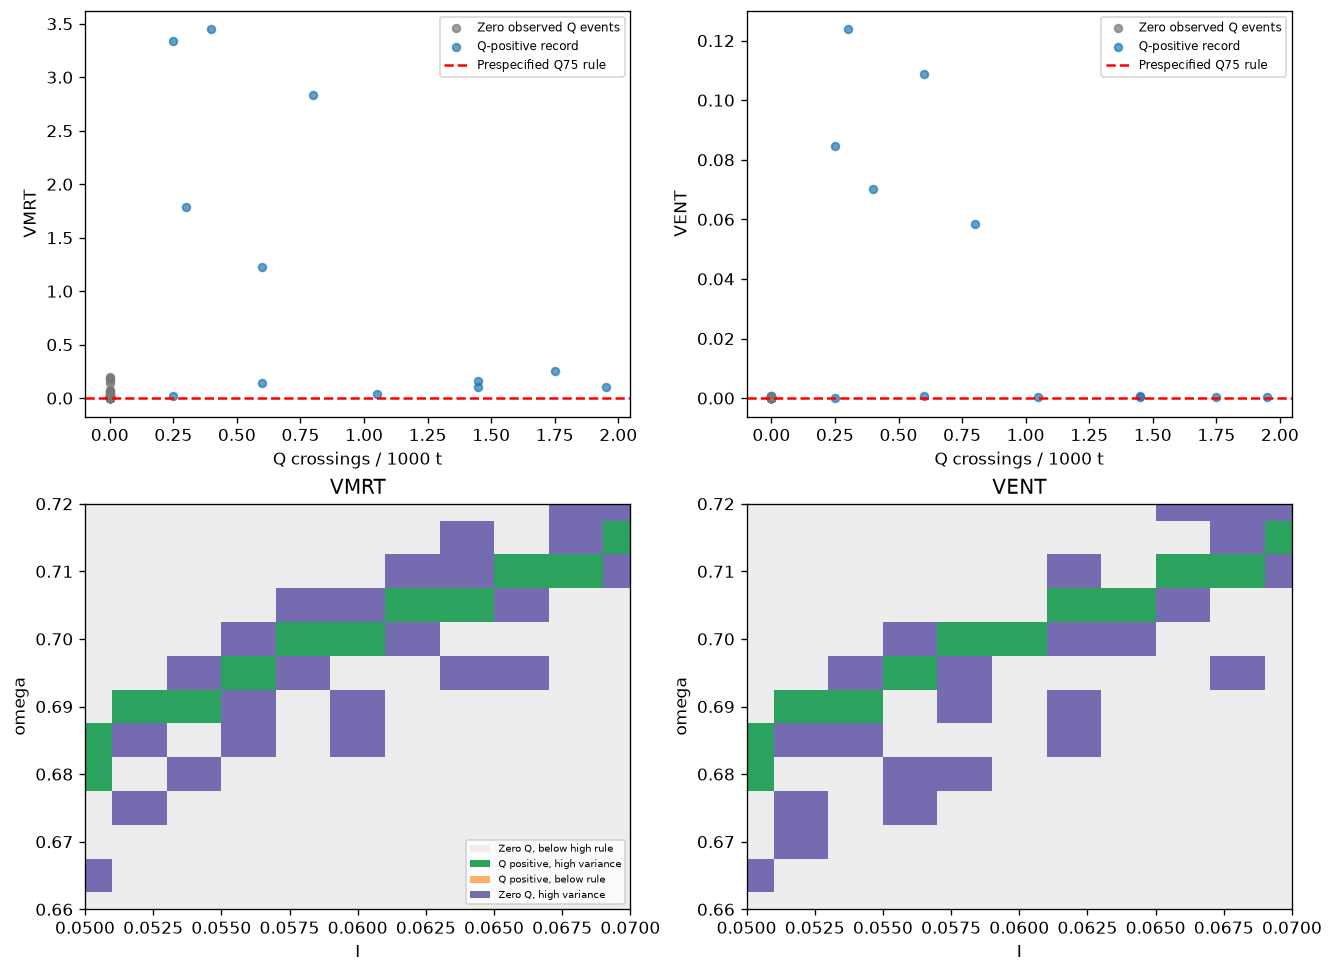

In [33]:
from matplotlib.colors import BoundaryNorm, ListedColormap

fig, axes = plt.subplots(2, 2, figsize=(11, 8), layout="constrained")
colors = ["#ededed", "#2ca25f", "#fdae6b", "#756bb1"]
categories = ListedColormap(colors)
for column, (key, values) in enumerate(p3_fields.items()):
    valid = p3_event_valid & np.isfinite(values)
    for flag, name, color in (
        (False, "Zero observed Q events", "#777777"),
        (True, "Q-positive record", "#1f77b4"),
    ):
        mask = valid & (p3_event == flag)
        axes[0, column].scatter(
            p3_counts[mask] / 20,
            values[mask],
            s=22,
            alpha=0.7,
            label=name,
            color=color,
        )
    axes[0, column].axhline(
        p3_cutoffs[key], color="red", ls="--", label="Prespecified Q75 rule"
    )
    axes[0, column].set(xlabel="Q crossings / 1000 t", ylabel=key.upper())
    axes[0, column].legend(fontsize=7)
    category = np.full_like(values, np.nan)
    category[valid] = 0
    category[valid & p3_event & p3_high[key]] = 1
    category[valid & p3_event & ~p3_high[key]] = 2
    category[valid & ~p3_event & p3_high[key]] = 3
    categories.set_bad("#333333")
    axes[1, column].pcolormesh(
        coordinate_edges(P3_I),
        coordinate_edges(P3_OMEGA),
        np.ma.masked_invalid(category),
        cmap=categories,
        norm=BoundaryNorm(np.arange(-0.5, 4.5), categories.N),
        shading="flat",
    )
    axes[1, column].set(
        xlim=(0.05, 0.07),
        ylim=(0.66, 0.72),
        xlabel="I",
        ylabel="omega",
        title=key.upper(),
    )
axes[1, 0].legend(
    handles=[
        Patch(facecolor=color, label=name)
        for color, name in zip(
            colors,
            (
                "Zero Q, below high rule",
                "Q positive, high variance",
                "Q positive, below rule",
                "Zero Q, high variance",
            ),
            strict=True,
        )
    ],
    fontsize=6,
    loc="lower right",
)
plt.show()

**Supplementary reproduction diagnostic:** all 12 Q-positive coarse cells
satisfy each variance's prespecified rule, while each high-variance region also
contains 24 zero-event cells. Observed ranges overlap, and within positive cells
count/variance rank correlations are negative (VMRT −0.323, VENT −0.404).
These are descriptive in-sample results; lattice mismatches and variance
magnitudes do not establish a transition mechanism or classification performance.

## 17. Stage E — Targeted robustness, with selection rules fixed

Select at most one **lexicographically first (I, ω)** coarse pair from each
observed category: zero Q and neither variance high; positive Q and both high;
positive Q with at least one variance below the rule; zero Q with at least one
variance high. Empty categories are reported, not filled from another population.
These are deliberately diagnostic cases, not independent validation samples.

For each selected pair compare: baseline 20,000; pooled σ on exactly those peaks;
T = 1,000 (k = 20) on the same record; m = 25 alone; a 60,000 retained record
(T = 2,000, k = 30); and one alternative initial state (0.1, 6.0) at baseline
length. Each alternative changes one choice. High-rule cutoffs remain frozen
from the primary coarse map. A fixed raw display [10,000,14,000), obtained
from the long record, supplies independent amplitude evidence without searching
for favorable bursts; the full chronological peak series and PDF are also shown.

In [34]:
p3_selected = []
p3_joint_valid = p3_event_valid & np.isfinite(p3_vmrt) & np.isfinite(p3_vent)
category_masks = (
    (
        "zero Q / neither high",
        p3_joint_valid & ~p3_event & ~p3_high["vmrt"] & ~p3_high["vent"],
    ),
    (
        "positive Q / both high",
        p3_joint_valid & p3_event & p3_high["vmrt"] & p3_high["vent"],
    ),
    (
        "positive Q / at least one low",
        p3_joint_valid & p3_event & ~(p3_high["vmrt"] & p3_high["vent"]),
    ),
    (
        "zero Q / at least one high",
        p3_joint_valid & ~p3_event & (p3_high["vmrt"] | p3_high["vent"]),
    ),
)
for name, mask in category_masks:
    candidates = sorted(
        (float(P3_I[i]), float(P3_OMEGA[j])) for j, i in np.argwhere(mask)
    )
    if candidates:
        p3_selected.append((name, candidates[0]))
    else:
        print("No coarse representative available:", name)
show_table(
    ["Diagnostic category", "I", "omega"],
    [[name, *pair] for name, pair in p3_selected],
)

No coarse representative available: positive Q / at least one low


| Diagnostic category | I | omega |
|---|---|---|
| zero Q / neither high | 0.05 | 0.66 |
| positive Q / both high | 0.05 | 0.68 |
| zero Q / at least one high | 0.05 | 0.665 |

In [35]:
p3_robust_results, p3_long_records, p3_robust_rows = [], {}, []
p3_prefix_rows, p3_segment_rows = [], []
for name, pair in p3_selected:
    baseline = p3_metrics[pair]
    base_record = p3_records[pair]
    alternatives = (
        ("baseline", {}),
        ("pooled sigma only", {"sigma_scope": "pooled"}),
        ("T=1000 only", {"duration": 1000.0}),
        ("m=25 only", {"bins": 25}),
    )
    for option, changes in alternatives:
        metrics = describe_record(base_record, **changes)
        p3_robust_results.append((name, pair, option, metrics))
        if option == "pooled sigma only":
            np.testing.assert_allclose(
                [metrics["entropy"], metrics["vent"]],
                [baseline["entropy"], baseline["vent"]],
                equal_nan=True,
            )
        if option == "m=25 only":
            np.testing.assert_allclose(
                [metrics["mrt"], metrics["vmrt"]],
                [baseline["mrt"], baseline["vmrt"]],
                equal_nan=True,
            )
        if option in ("baseline", "T=1000 only"):
            for j, segment in enumerate(metrics["segments"]):
                p3_segment_rows.append(
                    [
                        *pair,
                        option,
                        j,
                        len(segment["peaks"]),
                        f"{segment['epsilon']:.6g}",
                        f"{segment['mrt']:.6g}",
                        f"{segment['entropy']:.6g}",
                    ]
                )
    settings = {**P3_SETTINGS, "duration": 60_000.0, "trace_duration": 4000.0}
    long_record = cached_phase3(pair, settings)
    p3_long_records[pair] = long_record
    longest = describe_record(long_record)
    p3_robust_results.append((name, pair, "length=60000 only", longest))
    prefix = describe_record(long_record, length=20_000)
    common_count = int(np.sum(prefix["peaks"] > longest["threshold"]))
    p3_prefix_rows.append(
        [
            *pair,
            baseline["count"],
            prefix["count"],
            common_count,
            longest["count"],
            f"{prefix['threshold']:.6g}",
            f"{longest['threshold']:.6g}",
        ]
    )
    if prefix["peak_count"] == baseline["peak_count"]:
        print(
            "Nested prefix maximum peak-amplitude difference",
            pair,
            np.max(np.abs(prefix["peaks"] - baseline["peaks"])),
        )
    else:
        print(
            "Nested-prefix peak count differs",
            pair,
            prefix["peak_count"],
            baseline["peak_count"],
        )
    alternate = cached_phase3(
        pair, {**P3_SETTINGS, "initial_state": (0.1, 6.0)}
    )
    metrics = describe_record(alternate)
    p3_robust_results.append((name, pair, "initial=(0.1,6) only", metrics))
    print("Completed targeted checks:", name, pair, flush=True)
for _name, pair, option, metrics in p3_robust_results:
    p3_robust_rows.append(
        [
            *pair,
            option,
            int(metrics["duration"]),
            len(metrics["segments"]),
            metrics["peak_count"],
            metrics["count"],
            f"{1000 * metrics['rate']:.5g}",
            metrics["large_count"],
            *(
                f"{metrics[key]:.6g}"
                for key in ("mrt", "vmrt", "entropy", "vent")
            ),
            str(metrics["invalid_mrt"]),
            str(metrics["invalid_entropy"]),
            str(
                {
                    key: (
                        None
                        if not np.isfinite(metrics[key])
                        else bool(
                            metrics[key] > 0
                            and metrics[key] >= p3_cutoffs[key]
                        )
                    )
                    for key in ("vmrt", "vent")
                }
            ),
        ]
    )
show_table(
    [
        "I",
        "omega",
        "One changed choice",
        "Retained t",
        "k",
        "Peaks",
        "NQ",
        "Rate / 1000 t",
        "Peaks >1",
        "Mean MRT",
        "VMRT",
        "Mean ENT",
        "VENT",
        "Invalid MRT",
        "Invalid ENT",
        "Frozen-rule high flags",
    ],
    p3_robust_rows,
)
show_table(
    [
        "I",
        "omega",
        "Baseline NQ",
        "Long prefix own-Q NQ",
        "Prefix above long Q",
        "Long NQ",
        "Prefix Q",
        "Long Q",
    ],
    p3_prefix_rows,
)

Nested prefix maximum peak-amplitude difference (0.05, 0.66) 0.0
Completed targeted checks: zero Q / neither high (0.05, 0.66)


Nested prefix maximum peak-amplitude difference (0.05, 0.68) 0.0
Completed targeted checks: positive Q / both high (0.05, 0.68)


Nested prefix maximum peak-amplitude difference (0.05, 0.665) 0.0
Completed targeted checks: zero Q / at least one high (0.05, 0.665)


| I | omega | One changed choice | Retained t | k | Peaks | NQ | Rate / 1000 t | Peaks >1 | Mean MRT | VMRT | Mean ENT | VENT | Invalid MRT | Invalid ENT | Frozen-rule high flags |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| 0.05 | 0.66 | baseline | 20000 | 10 | 2101 | 0 | 0 | 301 | 1.71847 | 0.000174823 | 0.203693 | 1.89234e-07 | [] | [] | {'vmrt': False, 'vent': False} |
| 0.05 | 0.66 | pooled sigma only | 20000 | 10 | 2101 | 0 | 0 | 301 | 1.71847 | 0.000174823 | 0.203693 | 1.89234e-07 | [] | [] | {'vmrt': False, 'vent': False} |
| 0.05 | 0.66 | T=1000 only | 20000 | 20 | 2101 | 0 | 0 | 301 | 1.71857 | 0.000367347 | 0.20369 | 3.65874e-07 | [] | [] | {'vmrt': False, 'vent': False} |
| 0.05 | 0.66 | m=25 only | 20000 | 10 | 2101 | 0 | 0 | 301 | 1.71847 | 0.000174823 | 0.127634 | 5.01969e-07 | [] | [] | {'vmrt': False, 'vent': False} |
| 0.05 | 0.66 | length=60000 only | 60000 | 30 | 6303 | 0 | 0 | 901 | 1.70179 | 0.000198811 | 0.203564 | 8.66675e-08 | [] | [] | {'vmrt': False, 'vent': False} |
| 0.05 | 0.66 | initial=(0.1,6) only | 20000 | 10 | 2101 | 0 | 0 | 301 | 1.71847 | 0.000174823 | 0.203693 | 1.89234e-07 | [] | [] | {'vmrt': False, 'vent': False} |
| 0.05 | 0.68 | baseline | 20000 | 10 | 2102 | 12 | 0.6 | 63 | 1.98209 | 0.139152 | 0.323827 | 0.000579952 | [] | [] | {'vmrt': True, 'vent': True} |
| 0.05 | 0.68 | pooled sigma only | 20000 | 10 | 2102 | 12 | 0.6 | 63 | 1.76667 | 0.00547789 | 0.323827 | 0.000579952 | [] | [] | {'vmrt': False, 'vent': True} |
| 0.05 | 0.68 | T=1000 only | 20000 | 20 | 2102 | 12 | 0.6 | 63 | 1.81269 | 0.10829 | 0.324666 | 0.00112864 | [] | [] | {'vmrt': True, 'vent': True} |
| 0.05 | 0.68 | m=25 only | 20000 | 10 | 2102 | 12 | 0.6 | 63 | 1.98209 | 0.139152 | 0.257657 | 0.000369691 | [] | [] | {'vmrt': True, 'vent': True} |
| 0.05 | 0.68 | length=60000 only | 60000 | 30 | 6286 | 0 | 0 | 206 | 1.84814 | 0.0681377 | 0.329877 | 0.00048502 | [] | [] | {'vmrt': True, 'vent': True} |
| 0.05 | 0.68 | initial=(0.1,6) only | 20000 | 10 | 2101 | 10 | 0.5 | 64 | 1.84242 | 0.0380698 | 0.315013 | 0.00084356 | [] | [] | {'vmrt': True, 'vent': True} |
| 0.05 | 0.665 | baseline | 20000 | 10 | 1864 | 0 | 0 | 268 | 1.69052 | 0.00801114 | 0.362402 | 0.000720518 | [] | [] | {'vmrt': True, 'vent': True} |
| 0.05 | 0.665 | pooled sigma only | 20000 | 10 | 1864 | 0 | 0 | 268 | 1.69198 | 0.00783198 | 0.362402 | 0.000720518 | [] | [] | {'vmrt': True, 'vent': True} |
| 0.05 | 0.665 | T=1000 only | 20000 | 20 | 1864 | 0 | 0 | 268 | 1.63181 | 0.00648093 | 0.353793 | 0.000971597 | [] | [] | {'vmrt': True, 'vent': True} |
| 0.05 | 0.665 | m=25 only | 20000 | 10 | 1864 | 0 | 0 | 268 | 1.69052 | 0.00801114 | 0.267727 | 0.000699863 | [] | [] | {'vmrt': True, 'vent': True} |
| 0.05 | 0.665 | length=60000 only | 60000 | 30 | 5592 | 0 | 0 | 799 | 1.70863 | 0.00427082 | 0.367322 | 0.000545447 | [] | [] | {'vmrt': False, 'vent': True} |
| 0.05 | 0.665 | initial=(0.1,6) only | 20000 | 10 | 1861 | 0 | 0 | 261 | 1.69449 | 0.00337786 | 0.37056 | 0.00155554 | [] | [] | {'vmrt': False, 'vent': True} |

| I | omega | Baseline NQ | Long prefix own-Q NQ | Prefix above long Q | Long NQ | Prefix Q | Long Q |
|---|---|---|---|---|---|---|---|
| 0.05 | 0.66 | 0 | 0 | 0 | 0 | 7.07679 | 7.06988 |
| 0.05 | 0.68 | 12 | 12 | 0 | 0 | 3.16766 | 3.27238 |
| 0.05 | 0.665 | 0 | 0 | 0 | 0 | 6.44908 | 6.41288 |

The longer-record qualifier is re-estimated on its full peaks, so changes in
counts combine extra observation with a moving Q. The common-long-Q prefix
column separates these effects descriptively. Neither prefix agreement nor a
longer integration proves statistical convergence. The following complete
segment-level table documents changes in estimates and peak counts under
T = 2,000 versus 1,000 on each **same 20,000-time-unit trajectory**.

In [36]:
show_table(
    [
        "I",
        "omega",
        "Segmentation",
        "Segment index",
        "Peaks",
        "epsilon",
        "MRT",
        "ENT",
    ],
    p3_segment_rows,
)
p3_diagnostics = []
for name, pair in p3_selected:
    record = p3_long_records[pair]
    metrics = describe_record(record)
    density, edges = np.histogram(metrics["peaks"], bins=100, density=True)
    np.testing.assert_allclose(np.sum(density * np.diff(edges)), 1)
    p3_diagnostics.append(
        json_compatible(
            {
                "category": name,
                "I": pair[0],
                "omega": pair[1],
                "trace_time": record["trace_time"],
                "trace_u1": record["trace_u1"],
                "peak_time": metrics["peak_time"],
                "peaks": metrics["peaks"],
                "Q": metrics["threshold"],
                "count": metrics["count"],
                "pdf": density,
                "edges": edges,
            }
        )
    )

| I | omega | Segmentation | Segment index | Peaks | epsilon | MRT | ENT |
|---|---|---|---|---|---|---|---|
| 0.05 | 0.66 | baseline | 0 | 210 | 0.32315 | 1.71429 | 0.203555 |
| 0.05 | 0.66 | baseline | 1 | 210 | 0.323136 | 1.71429 | 0.203555 |
| 0.05 | 0.66 | baseline | 2 | 210 | 0.323159 | 1.71429 | 0.203555 |
| 0.05 | 0.66 | baseline | 3 | 210 | 0.323149 | 1.71429 | 0.203555 |
| 0.05 | 0.66 | baseline | 4 | 211 | 0.326952 | 1.7561 | 0.204931 |
| 0.05 | 0.66 | baseline | 5 | 210 | 0.323158 | 1.71429 | 0.203555 |
| 0.05 | 0.66 | baseline | 6 | 210 | 0.323149 | 1.71429 | 0.203555 |
| 0.05 | 0.66 | baseline | 7 | 210 | 0.323157 | 1.71429 | 0.203555 |
| 0.05 | 0.66 | baseline | 8 | 210 | 0.323136 | 1.71429 | 0.203555 |
| 0.05 | 0.66 | baseline | 9 | 210 | 0.32315 | 1.71429 | 0.203555 |
| 0.05 | 0.66 | T=1000 only | 0 | 105 | 0.323146 | 1.71429 | 0.203555 |
| 0.05 | 0.66 | T=1000 only | 1 | 105 | 0.323155 | 1.71429 | 0.203555 |
| 0.05 | 0.66 | T=1000 only | 2 | 105 | 0.323145 | 1.71429 | 0.203555 |
| 0.05 | 0.66 | T=1000 only | 3 | 105 | 0.323127 | 1.71429 | 0.203555 |
| 0.05 | 0.66 | T=1000 only | 4 | 105 | 0.323152 | 1.71429 | 0.203555 |
| 0.05 | 0.66 | T=1000 only | 5 | 105 | 0.323165 | 1.71429 | 0.203555 |
| 0.05 | 0.66 | T=1000 only | 6 | 105 | 0.323161 | 1.71429 | 0.203555 |
| 0.05 | 0.66 | T=1000 only | 7 | 105 | 0.323138 | 1.71429 | 0.203555 |
| 0.05 | 0.66 | T=1000 only | 8 | 106 | 0.330614 | 1.8 | 0.20626 |
| 0.05 | 0.66 | T=1000 only | 9 | 105 | 0.323169 | 1.71429 | 0.203555 |
| 0.05 | 0.66 | T=1000 only | 10 | 105 | 0.323168 | 1.71429 | 0.203555 |
| 0.05 | 0.66 | T=1000 only | 11 | 105 | 0.323148 | 1.71429 | 0.203555 |
| 0.05 | 0.66 | T=1000 only | 12 | 105 | 0.323137 | 1.71429 | 0.203555 |
| 0.05 | 0.66 | T=1000 only | 13 | 105 | 0.32316 | 1.71429 | 0.203555 |
| 0.05 | 0.66 | T=1000 only | 14 | 105 | 0.323164 | 1.71429 | 0.203555 |
| 0.05 | 0.66 | T=1000 only | 15 | 105 | 0.32315 | 1.71429 | 0.203555 |
| 0.05 | 0.66 | T=1000 only | 16 | 105 | 0.323126 | 1.71429 | 0.203555 |
| 0.05 | 0.66 | T=1000 only | 17 | 105 | 0.323145 | 1.71429 | 0.203555 |
| 0.05 | 0.66 | T=1000 only | 18 | 105 | 0.323155 | 1.71429 | 0.203555 |
| 0.05 | 0.66 | T=1000 only | 19 | 105 | 0.323146 | 1.71429 | 0.203555 |
| 0.05 | 0.68 | baseline | 0 | 210 | 0.150705 | 1.7801 | 0.332684 |
| 0.05 | 0.68 | baseline | 1 | 208 | 0.162817 | 1.72337 | 0.33401 |
| 0.05 | 0.68 | baseline | 2 | 207 | 0.171369 | 1.7878 | 0.369711 |
| 0.05 | 0.68 | baseline | 3 | 211 | 0.122558 | 2.15161 | 0.331601 |
| 0.05 | 0.68 | baseline | 4 | 213 | 0.0957241 | 2.88183 | 0.296702 |
| 0.05 | 0.68 | baseline | 5 | 211 | 0.141376 | 1.76667 | 0.307396 |
| 0.05 | 0.68 | baseline | 6 | 211 | 0.126129 | 2.09627 | 0.31964 |
| 0.05 | 0.68 | baseline | 7 | 213 | 0.118244 | 2.22046 | 0.283489 |
| 0.05 | 0.68 | baseline | 8 | 209 | 0.155103 | 1.71987 | 0.324343 |
| 0.05 | 0.68 | baseline | 9 | 209 | 0.153046 | 1.69296 | 0.338692 |
| 0.05 | 0.68 | T=1000 only | 0 | 105 | 0.157677 | 1.76104 | 0.367629 |
| 0.05 | 0.68 | T=1000 only | 1 | 105 | 0.143319 | 1.48162 | 0.30941 |
| 0.05 | 0.68 | T=1000 only | 2 | 104 | 0.161874 | 1.64193 | 0.33417 |
| 0.05 | 0.68 | T=1000 only | 3 | 104 | 0.163756 | 1.7551 | 0.343345 |
| 0.05 | 0.68 | T=1000 only | 4 | 102 | 0.188773 | 1.47351 | 0.382074 |
| 0.05 | 0.68 | T=1000 only | 5 | 105 | 0.152277 | 1.47929 | 0.352162 |
| 0.05 | 0.68 | T=1000 only | 6 | 105 | 0.131928 | 1.65015 | 0.343931 |
| 0.05 | 0.68 | T=1000 only | 7 | 106 | 0.11246 | 2.09705 | 0.318294 |
| 0.05 | 0.68 | T=1000 only | 8 | 106 | 0.107514 | 2.38645 | 0.313783 |
| 0.05 | 0.68 | T=1000 only | 9 | 107 | 0.0823315 | 2.28448 | 0.26997 |
| 0.05 | 0.68 | T=1000 only | 10 | 106 | 0.138476 | 1.57067 | 0.29823 |
| 0.05 | 0.68 | T=1000 only | 11 | 105 | 0.144243 | 1.70662 | 0.30933 |
| 0.05 | 0.68 | T=1000 only | 12 | 105 | 0.13671 | 1.90034 | 0.330965 |
| 0.05 | 0.68 | T=1000 only | 13 | 106 | 0.11461 | 2.34649 | 0.312181 |
| 0.05 | 0.68 | T=1000 only | 14 | 108 | 0.0848897 | 2.30909 | 0.240602 |
| 0.05 | 0.68 | T=1000 only | 15 | 105 | 0.14441 | 1.4682 | 0.314569 |
| 0.05 | 0.68 | T=1000 only | 16 | 104 | 0.165774 | 1.67108 | 0.335229 |
| 0.05 | 0.68 | T=1000 only | 17 | 105 | 0.143678 | 1.57245 | 0.300356 |
| 0.05 | 0.68 | T=1000 only | 18 | 106 | 0.120852 | 2.18043 | 0.353218 |
| 0.05 | 0.68 | T=1000 only | 19 | 103 | 0.1799 | 1.51782 | 0.363866 |
| 0.05 | 0.665 | baseline | 0 | 184 | 0.292463 | 1.5799 | 0.361917 |
| 0.05 | 0.665 | baseline | 1 | 189 | 0.27213 | 1.50256 | 0.405847 |
| 0.05 | 0.665 | baseline | 2 | 187 | 0.289944 | 1.74502 | 0.372799 |
| 0.05 | 0.665 | baseline | 3 | 185 | 0.306274 | 1.70711 | 0.337421 |
| 0.05 | 0.665 | baseline | 4 | 187 | 0.304463 | 1.68856 | 0.328769 |
| 0.05 | 0.665 | baseline | 5 | 187 | 0.288162 | 1.8156 | 0.389349 |
| 0.05 | 0.665 | baseline | 6 | 186 | 0.29482 | 1.74045 | 0.362702 |
| 0.05 | 0.665 | baseline | 7 | 186 | 0.304565 | 1.7185 | 0.323373 |
| 0.05 | 0.665 | baseline | 8 | 186 | 0.296912 | 1.73549 | 0.357899 |
| 0.05 | 0.665 | baseline | 9 | 187 | 0.281764 | 1.67202 | 0.38394 |
| 0.05 | 0.665 | T=1000 only | 0 | 93 | 0.308749 | 1.63175 | 0.323252 |
| 0.05 | 0.665 | T=1000 only | 1 | 91 | 0.274567 | 1.58234 | 0.374635 |
| 0.05 | 0.665 | T=1000 only | 2 | 93 | 0.283553 | 1.51289 | 0.388035 |
| 0.05 | 0.665 | T=1000 only | 3 | 96 | 0.260471 | 1.58554 | 0.396733 |
| 0.05 | 0.665 | T=1000 only | 4 | 92 | 0.317923 | 1.71429 | 0.311592 |
| 0.05 | 0.665 | T=1000 only | 5 | 95 | 0.258577 | 1.48971 | 0.398774 |
| 0.05 | 0.665 | T=1000 only | 6 | 93 | 0.300813 | 1.61958 | 0.342134 |
| 0.05 | 0.665 | T=1000 only | 7 | 92 | 0.311617 | 1.66717 | 0.329042 |
| 0.05 | 0.665 | T=1000 only | 8 | 94 | 0.305816 | 1.6248 | 0.318836 |
| 0.05 | 0.665 | T=1000 only | 9 | 93 | 0.30309 | 1.69071 | 0.334684 |
| 0.05 | 0.665 | T=1000 only | 10 | 95 | 0.272772 | 1.70529 | 0.400475 |
| 0.05 | 0.665 | T=1000 only | 11 | 92 | 0.302913 | 1.65503 | 0.351857 |
| 0.05 | 0.665 | T=1000 only | 12 | 93 | 0.271981 | 1.619 | 0.383895 |
| 0.05 | 0.665 | T=1000 only | 13 | 93 | 0.315371 | 1.67878 | 0.316724 |
| 0.05 | 0.665 | T=1000 only | 14 | 93 | 0.304667 | 1.66667 | 0.328155 |
| 0.05 | 0.665 | T=1000 only | 15 | 93 | 0.304463 | 1.67255 | 0.324344 |
| 0.05 | 0.665 | T=1000 only | 16 | 92 | 0.301578 | 1.69628 | 0.335547 |
| 0.05 | 0.665 | T=1000 only | 17 | 94 | 0.292256 | 1.75043 | 0.362227 |
| 0.05 | 0.665 | T=1000 only | 18 | 92 | 0.302334 | 1.64839 | 0.362897 |
| 0.05 | 0.665 | T=1000 only | 19 | 95 | 0.259453 | 1.4249 | 0.392032 |

### 17.1 Supplementary reproduction diagnostic — Contradictory records

For each count/variance-selected pair show a fixed, predeclared raw interval
[10,000,14,000), the chronological peaks from the full 60,000 retained record,
and a 100-bin normalized full-peak PDF. Raw traces use Δt = 0.25 drawing samples;
statistics and overlaid maxima use the original Δt = 0.05. The long-record Q is
shown separately from the original coarse-record selection. A short raw window
may contain no rare event; the full peak sequence and PDF retain that evidence.

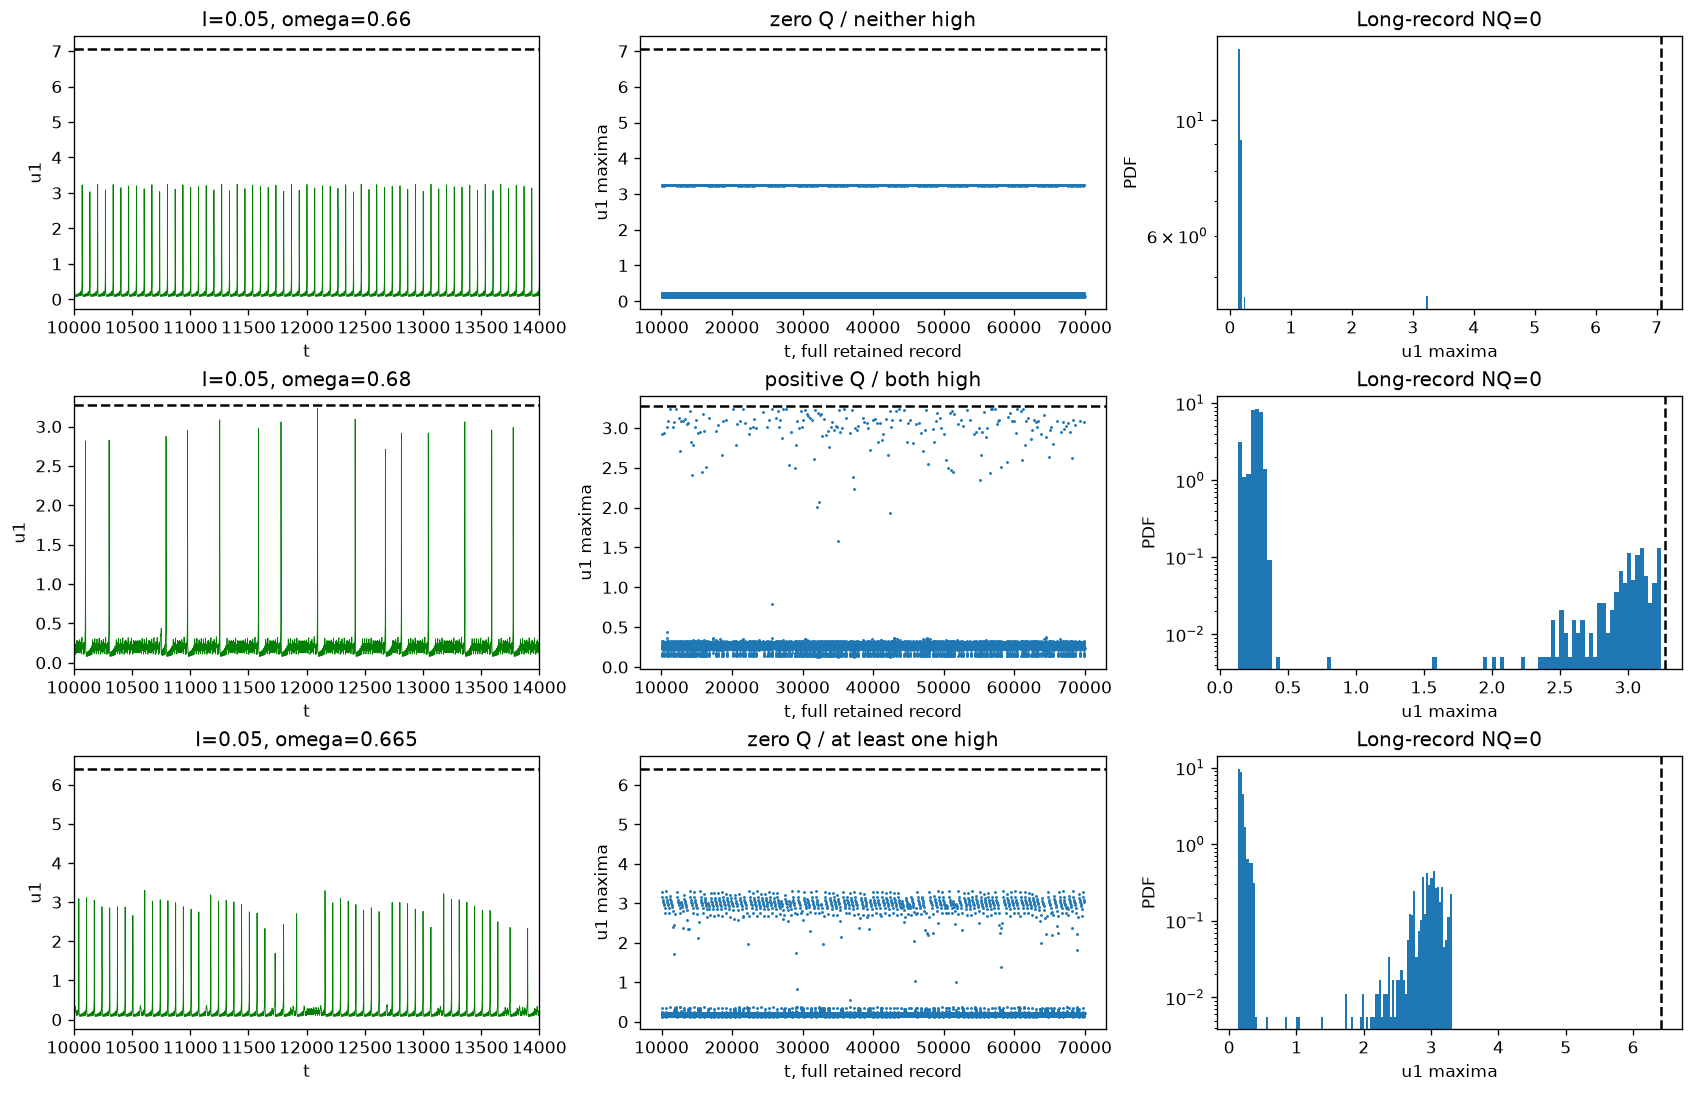

In [37]:
fig, axes = plt.subplots(
    len(p3_diagnostics),
    3,
    figsize=(14, 3 * len(p3_diagnostics)),
    squeeze=False,
    layout="constrained",
)
for row, diagnostic in enumerate(p3_diagnostics):
    pt = np.asarray(diagnostic["peak_time"])
    peaks = np.asarray(diagnostic["peaks"])
    threshold = diagnostic["Q"]
    axes[row, 0].plot(
        diagnostic["trace_time"], diagnostic["trace_u1"], lw=0.5, color="green"
    )
    shown = (pt >= 10_000) & (pt < 14_000) & (peaks > threshold)
    axes[row, 0].scatter(pt[shown], peaks[shown], s=10, color="magenta")
    axes[row, 0].axhline(threshold, color="black", ls="--")
    axes[row, 0].set(
        xlabel="t",
        ylabel="u1",
        xlim=(10_000, 14_000),
        title=f"I={diagnostic['I']}, omega={diagnostic['omega']}",
    )
    axes[row, 1].plot(pt, peaks, ".", ms=1.5)
    axes[row, 1].axhline(threshold, color="black", ls="--")
    axes[row, 1].set(
        xlabel="t, full retained record",
        ylabel="u1 maxima",
        title=diagnostic["category"],
    )
    edges, density = (
        np.asarray(diagnostic["edges"]),
        np.asarray(diagnostic["pdf"]),
    )
    centers = (edges[:-1] + edges[1:]) / 2
    keep = density > 0
    axes[row, 2].bar(
        centers[keep],
        density[keep],
        width=np.diff(edges)[keep],
        color="#1f77b4",
    )
    axes[row, 2].axvline(threshold, color="black", ls="--")
    axes[row, 2].set(
        xlabel="u1 maxima",
        ylabel="PDF",
        yscale="log",
        title=f"Long-record NQ={diagnostic['count']}",
    )
plt.show()

**Supplementary reproduction diagnostic:** the low-variance and high-variance
zero-Q references both contain many >1 peaks; their own Q lies above their
amplitude support. The pair selected as Q-positive at baseline (0.05,0.68)
has no long-record Q crossing because its re-estimated Q rises above the
observed peaks, despite preserved prefix excursions. Temporal organization and
PDFs therefore expose qualifier and variance limitations without proving chaos,
an interior crisis or multistability.

## 18. Final numerical audit and archived outputs

Audit every primary/refined and targeted result: peak counts and qualifiers,
strict invalidity, entropy bounds, sample-variance identities, segment counts,
boundary omissions and cache provenance. Keep undefined MRT explicit. The
numerical snapshot is completed with comparison/robustness tables and diagnostic
data before temporary caches are deleted. Earlier Phase 1–2 outputs and findings
are historical results and remain unchanged.

In [38]:
p3_audit_results = [
    (*pair, "map", metrics) for pair, metrics in p3_metrics.items()
]
p3_audit_results += [
    (*pair, option, metrics) for _, pair, option, metrics in p3_robust_results
]
p3_invalid_rows, p3_edges = [], []
for amplitude, omega, option, metrics in p3_audit_results:
    assert metrics["count"] == np.count_nonzero(
        metrics["peaks"] > metrics["threshold"]
    )
    assert metrics["peak_count"] == len(metrics["peaks"])
    assert metrics["duration"] / len(metrics["segments"]) in (1000, 2000)
    included = np.concatenate([s["peak_time"] for s in metrics["segments"]])
    omitted = ~np.isin(metrics["peak_time"], included)
    assert omitted.sum() == (
        metrics["peak_count"] - metrics["segment_peak_count"]
    )
    omitted_q = np.sum(omitted & (metrics["peaks"] > metrics["threshold"]))
    if omitted.any():
        p3_edges.append(
            [amplitude, omega, option, int(omitted.sum()), int(omitted_q)]
        )
    for key, variance, invalid in (
        ("mrt", "vmrt", "invalid_mrt"),
        ("entropy", "vent", "invalid_entropy"),
    ):
        segment_key = "entropy" if key == "entropy" else "mrt"
        values = np.array([s[segment_key] for s in metrics["segments"]])
        np.testing.assert_allclose(
            metrics[variance], sample_variance(values), equal_nan=True
        )
        if metrics[invalid]:
            assert np.isnan(metrics[key]) and np.isnan(metrics[variance])
            p3_invalid_rows.append(
                [amplitude, omega, option, key, str(metrics[invalid])]
            )
        else:
            assert np.isfinite(metrics[key]) and metrics[variance] >= 0
            if key == "entropy":
                assert np.all((values >= -1e-14) & (values <= 1 + 1e-14))
            else:
                assert np.all(values >= 1)
manifest = []
for name in sorted(P3_USED):
    path = P3_CACHE / name
    with np.load(path, allow_pickle=False) as saved:
        serialized = saved["metadata"].item()
        metadata = json.loads(serialized)
        pair = (metadata["I"], metadata["omega"])
        assert serialized == phase3_metadata(pair, metadata["settings"])
        assert name.endswith(
            hashlib.sha256(serialized.encode()).hexdigest()[:20] + ".npz"
        )
        assert np.all(np.isfinite(saved["peaks"]))
        assert np.all(np.diff(saved["index"]) > 0)
        assert np.all(saved["left"] <= saved["index"])
        assert np.all(saved["right"] >= saved["index"])
    manifest.append(
        {"name": name, "sha256": hashlib.sha256(path.read_bytes()).hexdigest()}
    )
show_table(
    ["I", "omega", "Check", "Metric", "Undefined segment indices"],
    p3_invalid_rows,
)
show_table(
    ["I", "omega", "Check", "Omitted edge peaks", "Omitted >Q"], p3_edges
)
p3_snapshot.update(
    json_compatible(
        {
            "cutoffs": p3_cutoffs,
            "distribution_rows": p3_distribution_rows,
            "overlap_rows": p3_overlap_rows,
            "agreement_rows": p3_agreement_rows,
            "frequency_rows": p3_frequency_rows,
            "rank_rows": p3_rank_rows,
            "spatial_rows": p3_spatial_rows,
            "counterexample_rows": p3_counter_rows,
            "selected": [[name, *pair] for name, pair in p3_selected],
            "robustness_rows": p3_robust_rows,
            "robustness_metrics": [
                {
                    "category": name,
                    "choice": option,
                    **phase3_row(pair, metrics),
                }
                for name, pair, option, metrics in p3_robust_results
            ],
            "prefix_rows": p3_prefix_rows,
            "segment_rows": p3_segment_rows,
            "diagnostics": p3_diagnostics,
            "invalid_rows": p3_invalid_rows,
            "edge_rows": p3_edges,
            "cache_manifest": manifest,
        }
    )
)
print("Checked map records:", len(p3_metrics))
print("Checked targeted results:", len(p3_robust_results))
print("Undefined metric/result combinations:", len(p3_invalid_rows))
print("Baseline/reference MODEL preserved:", MODEL)
print("Cache activity:", P3_ACTIVITY)
print("Validated cache entries:", len(manifest))
display({"application/json": p3_snapshot}, raw=True)

| I | omega | Check | Metric | Undefined segment indices |
|---|---|---|---|---|

| I | omega | Check | Omitted edge peaks | Omitted >Q |
|---|---|---|---|---|
| 0.052 | 0.665 | map | 1 | 0 |
| 0.05 | 0.675 | map | 1 | 0 |
| 0.058 | 0.685 | map | 2 | 0 |
| 0.062 | 0.685 | map | 1 | 0 |
| 0.058 | 0.69 | map | 1 | 0 |
| 0.05 | 0.695 | map | 1 | 0 |
| 0.062 | 0.7 | map | 1 | 0 |
| 0.064 | 0.7 | map | 1 | 0 |
| 0.05 | 0.705 | map | 1 | 0 |
| 0.052 | 0.715 | map | 1 | 0 |
| 0.066 | 0.715 | map | 1 | 0 |
| 0.055 | 0.6925 | map | 1 | 0 |
| 0.057 | 0.7 | map | 1 | 0 |

Checked map records: 159
Checked targeted results: 18
Undefined metric/result combinations: 0
Baseline/reference MODEL preserved: {'mu': 0.2, 'alpha': 1.114, 'omega': 0.69}
Cache activity: {'hits': 165, 'computed': 0}
Validated cache entries: 165


### Final Reproduction Assessment — Seralan et al. (2026), Brusselator

**A. Mathematical implementation.** Analytical tests verify non-overlapping
half-open segmentation, independent interior maxima including plateau/edge cases,
inclusive scalar recurrence, a retained diagonal, known complete white-gap
frequencies (manual MRT = 13/8), normalized Shannon limits and k−1 variance.
Every Phase 3 simulated record's reconstructed segments were checked against
independent extraction from its raw samples before caching. MRT measures white
peak-index cells, not physical time or the return lag. Undefined segments
propagate NaN with indices; the final primary/refined/targeted audit reports
**0 undefined metric/result combinations**, preserved in its table rather
than imputed or used as dynamical classes.

**B. Numerical model.** Eq. (5), μ = 0.2 and α = 1.114 are unchanged; the explicit
ω argument matches the validated ω = 0.69 reference exactly in a local
same-solver test. All 143/143 coarse records and 16
additional refined pairs were actually executed, each with independent initial
state (0.2,5.57), zero phase, discard 10,000 and retained duration 20,000;
selected checks extend retention to 60,000. DOP853 tolerances, sampling and
local root/solver tests from earlier phases support local numerical accuracy.
They do not certify removal of every long transient, rare-event statistical
convergence, chaos, an interior crisis or multistability.

**C. Figure reproduction matrix.**

| Figure | Scientific target | Status | Agreement | Discrepancy |
|---|---|---|---|---|
| 1(a–c) | Period-doubling and baseline metrics | Partially reproduced | Peak periods 8→16, richer bounded sets and a period-20 window; broad metric trends | Coarse onset resolution, uncertain author conventions and unmatched variance magnitudes |
| 2(a–c) | Rare versus frequent large excursions | Partially reproduced | 34 equal-length controls; representative VMRT/VENT enhancement near sparse excursions | MRT/VMRT magnitudes and some finite-count brackets differ; counterexamples persist |
| 3(a–c) | Two-parameter event/variance maps | Partially reproduced | 143 coarse pairs plus 16 new local pairs; an ascending sampled event region and variance enhancement | Thin bands/secondary structures are unresolved on the coarse grid; mismatches and count/variance magnitudes prevent a quantitative match |
| 8(a,b) | Extreme-event time series and PDF | Partially reproduced | At assumed I=0.0521, 19/6,570 peaks exceed Q=1.180349; 13 in the fixed display; normalized PDF | Author I, precise record protocol and tail configuration unspecified; no trajectory or distribution-law match |

The coarse map has **12 event-positive / 143 completed cells**, with
positive observations spanning I = 0.05–0.07 and ω = 0.68–0.715.
Their overall increasing-I/increasing-ω orientation resembles Fig. 3(a), but
pixelwise published-data agreement is unavailable. Zero cells mean only no
sampled crossing during that finite record. The local patch is count-selected
and excluded from the primary descriptive population.

**D. Main scientific claim — useful but conditional.** The Phase 2 reference
VMRT values 0.0101 / 2.36 / 0.0268 and VENT 0.000209 / 0.1195 / 0.000259
support increased between-segment heterogeneity in the sparse-excursion record.
The wider map permits a controlled comparison with independently amplitude-defined
counts, under a **prespecified 75th-percentile positive-value rule** applied
separately to each finite variance array. It yields:

| Metric | Q75 cutoff | Eligible | Undefined | Event positive | High | Positive and high | Positive below rule | Zero-event but high |
|---|---|---|---|---|---|---|---|---|
| vmrt | 0.0057643387 | 143 | 0 | 12 | 36 | 12 | 0 | 24 |
| vent | 0.00011428452 | 143 | 0 | 12 | 36 | 12 | 0 | 24 |

These are exploratory in-sample region counts, **not classification-performance
estimates**. Distribution/range-overlap tables and all mismatch coordinates are
reported above. Four-neighbor summaries are: vmrt: Q positive, below high rule = 0 cells in 0 components, 0 touching an observed count boundary; vmrt: Q zero, above high rule = 24 cells in 16 components, 14 touching an observed count boundary; vent: Q positive, below high rule = 0 cells in 0 components, 0 touching an observed count boundary; vent: Q zero, above high rule = 24 cells in 14 components, 12 touching an observed count boundary.
Connectivity depends on coarse sampling, and adjacency to a count boundary is
an observational fact rather than an explanation. The Phase 2 counterexamples
remain: I=0.05399 has 28 Q crossings but VENT≈9.57×10⁻⁵, below both references;
I=0.0519075 has no Q crossing or >1 peak but VMRT≈0.332 and VENT≈0.00104.
Half of event-positive VMRT values and 7/12 event-positive VENT values lie
inside the observed zero-event range. Within the 12 positive cells, descriptive
count/variance Spearman correlations are −0.323 and −0.404, respectively;
variance is not monotonic in event frequency. No universal equivalence between
high variance and extreme events is established.

**E. Controlled numerical and methodological limitations.** Selected cases use
the frozen coarse cutoffs; empty diagnostic categories are reported explicitly.
The executed one-choice comparisons give:

- At **(I, ω) = (0.05, 0.66)**, zero Q / neither high: baseline NQ = 0, VMRT = 0.000174823, VENT = 1.89234e-07; pooled σ gives VMRT = 0.000174823; 60,000 retained gives NQ = 0, VMRT = 0.000198811, VENT = 8.66675e-08; T = 1,000 at baseline length gives VMRT = 0.000367347, VENT = 3.65874e-07.
- At **(I, ω) = (0.05, 0.68)**, positive Q / both high: baseline NQ = 12, VMRT = 0.139152, VENT = 0.000579952; pooled σ gives VMRT = 0.00547789; 60,000 retained gives NQ = 0, VMRT = 0.0681377, VENT = 0.00048502; T = 1,000 at baseline length gives VMRT = 0.10829, VENT = 0.00112864.
- At **(I, ω) = (0.05, 0.665)**, zero Q / at least one high: baseline NQ = 0, VMRT = 0.00801114, VENT = 0.000720518; pooled σ gives VMRT = 0.00783198; 60,000 retained gives NQ = 0, VMRT = 0.00427082, VENT = 0.000545447; T = 1,000 at baseline length gives VMRT = 0.00648093, VENT = 0.000971597.

At (0.05,0.68), the shared 20,000-prefix peaks are identical across the
baseline and extended integrations, but Q rises from 3.16766 to 3.27238.
Consequently its count changes from 12 to 0 under the re-estimated qualifier;
the earlier large excursions have not disappeared. Pooled σ at this point
reduces VMRT to 0.00547789, below the frozen coarse cutoff 0.00576434,
while VENT is unchanged. No coarse event-positive/below-rule representative
exists under the prespecified rule; that absent category is explicitly reported.

The detailed tables retain mean metrics, rates, peak counts, all invalid indices,
T/k changes and alternate-initial-state results. Longer-record Q is recomputed;
the common-long-Q prefix column separates a moving qualifier from additional
observation. A finite two-state sensitivity sample cannot establish basin
structure. In Phase 2, changing only σ scope reduced rare-record VMRT from
2.36 to 0.00924, close to the bounded pooled value 0.00945; this failure of strong
VMRT separation is preserved. VENT does not depend on σ, but does depend on
m and segment amplitude ranges. The fixed short raw displays need not contain a
rare event; full long peak sequences/PDFs supply the complementary evidence.
Grid spacing 0.002 in I and 0.005 in ω can miss or split thin bands; one adaptive
patch does not repair resolution over the whole domain.

**F. Scientific understanding.** Intermittent excursions can change peak-range
histograms and recurrence geometry in some segments while quiet segments retain
their background structure, increasing between-segment variance. High variance
can also arise from background changes, transients, finite peak statistics or
numerical bin/threshold effects, so it is not exclusive to extreme amplitudes.
ENT ignores peak ordering and measures normalized histogram occupancy; MRT uses
chronological gaps in a thresholded recurrence matrix. They can react differently
to the same trajectory. A pooled σ changes which peak pairs recur, sometimes
merging a quiet segment's range and changing or eliminating complete white gaps;
this can materially alter VMRT without changing the trajectory or VENT. Visual
map similarity and local solver accuracy therefore do not establish convergence
of the statistical estimators or proof of a physical transition.

**G. Final scope, unverifiable claims and artifact state.** The entire selected
Brusselator reproduction is complete within the executed protocols. Exact author
curves/counts, critical bifurcation locations, the universal separation claim,
mechanism, out-of-sample discrimination and early prediction remain unverified
without original numerical data, fuller protocols or independent dynamical and
statistical evidence. No other model, new complexity/prediction measure, sliding
window, reusable package or additional phase is included. All original 89
Phase 1–2 cells and outputs remain unchanged.

The final scalar/segment results, comparison/robustness tables and diagnostic
plot arrays are archived explicitly in the notebook with SHA-256
`01edd7a2e4ce520ac12fae4da54cfe7b712bf82190a27f50f16f7c8965849a33`. The compressed in-notebook numerical-results metadata
is readable through standard-library JSON/zlib/base64; it is not an external
simulation cache. Cache audit outputs describe files present **during execution**.
As requested, temporary simulation and project tool/Python caches are removed
after final verification. Saved figures and cache-free map/comparison redraws
remain available; rerunning the expensive model cells regenerates caches.

**Cleanup verified:** 227 generated cache files (9.76 MiB) were removed: the Phase 2–3 simulation cache directory, `.pytest_cache`, `.ruff_cache` and `src/__pycache__`. A fresh-kernel redraw and comparison check passed after deletion; the Python environment and source files are preserved.
